# Optimize CNN — Meme MRI, standart 5-fold protokolü

**Modeller:** ResNet34, DenseNet121, EfficientNet-B0, MobileNetV2, InceptionV3
**Bu grubun reçetesi:** Tüm katmanlar eğitilir (full fine-tuning). AdamW, lr 1e-4, cosine, augmentation, label smoothing 0,1, dropout 0,3, gradient clipping.

Bu notebook, dört grup notebook'undan biridir (`1_baseline_cnn`, `2_baseline_vit`, `3_optimized_cnn`, `4_optimized_vit`). Dördünün kodu birebir aynıdır; tek fark ilk hücredeki `GROUP` satırıdır. Bu sayede şunlar bütün gruplarda aynı kalır:
- **Veri bölünmesi:** Her fold'da 16.826 train / 3.594 validation / 3.604 test (`holdout5` modu). Fold ataması `folds_holdout5.csv` dosyasına bir kez yazılır ve bütün notebook'lar aynı dosyayı kullanır.
- **Eğitim koşulları:** 10 epoch, etkin batch 32, 224×224 giriş, en iyi epoch en düşük validation loss'a göre seçilir, seed 42.
- **Çıktılar:** Her model ve her fold için train/validation/test confusion matrix'i, ROC eğrisi ve metrik grafiği, accuracy ve loss eğrileri, metrik tablosu.

**Nasıl çalıştırılır:** Colab'da GPU seçip bütün hücreleri sırayla çalıştır. Oturum kesilirse yeniden çalıştırman yeterli; biten fold'lar atlanır. Süre yetmezse ilk hücrede `MODELS = ["ViT-L-16"]` gibi tek bir model verebilirsin.
Dört notebook bittikten sonra `5_tum_sonuclar.ipynb` ile bütün sonuçları tek bir Excel dosyasında birleştir.


In [1]:
# ======================= 1. AYARLAR =======================
from pathlib import Path

# Bu notebook'un deney grubu. DEĞİŞTİRME: her grubun kendi notebook'u var.
GROUP = "optimized_cnn"

# None = grubun tüm modelleri. Colab süresi yetmezse tek tek ver: ["ViT-L-16"]
MODELS = None

# RERUN = False        → biten fold'lar atlanır, kaldığı yerden devam eder.
# RERUN = "bir-etiket" → bu gruptaki eski sonuçlar BİR KEZ silinir ve yeniden eğitilir
#   (MODELS = None ise tüm modeller, MODELS = ["InceptionV3"] gibi verilirse sadece onlar).
#   Silme yapıldıktan sonra Drive'a rerun_<etiket>.done dosyası yazılır. Colab kesilip notebook aynen
#   yeniden çalıştırılırsa aynı etiketle bir daha silme YAPILMAZ, kaldığı fold'dan devam eder.
#   Yeni bir temiz çalıştırma için yeni bir etiket ver (ör. tarih).
RERUN = False

# Swin-T eğitilir ve kaydedilir; makaleye girip girmeyeceği ayrı karar
INCLUDE_SWIN = True

# ---------------- 5 katlı çapraz doğrulama (TÜM gruplarda aynı fold'lar) ----------------
# Kaggle train (16.826) + validation (3.594) = 20.420 görüntü havuzu oluşturulur, test (3.604) hiç karışmaz.
#   "kfold"    : Stratified 5-fold. Her fold: ~16.336 train / ~4.084 validation. Her görüntü tam 1 kez validation olur.
#   "holdout5" : 5 tekrarlı stratified hold-out. Her fold: TAM 16.826 train / 3.594 validation (Kaggle sayılarıyla birebir),
#                ama validation kümeleri fold'lar arasında örtüşebilir (klasik k-fold değildir; makalede böyle yazılmalı).
CV_MODE = "holdout5"   # hocanın istediği: her fold Kaggle sayılarıyla birebir aynı
N_FOLDS = 5
FOLD_SEED = 42        # fold ataması bir kez üretilir, folds.csv'ye yazılır; tüm gruplar ve modeller aynı dosyayı kullanır
TRAIN_SEED = 42       # her fold'da model eğitimi için aynı seed

# Veri kaynağı: "kaggle" (önerilen; train/validation/test klasörleriyle iner) veya "rar"
DATA_SOURCE = "kaggle"
KAGGLE_ID = "abenjelloun/breast-mri-tumor-classification-dataset"
RAR_SOURCE = "/content/drive/MyDrive/data_set_zip/breast_mri_dataset.rar"   # rar'da validation klasörü de olmalı

EXPECTED_COUNTS = {"train": 16826, "val": 3594, "test": 3604}
STRICT_COUNTS = True                  # sayılar tutmazsa dur

# Sonuçlar Drive'a yazılır (Colab kapanınca kaybolmasın, kaldığı yerden devam edebilsin)
OUTPUT_ROOT = Path("/content/drive/MyDrive/breast_mri_standard_results")

SHOW_PLOTS = True                     # grafikleri hücre altında da göster

# ---------------- Tüm gruplarda ORTAK protokol ----------------
COMMON = dict(
    img_size=224,
    epochs=10,                 # her run sabit 10 epoch, early stopping yok
    batch_size=32,             # fiziksel batch
    accum_steps=1,             # bellek yetmezse batch_size=16, accum_steps=2 (etkin batch yine 32)
    num_workers=2,
    amp=True,                  # mixed precision (hız için, tüm gruplarda açık)
    select_by="val_loss",      # en iyi epoch: en düşük validation loss (tüm gruplarda aynı)
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

# ---------------- Grup reçeteleri ----------------
# Baseline: yalnızca sınıflandırma başı eğitilir, augmentation/regularization yok.
# Optimize: CNN ve ViT için AYNI reçete ve AYNI ince ayar kapsamı (tüm katmanlar).
RECIPES = {
    "baseline": dict(optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None,
                     augment=False, label_smoothing=0.0, head_dropout=0.0, grad_clip=None),
    "optimized": dict(optimizer="adamw", lr=1e-4, weight_decay=1e-4, scheduler="cosine", eta_min=1e-6,
                      augment=True, label_smoothing=0.1, head_dropout=0.3, grad_clip=1.0),
}
FT_SCOPE = {
    ("baseline", "cnn"): "head",
    ("baseline", "vit"): "head",
    ("optimized", "cnn"): "full",      # tüm katmanlar
    ("optimized", "vit"): "full",      # tüm katmanlar (CNN ile birebir aynı)
}
VIT_LAST_BLOCKS = 4

AUGMENT = dict(rotation=15, hflip_p=0.5, vflip_p=0.5, translate=0.05, scale=(0.95, 1.05),
               brightness=0.15, contrast=0.15, erasing_p=0.15)

CNN_MODELS = ["ResNet34", "DenseNet121", "EfficientNet-B0", "MobileNetV2", "InceptionV3"]
VIT_MODELS = ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32"] + (["Swin-T"] if INCLUDE_SWIN else [])


In [2]:
# ======================= 2. KURULUM + VERİ + SIZINTI KONTROLÜ =======================
import os, gc, json, time, random, shutil, subprocess, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# ---------- Veriyi getir ----------
if DATA_SOURCE == "kaggle":
    import kagglehub   # gerekirse: kagglehub.login()
    RAW_ROOT = Path(kagglehub.dataset_download(KAGGLE_ID))
else:
    shutil.copy2(RAR_SOURCE, "/content/dataset.rar")
    subprocess.run(["unrar", "x", "-o+", "/content/dataset.rar", "/content/dataset_raw/"], check=True)
    RAW_ROOT = Path("/content/dataset_raw")

SPLIT_ALIASES = {"train": {"train", "training"},
                 "val": {"val", "valid", "validation"},
                 "test": {"test", "testing"}}

def find_split_dirs(root):
    """train/val/test klasörlerini (içinde Benign/Malignant olan) otomatik bulur."""
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        children = {c.name.lower(): c for c in d.iterdir() if c.is_dir()}
        found = {}
        for split, aliases in SPLIT_ALIASES.items():
            for a in aliases:
                if a in children:
                    cls = {c.name.lower() for c in children[a].iterdir() if c.is_dir()}
                    if {"benign", "malignant"} <= cls:
                        found[split] = children[a]
        if len(found) == 3:
            return found
    raise RuntimeError(f"{root} altında train/validation/test (Benign/Malignant) yapısı bulunamadı.")

SPLIT_DIRS = find_split_dirs(RAW_ROOT)
print({k: str(v) for k, v in SPLIT_DIRS.items()})

def make_tf(augment):
    c, a = COMMON, AUGMENT
    if not augment:
        return transforms.Compose([transforms.Resize((c["img_size"], c["img_size"])),
                                   transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"])])
    return transforms.Compose([
        transforms.Resize((c["img_size"], c["img_size"])),
        transforms.RandomRotation(a["rotation"]),
        transforms.RandomHorizontalFlip(a["hflip_p"]),
        transforms.RandomVerticalFlip(a["vflip_p"]),
        transforms.RandomAffine(0, translate=(a["translate"], a["translate"]), scale=a["scale"]),
        transforms.ColorJitter(brightness=a["brightness"], contrast=a["contrast"]),
        transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"]),
        transforms.RandomErasing(p=a["erasing_p"], scale=(0.02, 0.08), ratio=(0.3, 3.3)),
    ])

EVAL_TF = make_tf(False)
DS = {s: datasets.ImageFolder(SPLIT_DIRS[s], transform=EVAL_TF) for s in ["train", "val", "test"]}

# ---------- Kontroller ----------
for s, d in DS.items():
    assert [c.lower() for c in d.classes] == ["benign", "malignant"], d.classes
CLASS_NAMES = DS["train"].classes            # Malignant = 1 = pozitif sınıf
counts = pd.DataFrame({s: pd.Series(d.targets).value_counts().sort_index().values for s, d in DS.items()},
                      index=CLASS_NAMES)
counts.loc["Toplam"] = counts.sum()
display(counts)
mismatch = {s: (len(DS[s]), n) for s, n in EXPECTED_COUNTS.items() if len(DS[s]) != n}
if mismatch:
    msg = f"Görüntü sayıları beklenenle tutmuyor (gerçek, beklenen): {mismatch}"
    if STRICT_COUNTS: raise ValueError(msg)
    print("UYARI:", msg)
counts.to_csv(OUTPUT_ROOT / "split_counts.csv")

# ---------- Train+Val havuzu ve 5 fold (bir kez üretilir, sonra hep aynısı kullanılır) ----------
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples, self.transform = samples, transform
        self.targets = [y for _, y in samples]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, y = self.samples[i]
        return self.transform(datasets.folder.default_loader(path)), y

POOL = DS["train"].samples + DS["val"].samples          # 20.420 görüntü
POOL_SRC = ["train"] * len(DS["train"]) + ["val"] * len(DS["val"])
pool_y = np.array([y for _, y in POOL])
rel = [str(Path(p).relative_to(RAW_ROOT)) for p, _ in POOL]

FOLDS_FILE = OUTPUT_ROOT / f"folds_{CV_MODE}.csv"
if FOLDS_FILE.exists():
    fdf = pd.read_csv(FOLDS_FILE)
    assert fdf["file"].tolist() == rel, "folds dosyasındaki görüntü listesi mevcut veriyle aynı değil!"
    print("Mevcut fold ataması yüklendi:", FOLDS_FILE.name)
else:
    if CV_MODE == "kfold":
        splitter = StratifiedKFold(N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    elif CV_MODE == "holdout5":
        splitter = StratifiedShuffleSplit(N_FOLDS, test_size=EXPECTED_COUNTS["val"], random_state=FOLD_SEED)
    else:
        raise ValueError(CV_MODE)
    fdf = pd.DataFrame({"file": rel, "label": pool_y, "kaggle_split": POOL_SRC})
    for k, (_, va) in enumerate(splitter.split(np.zeros(len(pool_y)), pool_y), 1):
        col = np.array(["train"] * len(pool_y), dtype=object); col[va] = "val"; fdf[f"fold{k}"] = col
    fdf.to_csv(FOLDS_FILE, index=False)
    print("Yeni fold ataması üretildi ve kaydedildi:", FOLDS_FILE)

FOLD_IDX = {k: (np.where(fdf[f"fold{k}"] == "train")[0], np.where(fdf[f"fold{k}"] == "val")[0])
            for k in range(1, N_FOLDS + 1)}
fold_table = pd.DataFrame([{"Fold": k, "Train": len(tr), "Train Benign": int((pool_y[tr] == 0).sum()),
                            "Train Malignant": int((pool_y[tr] == 1).sum()), "Validation": len(va),
                            "Val Benign": int((pool_y[va] == 0).sum()), "Val Malignant": int((pool_y[va] == 1).sum()),
                            "Test": len(DS["test"])} for k, (tr, va) in FOLD_IDX.items()])
fold_table.to_csv(OUTPUT_ROOT / f"fold_counts_{CV_MODE}.csv", index=False)
display(fold_table)   # makaledeki veri seti tablosu bu tablodan alınmalı

# ---------- Sızıntı kontrolü: split'ler arası aynı / çok benzer görüntü ----------
def leakage_check(max_hamming=2):
    """(1) train+val havuzu ile test arasında, (2) havuzun kendi içinde (fold'lar arası sızıntı)
    birebir aynı (md5) ve çok benzer (pHash) görüntüleri sayar."""
    try:
        import imagehash
    except ImportError:
        subprocess.run(["pip", "install", "-q", "imagehash"], check=True); import imagehash
    from PIL import Image
    groups = {"trainval": [p for p, _ in POOL], "test": [p for p, _ in DS["test"].samples]}
    md5 = {g: [hashlib.md5(open(p, "rb").read()).hexdigest() for p in ps] for g, ps in groups.items()}
    ph = {g: np.array([int(str(imagehash.phash(Image.open(p).convert("L"))), 16) for p in ps], dtype=np.uint64)
          for g, ps in groups.items()}
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def near_count(A, B, same=False):
        Ab = A.view(np.uint8).reshape(-1, 8); hits = 0
        for i, h in enumerate(B):
            d = POP[Ab ^ np.array([h], dtype=np.uint64).view(np.uint8)].sum(1)
            if same: d[i] = 255
            hits += int((d <= max_hamming).any())
        return hits
    tv, te = set(md5["trainval"]), md5["test"]
    rows = [
        {"Karşılaştırma": "test ↔ train+val", "Tür": "birebir aynı (md5)", "Etkilenen test görüntüsü": sum(h in tv for h in te)},
        {"Karşılaştırma": "test ↔ train+val", "Tür": f"çok benzer (pHash ≤ {max_hamming})", "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["test"])},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": "birebir aynı (md5)",
         "Etkilenen test görüntüsü": int(pd.Series(md5["trainval"]).duplicated(keep=False).sum())},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": f"çok benzer (pHash ≤ {max_hamming})",
         "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["trainval"], same=True)},
    ]
    df = pd.DataFrame(rows).rename(columns={"Etkilenen test görüntüsü": "Eşleşmesi olan görüntü sayısı"})
    df.to_csv(OUTPUT_ROOT / "leakage_check.csv", index=False)
    return df

if not (OUTPUT_ROOT / "leakage_check.csv").exists():
    print("Sızıntı kontrolü yapılıyor (bir kez, birkaç dakika sürer)...")
    display(leakage_check())
else:
    display(pd.read_csv(OUTPUT_ROOT / "leakage_check.csv"))


Mounted at /content/drive
Device: cuda | NVIDIA A100-SXM4-80GB
Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
{'train': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train', 'val': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/val', 'test': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/test'}


,train,val,test
Benign,8413,1797,1802
Malignant,8413,1797,1802
Toplam,16826,3594,3604


Mevcut fold ataması yüklendi: folds_holdout5.csv


,Fold,Train,Train Benign,Train Malignant,Validation,Val Benign,Val Malignant,Test
0,1,16826,8413,8413,3594,1797,1797,3604
1,2,16826,8413,8413,3594,1797,1797,3604
2,3,16826,8413,8413,3594,1797,1797,3604
3,4,16826,8413,8413,3594,1797,1797,3604
4,5,16826,8413,8413,3594,1797,1797,3604


,Karşılaştırma,Tür,Eşleşmesi olan görüntü sayısı
0,test ↔ train+val,birebir aynı (md5),0
1,test ↔ train+val,çok benzer (pHash ≤ 2),2820
2,train+val kendi içinde,birebir aynı (md5),0
3,train+val kendi içinde,çok benzer (pHash ≤ 2),15827


In [3]:
# ======================= 3. MODEL, EĞİTİM, DEĞERLENDİRME =======================
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

FAMILY = {**{m: "cnn" for m in CNN_MODELS}, **{m: "vit" for m in ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32", "Swin-T"]}}
HEAD_MODULE = {"ResNet34": "fc", "InceptionV3": "fc", "DenseNet121": "classifier", "EfficientNet-B0": "classifier",
               "MobileNetV2": "classifier", "ViT-B-16": "heads", "ViT-B-32": "heads", "ViT-L-16": "heads",
               "ViT-L-32": "heads", "Swin-T": "head"}

def new_head(in_features, p):
    return nn.Sequential(nn.Dropout(p), nn.Linear(in_features, 2))

def build_model(name, head_dropout):
    W = "IMAGENET1K_V1"
    if name == "ResNet34":
        m = models.resnet34(weights=W); m.fc = new_head(m.fc.in_features, head_dropout)
    elif name == "DenseNet121":
        m = models.densenet121(weights=W); m.classifier = new_head(m.classifier.in_features, head_dropout)
    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "InceptionV3":
        m = models.inception_v3(weights=W); m.aux_logits = False; m.AuxLogits = None
        m.dropout = nn.Identity()   # InceptionV3'ün kendi Dropout(0.5)'i kaldırılır; head dropout diğer modellerle aynı (RECIPES)
        m.fc = new_head(m.fc.in_features, head_dropout)
    elif name.startswith("ViT"):
        m = getattr(models, name.lower().replace("-", "_"))(weights=W)
        m.heads.head = new_head(m.heads.head.in_features, head_dropout)
    elif name == "Swin-T":
        m = models.swin_t(weights=W); m.head = new_head(m.head.in_features, head_dropout)
    else:
        raise ValueError(name)
    return m

def configure_trainable(m, name, scope):
    """scope: head | partial | full"""
    for p in m.parameters():
        p.requires_grad = (scope == "full")
    if scope == "full":
        return
    prefixes = [HEAD_MODULE[name] + "."]
    if scope == "partial":
        if name.startswith("ViT"):
            n = len(m.encoder.layers)
            prefixes += [f"encoder.layers.encoder_layer_{i}." for i in range(n - VIT_LAST_BLOCKS, n)] + ["encoder.ln."]
        elif name == "Swin-T":
            prefixes += ["features.7.", "norm."]
        else:
            raise ValueError("partial yalnızca ViT/Swin için tanımlı")
    for pn, p in m.named_parameters():
        if pn.startswith(tuple(prefixes)):
            p.requires_grad = True

def set_train_mode(m):
    """Eğitilebilir parametresi olmayan (dondurulmuş) modüller eval modunda kalır:
    BatchNorm istatistikleri güncellenmez, donmuş bloklarda dropout/stochastic depth çalışmaz."""
    m.train()
    for mod in m.modules():
        ps = list(mod.parameters(recurse=True))
        if ps and not any(p.requires_grad for p in ps):
            mod.eval()

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=COMMON["amp"] and device.type == "cuda")

EVAL_LOSS = nn.CrossEntropyLoss()   # değerlendirme kaybı tüm gruplarda düz CE (label smoothing yok) -> karşılaştırılabilir

def train_one_epoch(m, loader, opt, loss_fn, scaler, grad_clip):
    set_train_mode(m); opt.zero_grad(set_to_none=True)
    params = [p for p in m.parameters() if p.requires_grad]
    acc_steps = COMMON["accum_steps"]; tot_loss = correct = n = 0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x); loss = loss_fn(out, y)
        scaler.scale(loss / acc_steps).backward()
        if step % acc_steps == 0 or step == len(loader):
            if grad_clip:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tot_loss += EVAL_LOSS(out.float(), y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
    return tot_loss / n, correct / n

@torch.inference_mode()
def predict(m, loader):
    m.eval(); ys, probs, losses = [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x)
        out = out.float()
        losses.append(EVAL_LOSS(out, y).item() * y.size(0))
        ys.append(y.cpu().numpy()); probs.append(out.softmax(1)[:, 1].cpu().numpy())
    y = np.concatenate(ys); prob = np.concatenate(probs)
    return y, prob, sum(losses) / len(y)

def metrics(y, prob, loss=None):
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sd = lambda a, b: a / b if b else 0.0
    prec, rec = sd(tp, tp + fp), sd(tp, tp + fn)
    return {"N": int(len(y)), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Accuracy": sd(tp + tn, len(y)), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": sd(tn, tn + fp), "F1-Score": sd(2 * prec * rec, prec + rec),
            "ROC-AUC": roc_auc_score(y, prob), "Loss": loss}

def save_fig(path):
    plt.tight_layout(); plt.savefig(path, dpi=300)
    plt.show() if SHOW_PLOTS else None
    plt.close()

def plot_curves(hist, title, out_dir):
    ep = hist["Epoch"]
    for key in ["Accuracy", "Loss"]:
        plt.figure(figsize=(7, 4.5))
        plt.plot(ep, hist[f"Train {key}"], "o-", label="Train")
        plt.plot(ep, hist[f"Validation {key}"], "s-", label="Validation")
        plt.xlabel("Epoch"); plt.ylabel(key); plt.title(f"{title} – {key}"); plt.grid(alpha=.3); plt.legend()
        save_fig(out_dir / f"{key.lower()}_curve.png")

def plot_split(y, prob, mtr, title, split, out_dir):
    cm = np.array([[mtr["TN"], mtr["FP"]], [mtr["FN"], mtr["TP"]]])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title(f"{title} – {split} (N={mtr['N']})")
    save_fig(out_dir / f"cm_{split.lower()}.png")
    fpr, tpr, _ = roc_curve(y, prob)
    plt.figure(figsize=(5.5, 4.5)); plt.plot(fpr, tpr, label=f"AUC = {mtr['ROC-AUC']:.4f}"); plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title(f"{title} – {split} ROC")
    plt.legend(); plt.grid(alpha=.3); save_fig(out_dir / f"roc_{split.lower()}.png")

def plot_metric_bars(mtr, title, split, out_dir):
    keys = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC"]
    vals = [mtr[k] for k in keys]
    plt.figure(figsize=(8, 4.5)); bars = plt.bar(["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"], vals)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    plt.ylim(0, 1.05); plt.ylabel("Değer"); plt.title(f"{title} – {split} Metrics"); plt.grid(axis="y", alpha=.3)
    save_fig(out_dir / f"metrics_{split.lower()}.png")

def show_saved_fold(out_dir, name, fold, res):
    """Atlanan (daha önce tamamlanmış) bir fold'un Drive'daki çıktılarını, eğitim sırasındaki sırayla gösterir."""
    from IPython.display import Image as _Img
    hist_file = out_dir / "history.csv"
    if hist_file.exists():
        for _, r in pd.read_csv(hist_file).iterrows():
            print(f"{name} | Fold {fold} | Epoch {int(r['Epoch']):02d}/{COMMON['epochs']} | "
                  f"Train loss {r['Train Loss']:.4f} acc {r['Train Accuracy']:.4f} | "
                  f"Val loss {r['Validation Loss']:.4f} acc {r['Validation Accuracy']:.4f}")
    if SHOW_PLOTS:
        pngs = ["accuracy_curve.png", "loss_curve.png"] + [f"{k}_{s}.png" for s in ["train", "validation", "test"]
                                                           for k in ["cm", "roc", "metrics"]]
        for p in pngs:
            if (out_dir / p).exists():
                display(_Img(filename=str(out_dir / p), width=560))
    print(f"{name} – Fold {fold} sonuçları (best epoch = {res['Best Epoch']}):")
    display(pd.DataFrame(res["Splits"]).T)
    print(f"✓ {name} Fold {fold}: best epoch {res['Best Epoch']} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")

def run_one(name, fold, kind):
    seed = TRAIN_SEED
    family = FAMILY[name]; R = RECIPES[kind]; scope = FT_SCOPE[(kind, family)]
    out_dir = OUTPUT_ROOT / CV_MODE / GROUP / name / f"Fold_{fold}"
    done = out_dir / "result.json"
    if done.exists():
        res = json.loads(done.read_text())
        print(f"[atlandı] {name} Fold {fold} zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor")
        show_saved_fold(out_dir, name, fold, res)
        return res
    out_dir.mkdir(parents=True, exist_ok=True); seed_all(seed)

    g = torch.Generator(); g.manual_seed(seed)
    pin = device.type == "cuda"; nw = COMMON["num_workers"]; bs = COMMON["batch_size"]
    tr_idx, va_idx = FOLD_IDX[fold]
    sub = lambda idx, tf: ListDataset([POOL[i] for i in idx], tf)
    tr_loader = DataLoader(sub(tr_idx, make_tf(R["augment"])), bs, shuffle=True, generator=g,
                           worker_init_fn=worker_init, num_workers=nw, pin_memory=pin)
    eval_loaders = {"Train": DataLoader(sub(tr_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Validation": DataLoader(sub(va_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Test": DataLoader(DS["test"], bs, shuffle=False, num_workers=nw, pin_memory=pin)}

    m = build_model(name, R["head_dropout"]); configure_trainable(m, name, scope); m.to(device)
    params = [p for p in m.parameters() if p.requires_grad]
    n_tr, n_all = sum(p.numel() for p in params), sum(p.numel() for p in m.parameters())
    opt = (torch.optim.AdamW if R["optimizer"] == "adamw" else torch.optim.Adam)(params, lr=R["lr"], weight_decay=R["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=COMMON["epochs"], eta_min=R["eta_min"]) if R["scheduler"] == "cosine" else None
    loss_fn = nn.CrossEntropyLoss(label_smoothing=R["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=COMMON["amp"] and device.type == "cuda")

    hist = {k: [] for k in ["Epoch", "LR", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]}
    best = (float("inf"), -1.0, None, 0); t0 = time.time()
    for ep in range(1, COMMON["epochs"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        tl, ta = train_one_epoch(m, tr_loader, opt, loss_fn, scaler, R["grad_clip"])
        yv, pv, vl = predict(m, eval_loaders["Validation"]); va = ((pv >= .5).astype(int) == yv).mean()
        if sched: sched.step()
        for k, v in zip(hist, [ep, lr_now, tl, ta, vl, va]): hist[k].append(v)
        key = (vl, -va) if COMMON["select_by"] == "val_loss" else (-va, vl)
        if key < (best[0], best[1]):
            best = (key[0], key[1], {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, ep)
        print(f"{name} | Fold {fold} | Epoch {ep:02d}/{COMMON['epochs']} | "
              f"Train loss {tl:.4f} acc {ta:.4f} | Val loss {vl:.4f} acc {va:.4f}")
    train_time = time.time() - t0
    m.load_state_dict(best[2]); best_epoch = best[3]
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    title = f"{name} – Fold {fold}"
    plot_curves(hist, title, out_dir)

    res = {"CV": CV_MODE, "Group": GROUP, "Model": name, "Fold": fold, "Seed": seed, "Best Epoch": best_epoch,
           "Trainable Params": n_tr, "Total Params": n_all, "Train Time (s)": round(train_time, 1), "Splits": {}}
    for split, loader in eval_loaders.items():
        y, prob, loss = predict(m, loader); mtr = metrics(y, prob, loss)
        res["Splits"][split] = mtr
        plot_split(y, prob, mtr, title, split, out_dir)
        plot_metric_bars(mtr, title, split, out_dir)
        if split == "Test":   # örnek bazlı tahminler (McNemar vb. istatistiksel test için)
            pd.DataFrame({"file": [p for p, _ in DS["test"].samples], "y": y, "prob_malignant": prob,
                          "pred": (prob >= .5).astype(int)}).to_csv(out_dir / "test_predictions.csv", index=False)
    fold_df = pd.DataFrame(res["Splits"]).T
    fold_df.to_csv(out_dir / "metrics.csv")
    print(f"{name} – Fold {fold} sonuçları (best epoch = {best_epoch}):")
    display(fold_df)
    done.write_text(json.dumps(res, indent=2))
    print(f"✓ {name} Fold {fold}: best epoch {best_epoch} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")
    del m, opt, best; gc.collect(); torch.cuda.empty_cache()
    return res

METRIC_COLS = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC", "Loss"]

def results_to_frames(results):
    rows = [{"CV": r["CV"], "Group": r["Group"], "Model": r["Model"], "Fold": r["Fold"], "Best Epoch": r["Best Epoch"],
             "Split": s, **mtr} for r in results for s, mtr in r["Splits"].items()]
    per_run = pd.DataFrame(rows)
    g = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS]
    summary = g.mean().add_suffix(" mean").join(g.std(ddof=1).add_suffix(" std")).reset_index()
    article = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS[:-1]].agg(
        lambda s: f"{100*s.mean():.2f} ± {100*s.std(ddof=1):.2f}").reset_index()
    return per_run, summary, article


[atlandı] ResNet34 Fold 1 zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor
ResNet34 | Fold 1 | Epoch 01/10 | Train loss 0.4395 acc 0.7856 | Val loss 0.2098 acc 0.9190
ResNet34 | Fold 1 | Epoch 02/10 | Train loss 0.2520 acc 0.9004 | Val loss 0.1609 acc 0.9430
ResNet34 | Fold 1 | Epoch 03/10 | Train loss 0.1844 acc 0.9357 | Val loss 0.1219 acc 0.9699
ResNet34 | Fold 1 | Epoch 04/10 | Train loss 0.1472 acc 0.9568 | Val loss 0.1056 acc 0.9741
ResNet34 | Fold 1 | Epoch 05/10 | Train loss 0.1213 acc 0.9676 | Val loss 0.0764 acc 0.9872
ResNet34 | Fold 1 | Epoch 06/10 | Train loss 0.1013 acc 0.9781 | Val loss 0.0641 acc 0.9933
ResNet34 | Fold 1 | Epoch 07/10 | Train loss 0.0859 acc 0.9859 | Val loss 0.0692 acc 0.9933
ResNet34 | Fold 1 | Epoch 08/10 | Train loss 0.0723 acc 0.9909 | Val loss 0.0604 acc 0.9953
ResNet34 | Fold 1 | Epoch 09/10 | Train loss 0.0678 acc 0.9931 | Val loss 0.0569 acc 0.9969
ResNet34 | Fold 1 | Epoch 10/10 | Train loss 0.0641 acc 0.9950 | Val loss 0.0593 acc 0.9

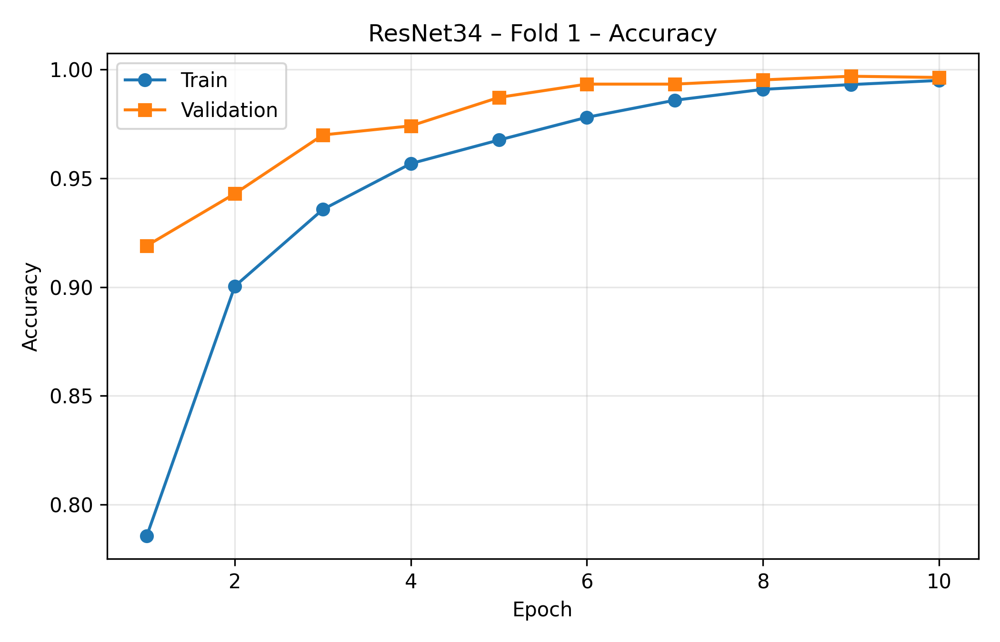

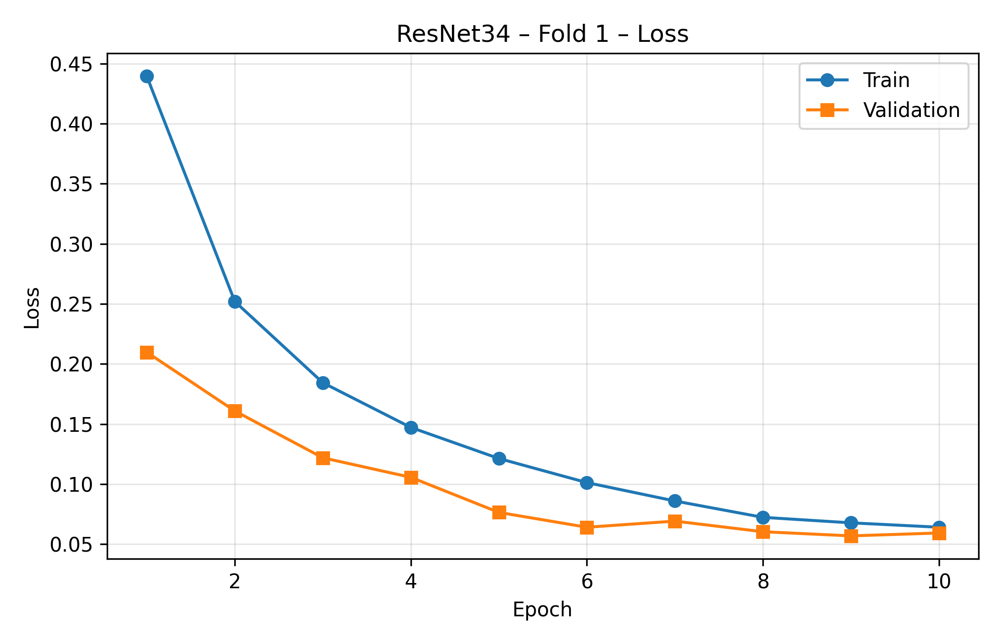

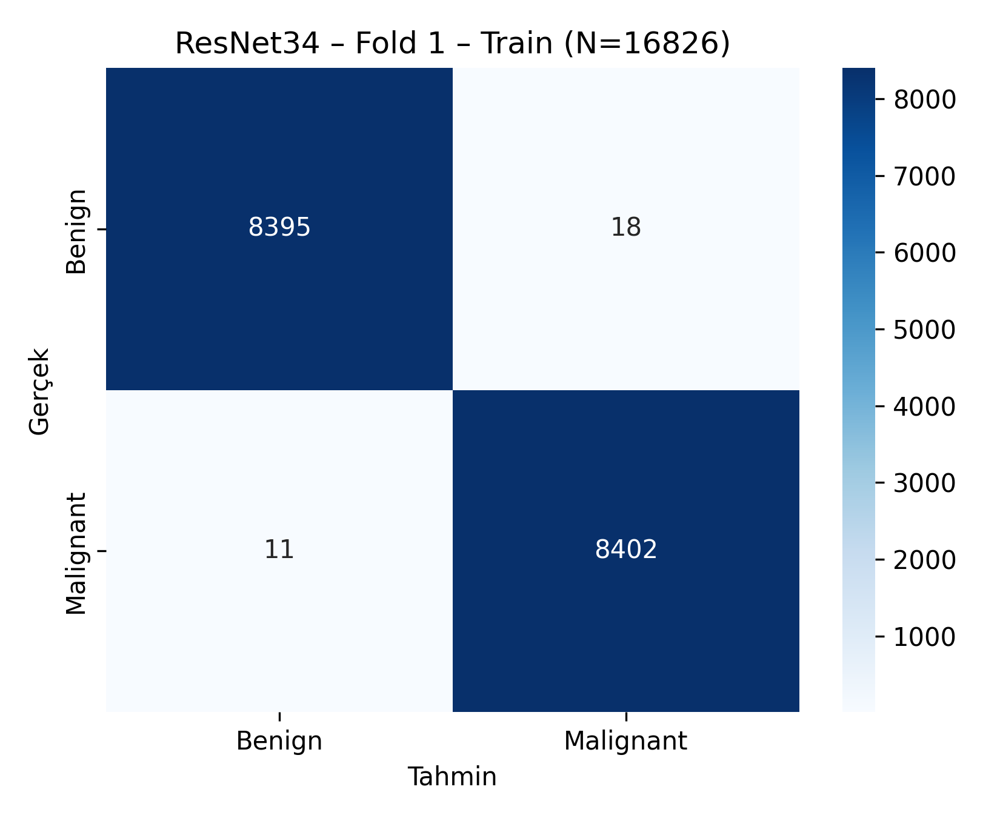

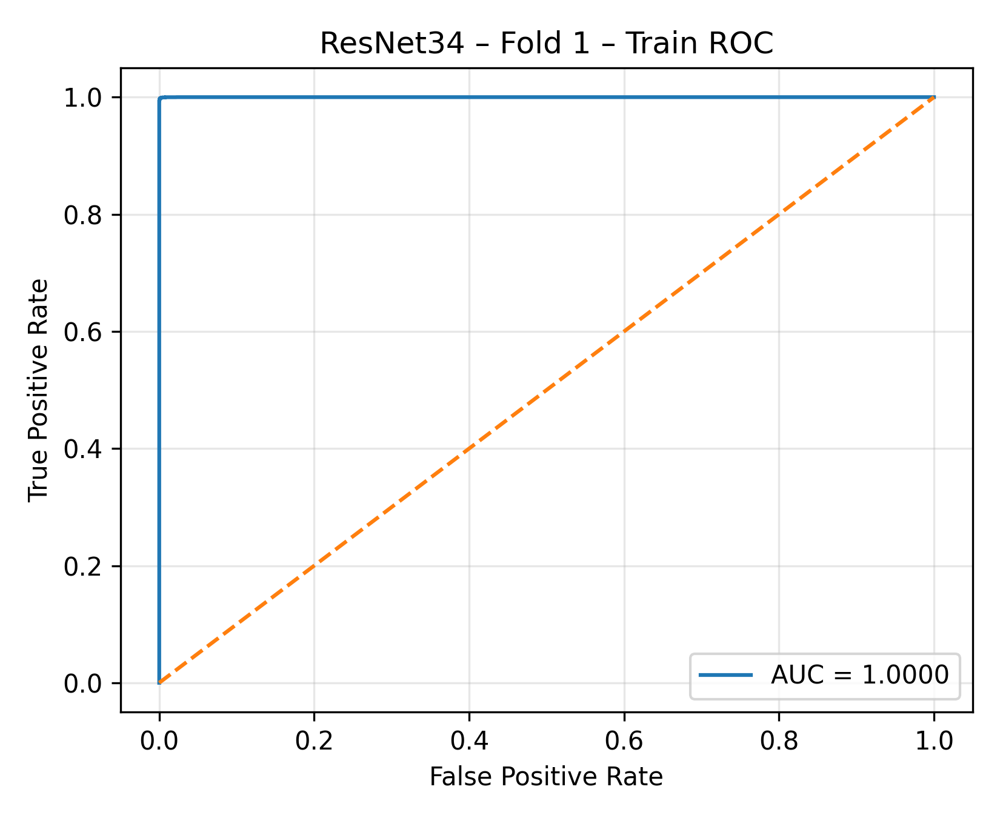

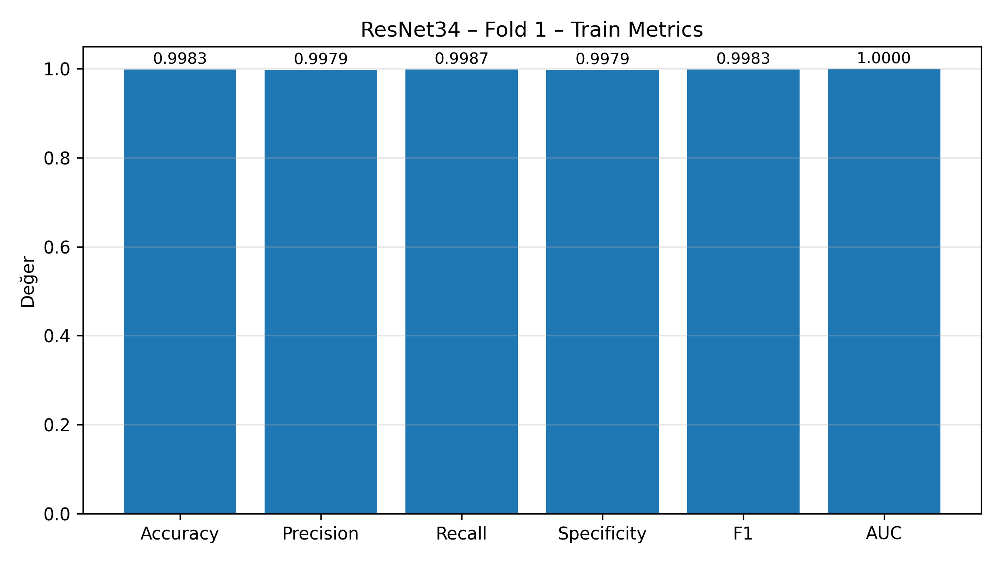

...

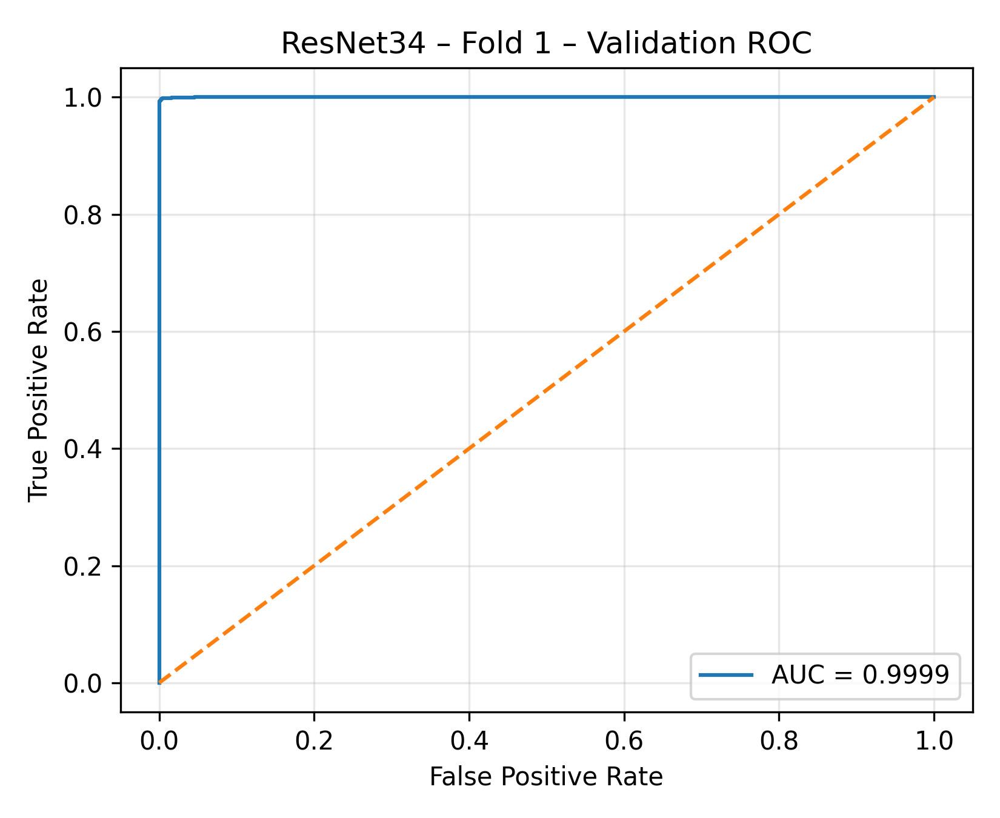

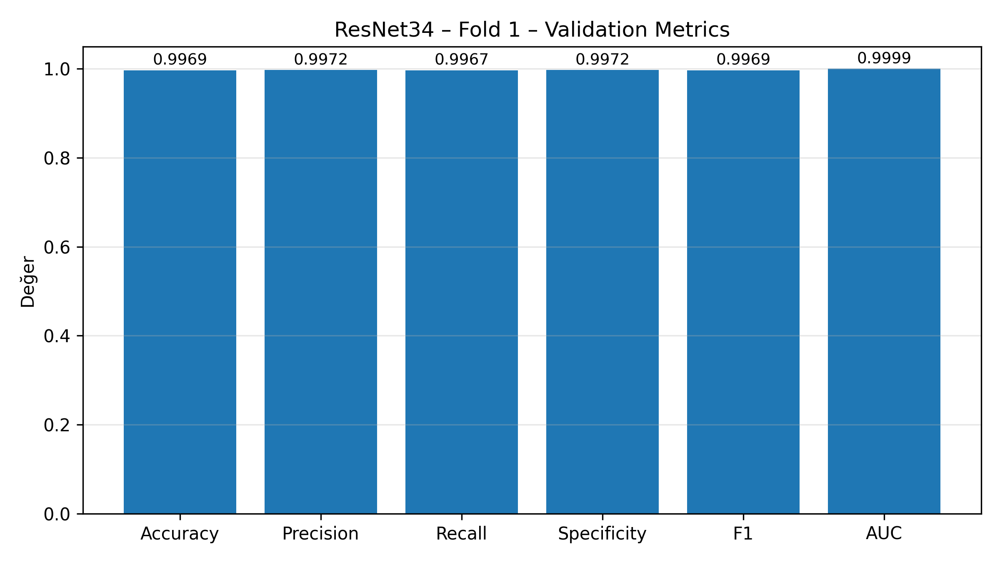

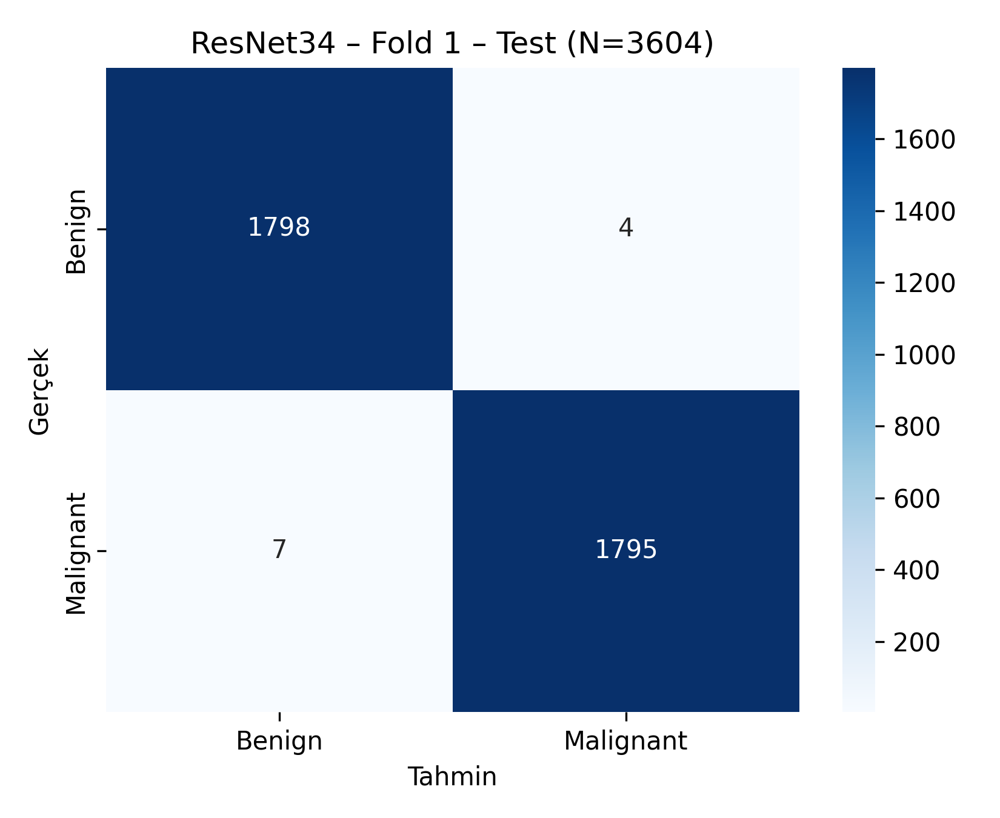

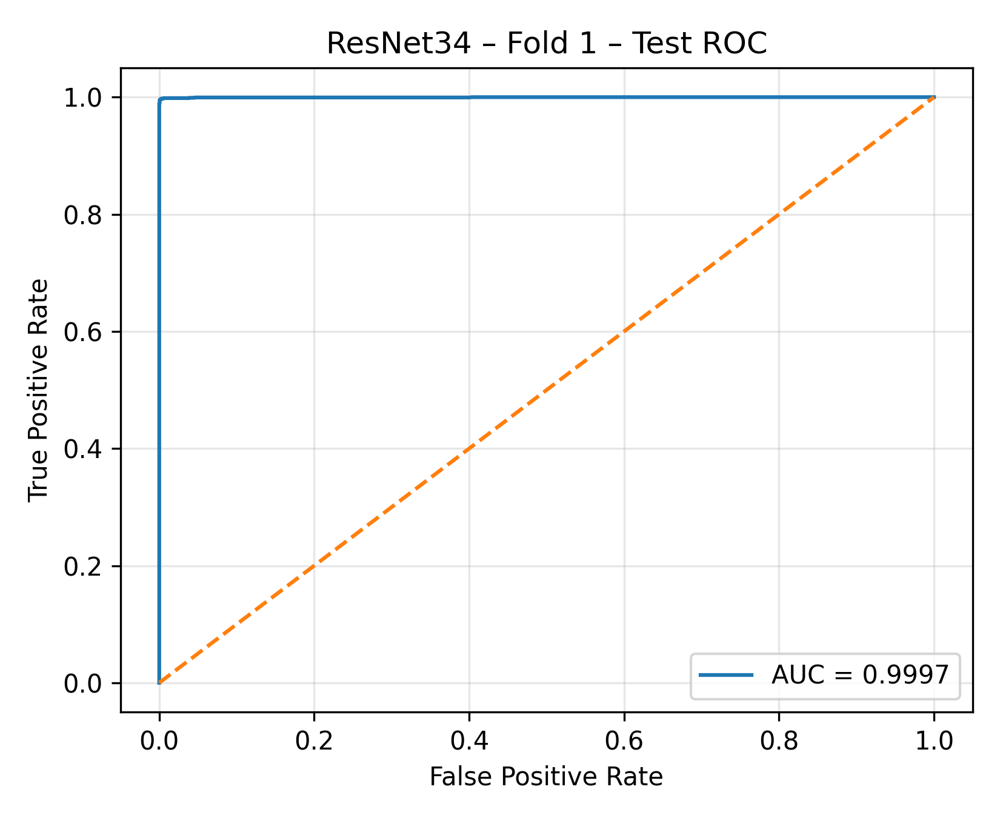

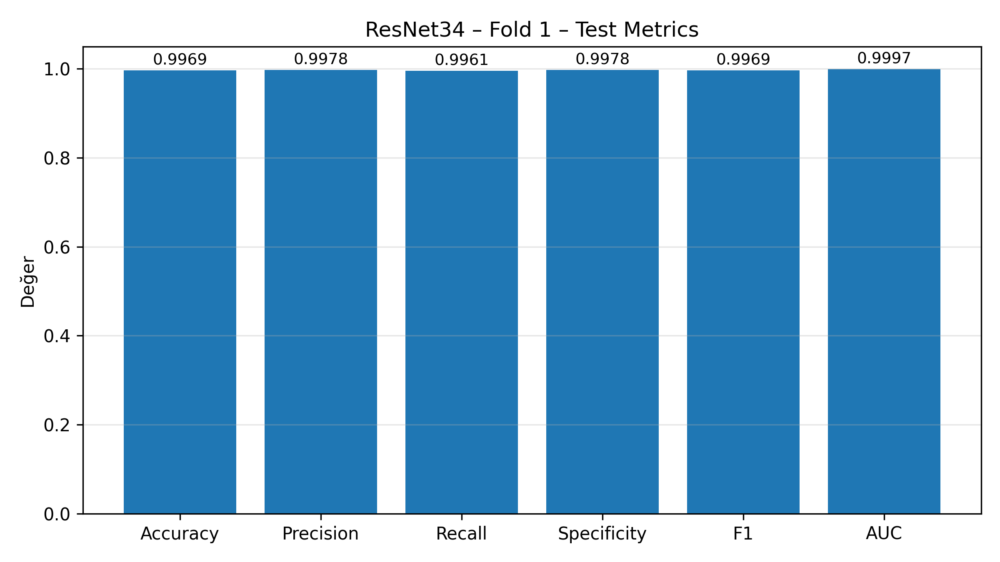

ResNet34 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8395.0,18.0,11.0,8402.0,0.998276,0.997862,0.998692,0.997860,0.998277,0.999989,0.052932
Validation,3594.0,1792.0,5.0,6.0,1791.0,0.996939,0.997216,0.996661,0.997218,0.996938,0.999935,0.056900
Test,3604.0,1798.0,4.0,7.0,1795.0,0.996948,0.997777,0.996115,0.997780,0.996945,0.999718,0.056018


✓ ResNet34 Fold 1: best epoch 9 | Test acc 0.9969
[atlandı] ResNet34 Fold 2 zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor
ResNet34 | Fold 2 | Epoch 01/10 | Train loss 0.4549 acc 0.7745 | Val loss 0.2256 acc 0.9179
ResNet34 | Fold 2 | Epoch 02/10 | Train loss 0.2599 acc 0.8943 | Val loss 0.1581 acc 0.9485
ResNet34 | Fold 2 | Epoch 03/10 | Train loss 0.1900 acc 0.9340 | Val loss 0.1329 acc 0.9574
ResNet34 | Fold 2 | Epoch 04/10 | Train loss 0.1507 acc 0.9541 | Val loss 0.1117 acc 0.9669
ResNet34 | Fold 2 | Epoch 05/10 | Train loss 0.1263 acc 0.9667 | Val loss 0.0843 acc 0.9844
ResNet34 | Fold 2 | Epoch 06/10 | Train loss 0.1028 acc 0.9778 | Val loss 0.0846 acc 0.9825
ResNet34 | Fold 2 | Epoch 07/10 | Train loss 0.0868 acc 0.9844 | Val loss 0.0690 acc 0.9917
ResNet34 | Fold 2 | Epoch 08/10 | Train loss 0.0758 acc 0.9894 | Val loss 0.0658 acc 0.9953
ResNet34 | Fold 2 | Epoch 09/10 | Train loss 0.0693 acc 0.9925 | Val loss 0.0612 acc 0.9947
ResNet34 | Fold 2 | Epoch 10/10 | Trai

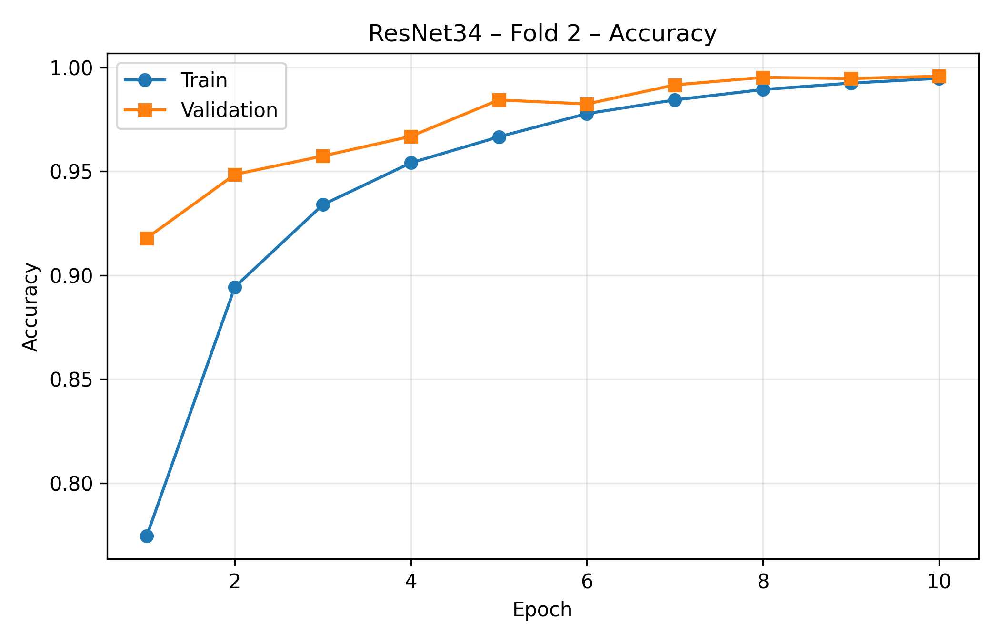

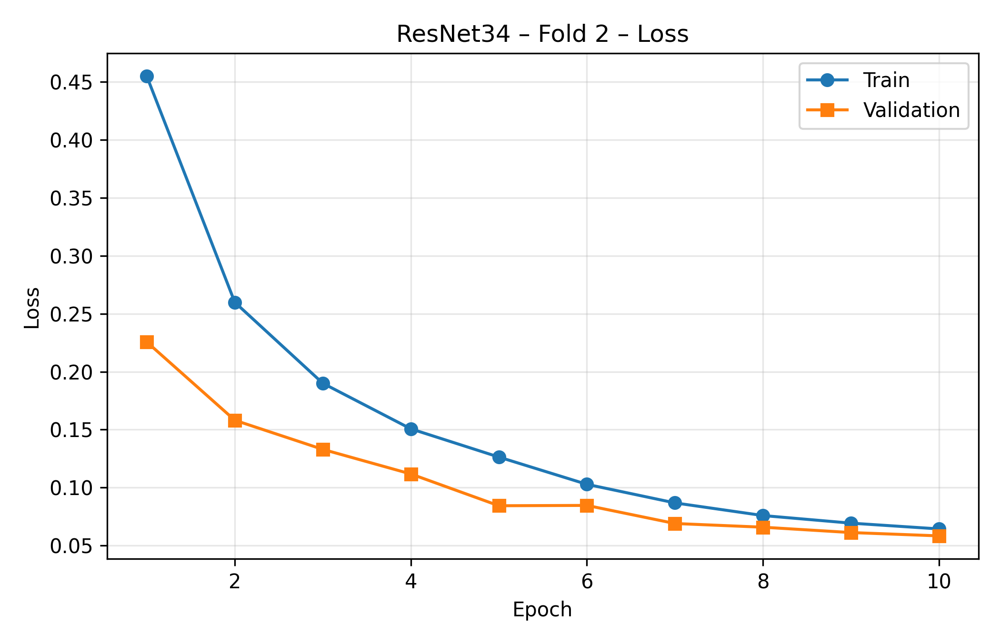

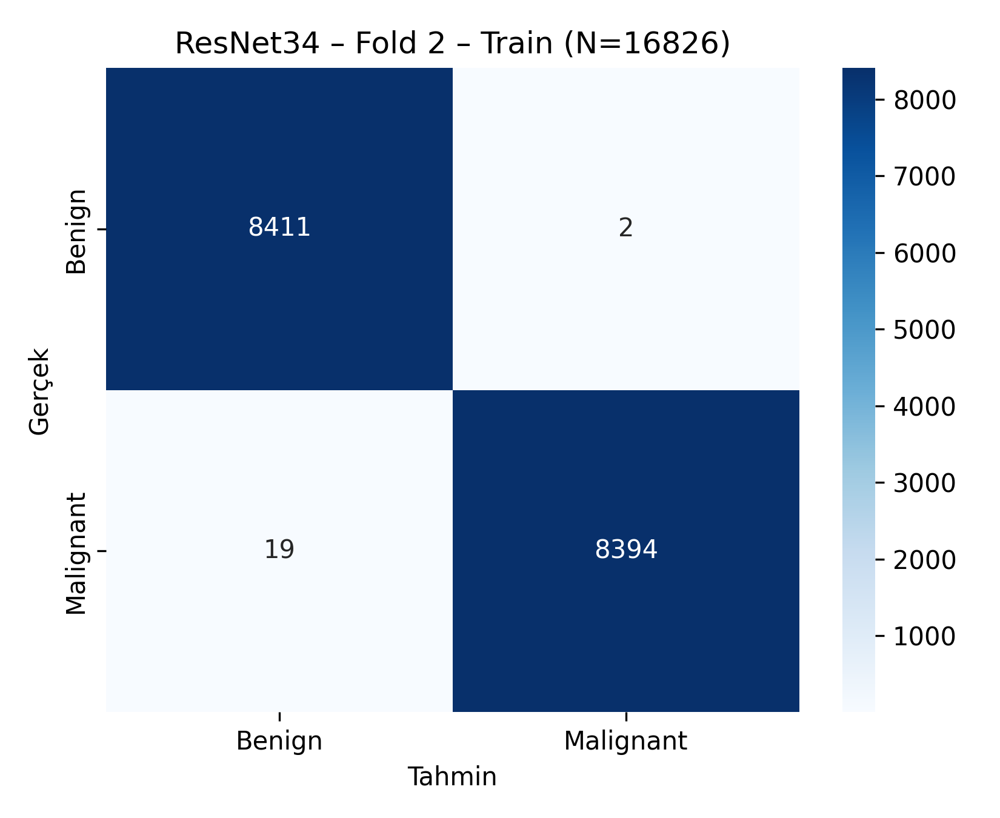

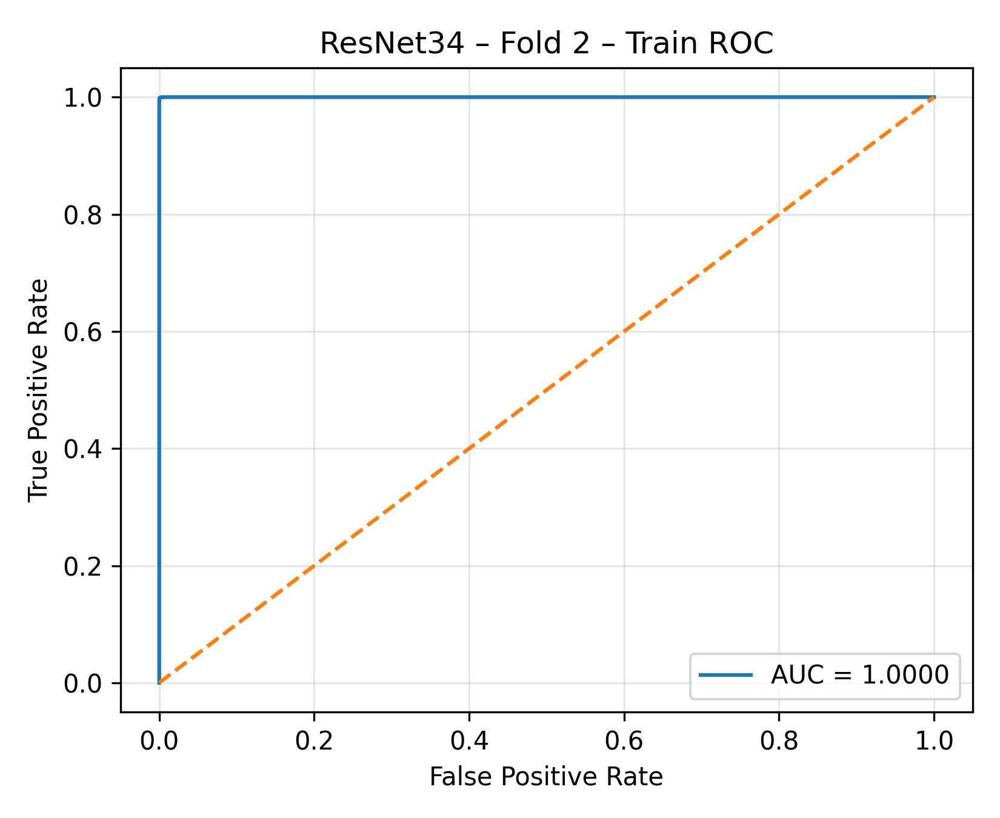

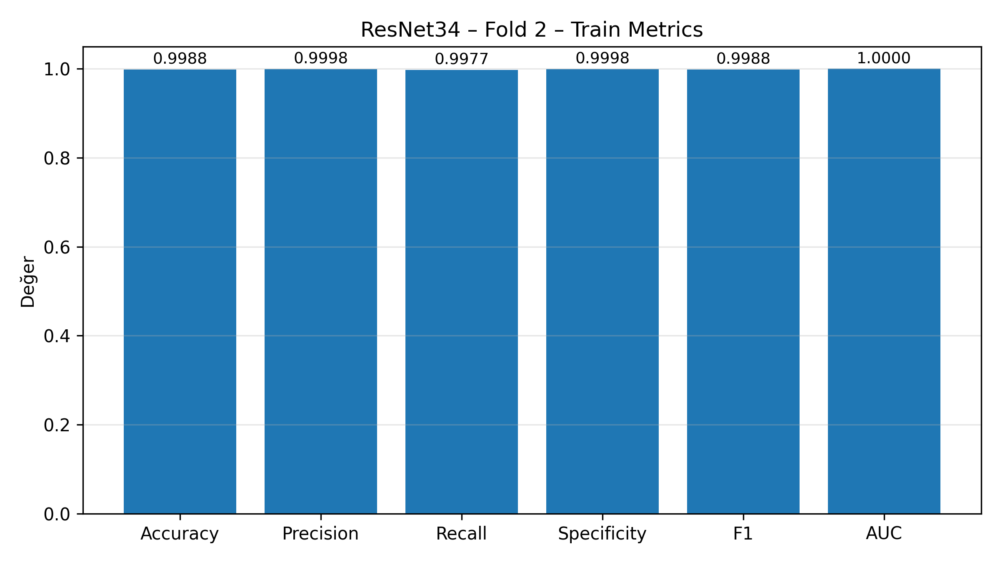

...

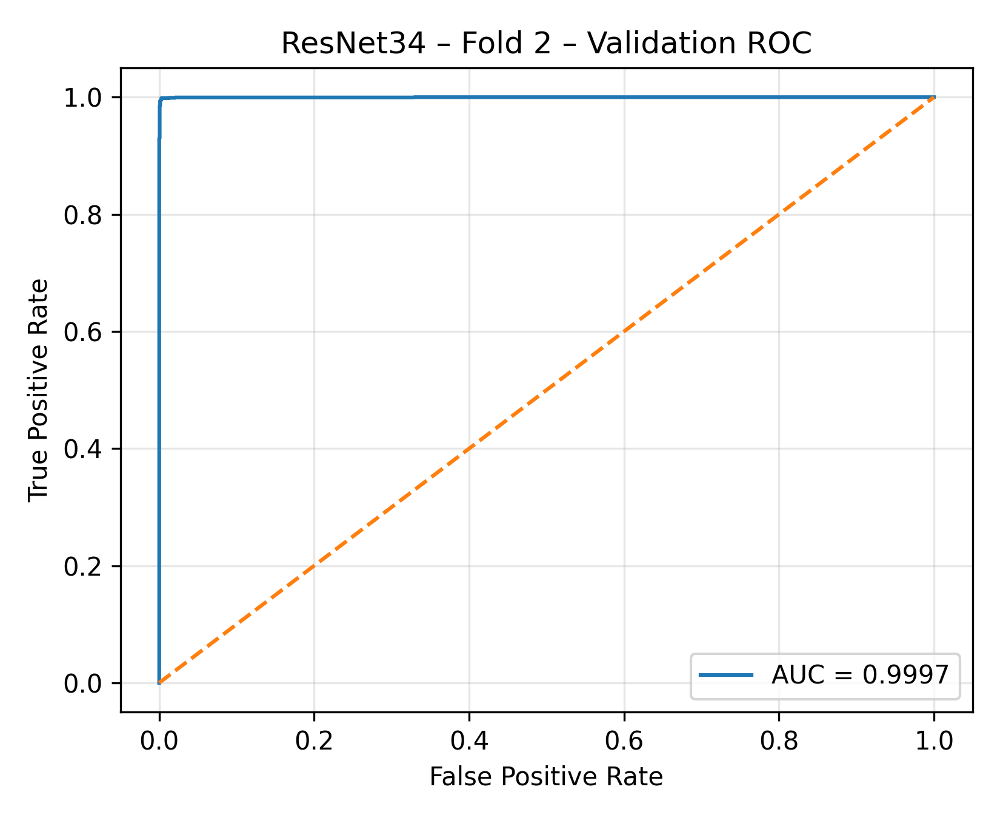

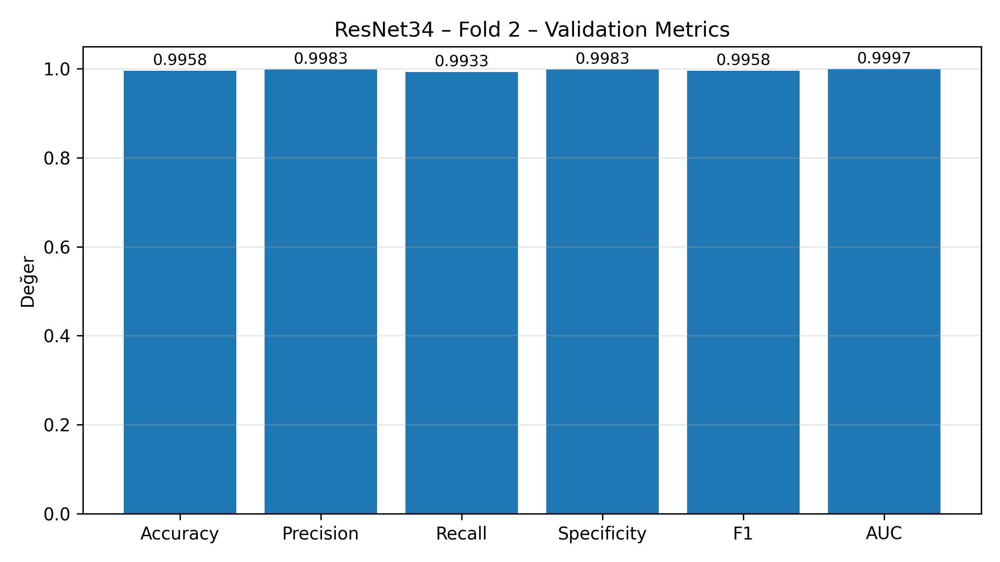

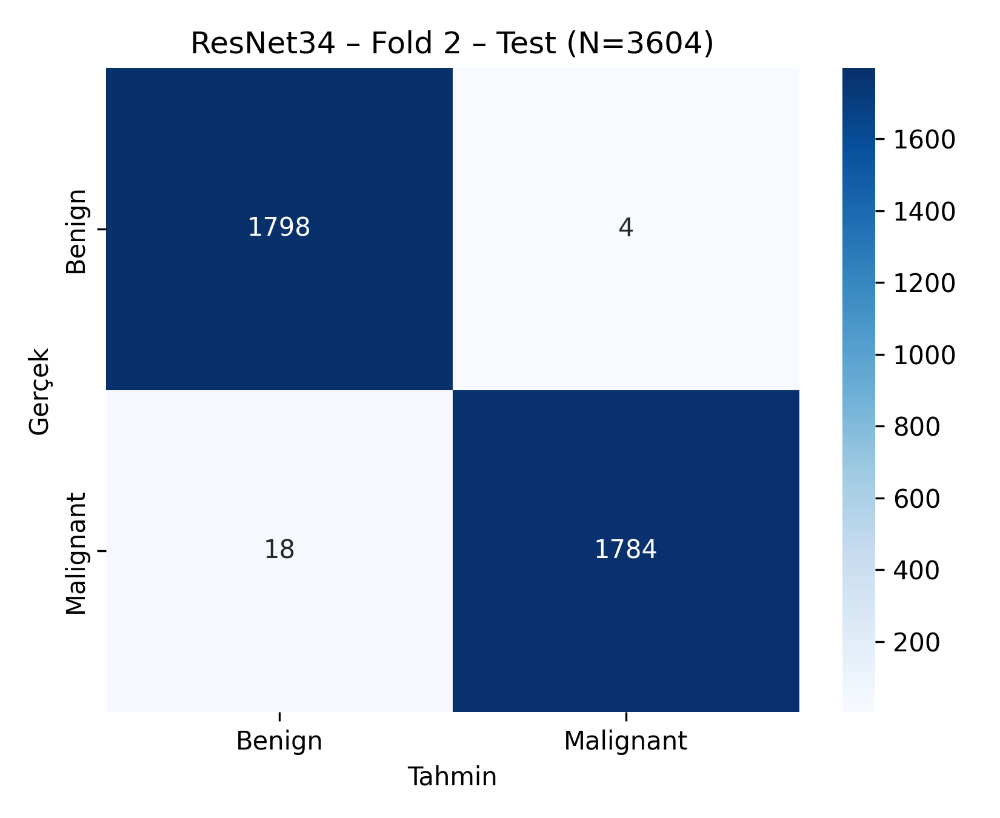

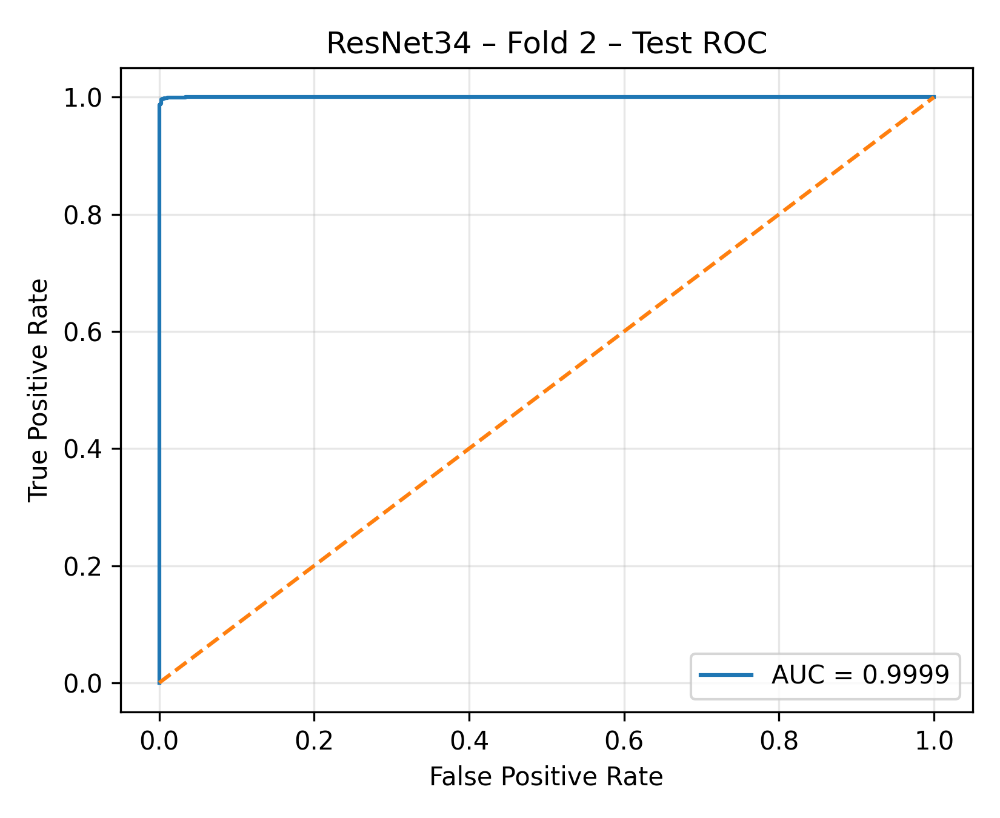

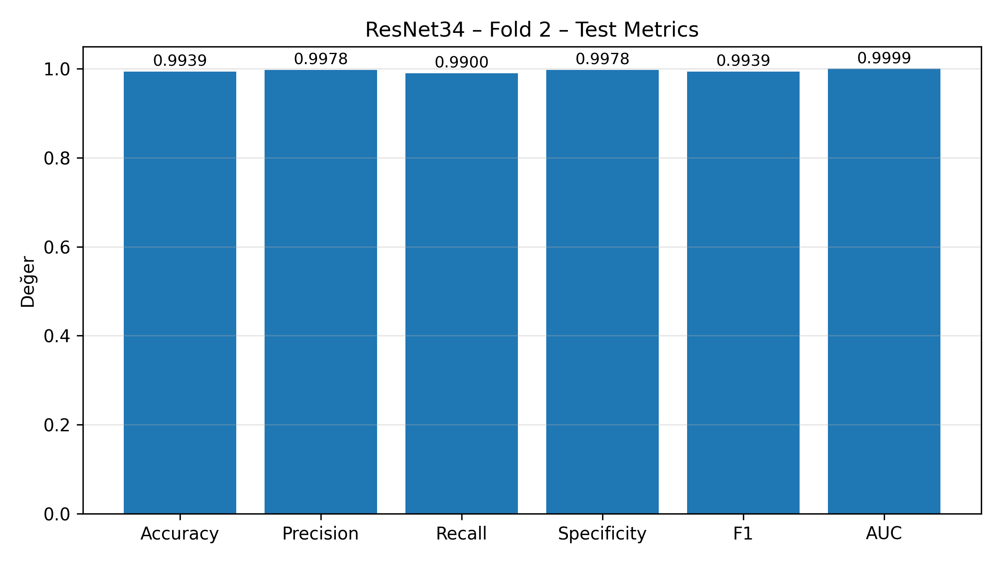

ResNet34 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8411.0,2.0,19.0,8394.0,0.998752,0.999762,0.997742,0.999762,0.998751,0.999995,0.053045
Validation,3594.0,1794.0,3.0,12.0,1785.0,0.995826,0.998322,0.993322,0.998331,0.995816,0.999747,0.058291
Test,3604.0,1798.0,4.0,18.0,1784.0,0.993896,0.997763,0.990011,0.997780,0.993872,0.999936,0.060941


✓ ResNet34 Fold 2: best epoch 10 | Test acc 0.9939
[atlandı] ResNet34 Fold 3 zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor
ResNet34 | Fold 3 | Epoch 01/10 | Train loss 0.4485 acc 0.7780 | Val loss 0.2241 acc 0.9090
ResNet34 | Fold 3 | Epoch 02/10 | Train loss 0.2588 acc 0.8936 | Val loss 0.2734 acc 0.8862
ResNet34 | Fold 3 | Epoch 03/10 | Train loss 0.1886 acc 0.9332 | Val loss 0.1309 acc 0.9580
ResNet34 | Fold 3 | Epoch 04/10 | Train loss 0.1519 acc 0.9528 | Val loss 0.0987 acc 0.9814
ResNet34 | Fold 3 | Epoch 05/10 | Train loss 0.1217 acc 0.9673 | Val loss 0.0834 acc 0.9855
ResNet34 | Fold 3 | Epoch 06/10 | Train loss 0.1027 acc 0.9772 | Val loss 0.0663 acc 0.9911
ResNet34 | Fold 3 | Epoch 07/10 | Train loss 0.0893 acc 0.9828 | Val loss 0.0684 acc 0.9878
ResNet34 | Fold 3 | Epoch 08/10 | Train loss 0.0753 acc 0.9899 | Val loss 0.0549 acc 0.9947
ResNet34 | Fold 3 | Epoch 09/10 | Train loss 0.0702 acc 0.9924 | Val loss 0.0584 acc 0.9961
ResNet34 | Fold 3 | Epoch 10/10 | Tra

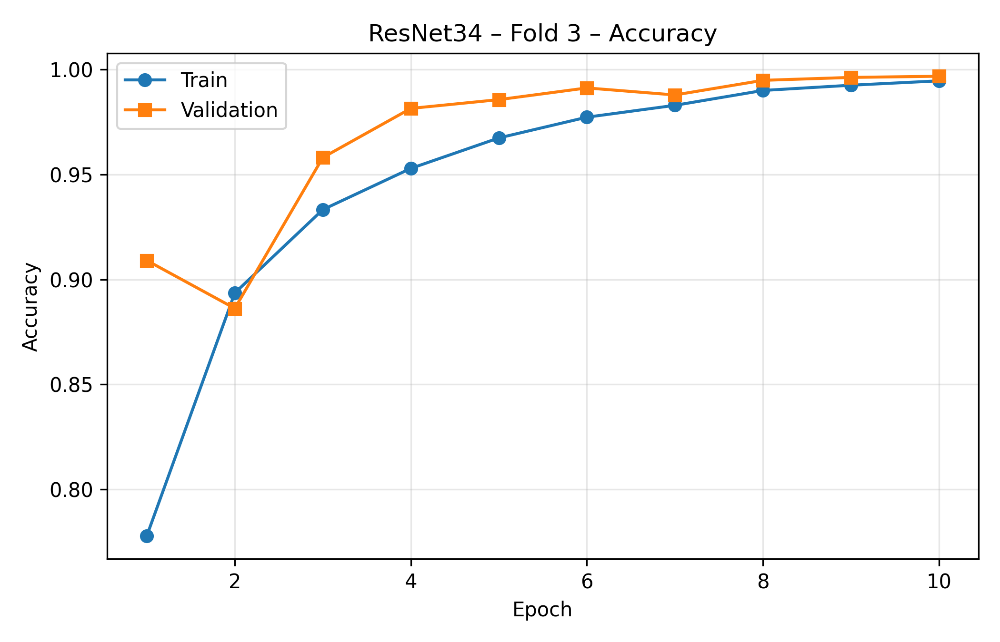

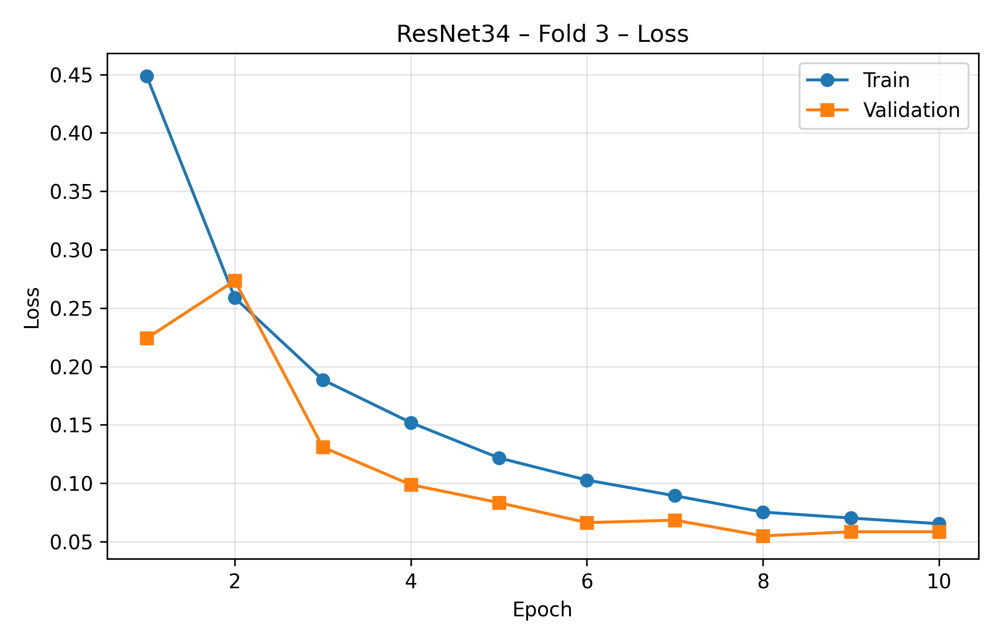

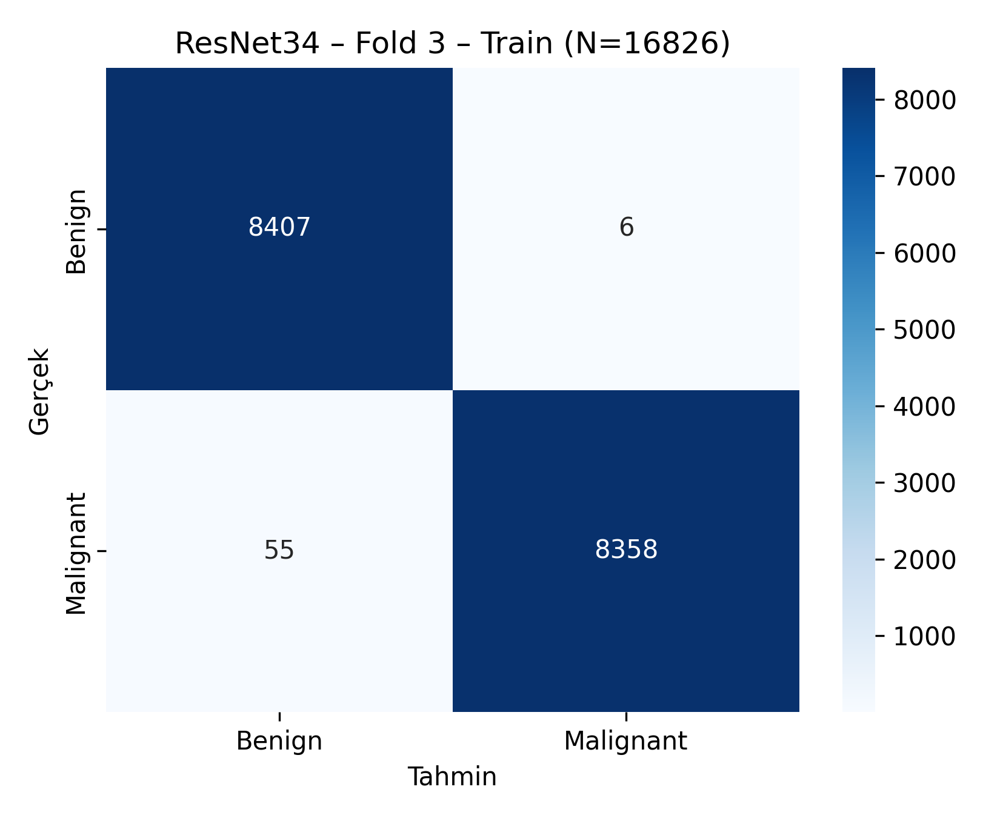

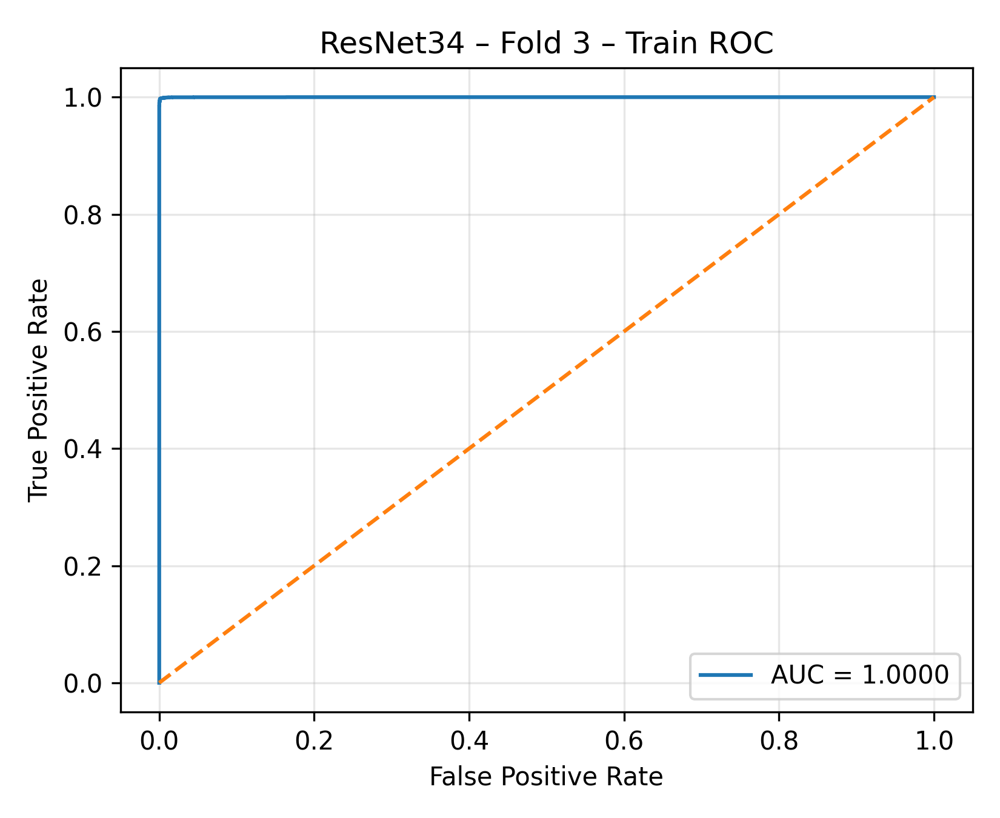

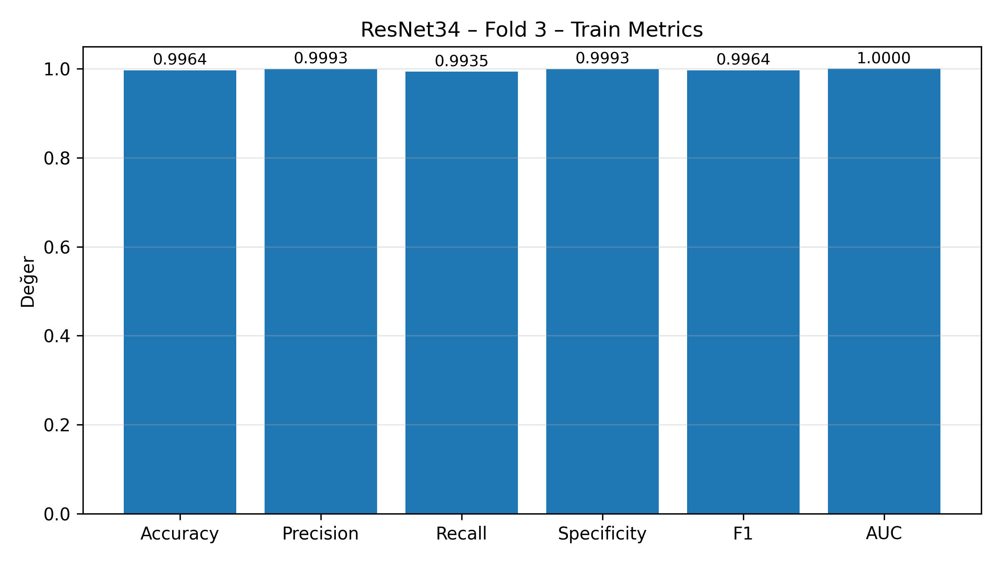

...

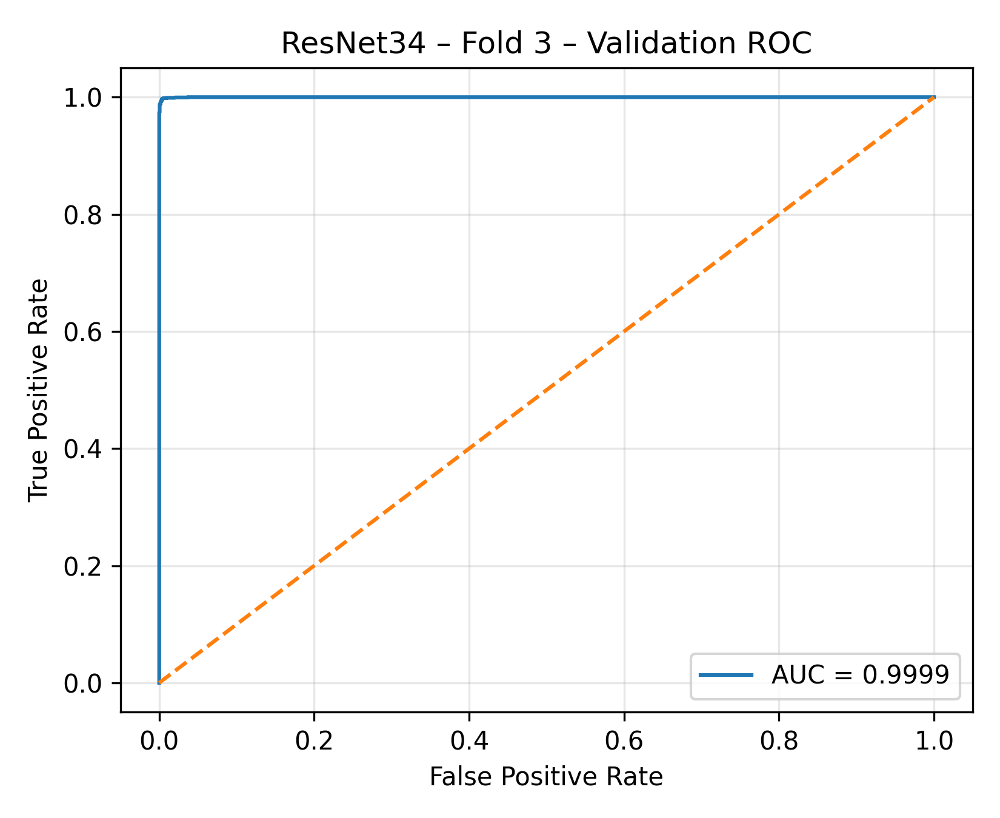

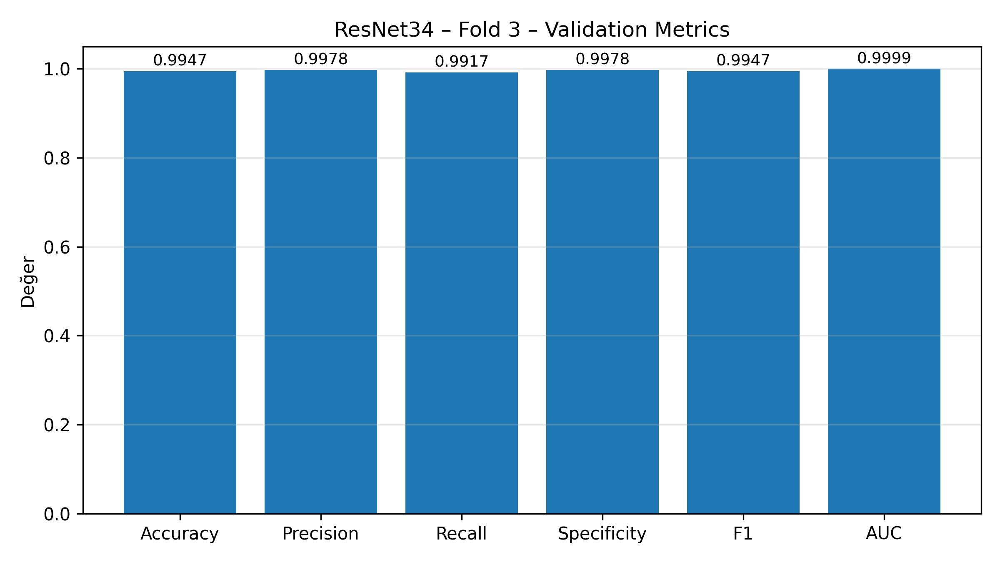

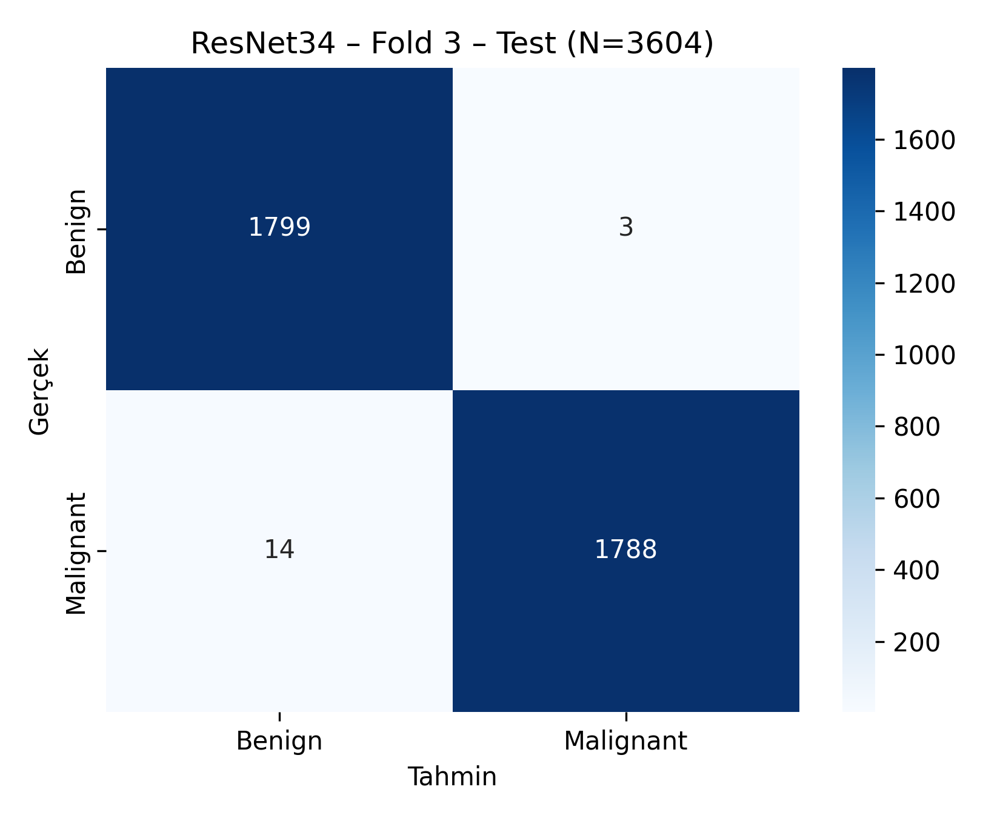

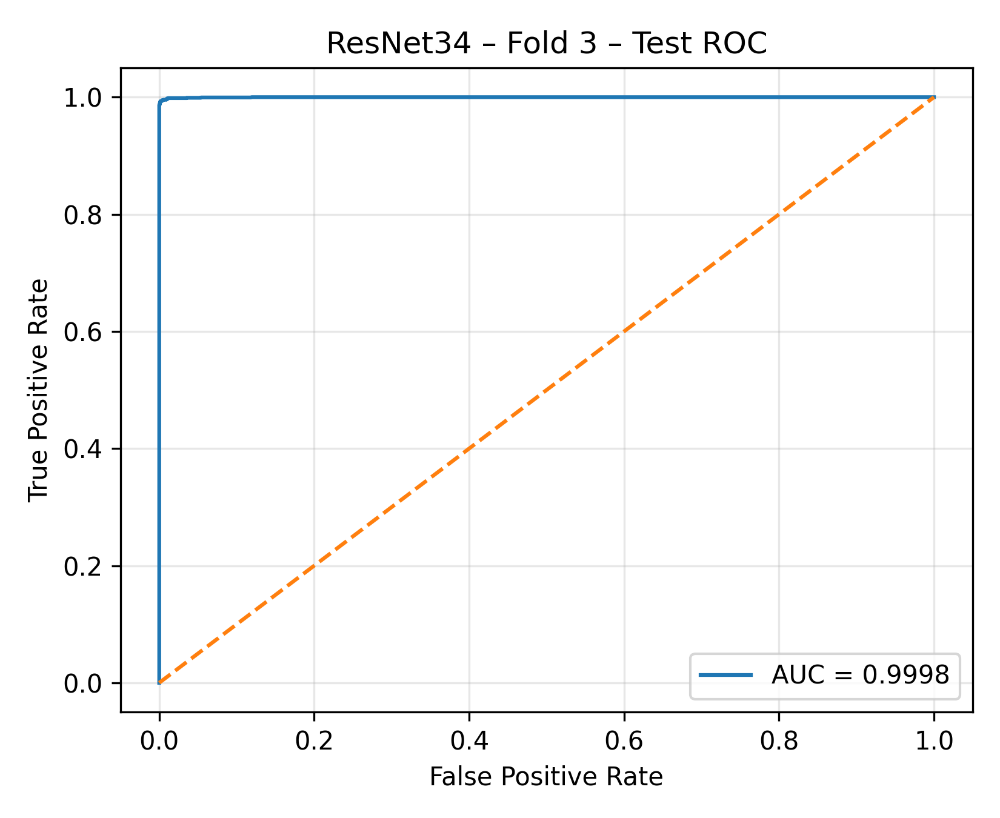

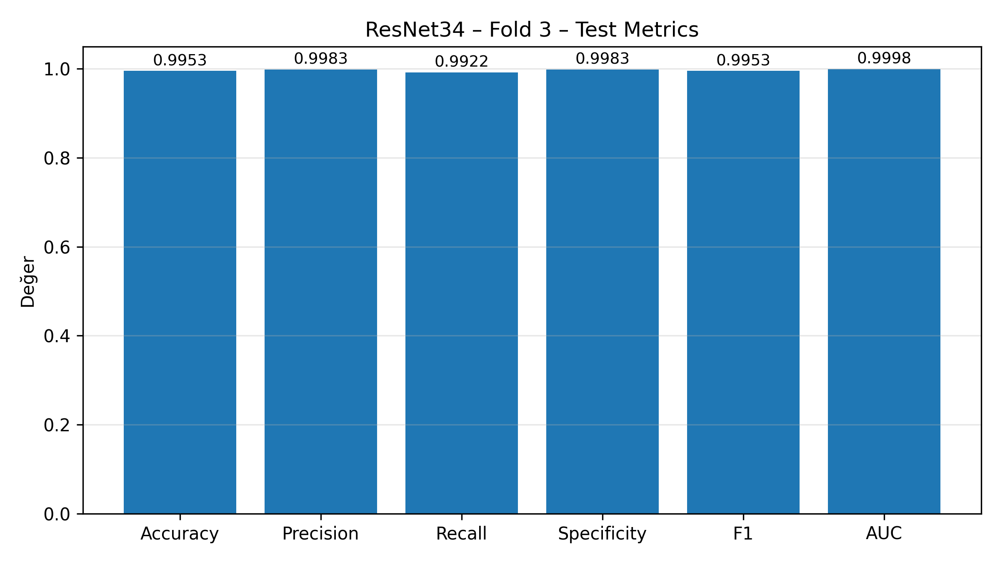

ResNet34 – Fold 3 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8407.0,6.0,55.0,8358.0,0.996375,0.999283,0.993462,0.999287,0.996364,0.999956,0.052455
Validation,3594.0,1793.0,4.0,15.0,1782.0,0.994713,0.997760,0.991653,0.997774,0.994697,0.999927,0.054905
Test,3604.0,1799.0,3.0,14.0,1788.0,0.995283,0.998325,0.992231,0.998335,0.995269,0.999840,0.056687


✓ ResNet34 Fold 3: best epoch 8 | Test acc 0.9953
[atlandı] ResNet34 Fold 4 zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor
ResNet34 | Fold 4 | Epoch 01/10 | Train loss 0.4608 acc 0.7667 | Val loss 0.2436 acc 0.8979
ResNet34 | Fold 4 | Epoch 02/10 | Train loss 0.2615 acc 0.8952 | Val loss 0.2088 acc 0.9151
ResNet34 | Fold 4 | Epoch 03/10 | Train loss 0.1886 acc 0.9339 | Val loss 0.1317 acc 0.9583
ResNet34 | Fold 4 | Epoch 04/10 | Train loss 0.1509 acc 0.9542 | Val loss 0.1060 acc 0.9713
ResNet34 | Fold 4 | Epoch 05/10 | Train loss 0.1277 acc 0.9649 | Val loss 0.0894 acc 0.9811
ResNet34 | Fold 4 | Epoch 06/10 | Train loss 0.1032 acc 0.9772 | Val loss 0.0758 acc 0.9861
ResNet34 | Fold 4 | Epoch 07/10 | Train loss 0.0907 acc 0.9835 | Val loss 0.0671 acc 0.9919
ResNet34 | Fold 4 | Epoch 08/10 | Train loss 0.0764 acc 0.9895 | Val loss 0.0611 acc 0.9939
ResNet34 | Fold 4 | Epoch 09/10 | Train loss 0.0700 acc 0.9925 | Val loss 0.0591 acc 0.9939
ResNet34 | Fold 4 | Epoch 10/10 | Trai

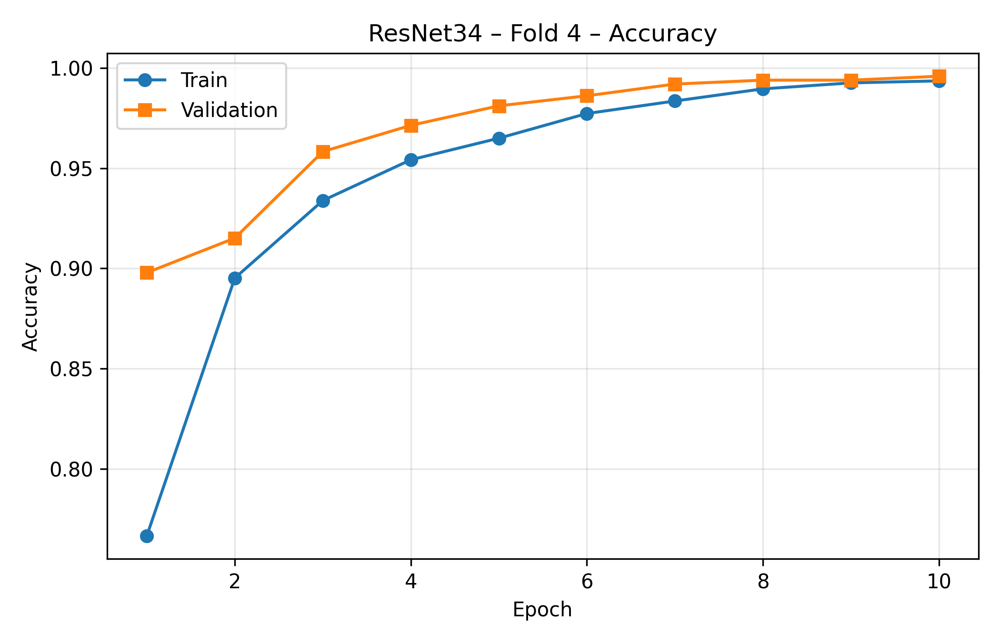

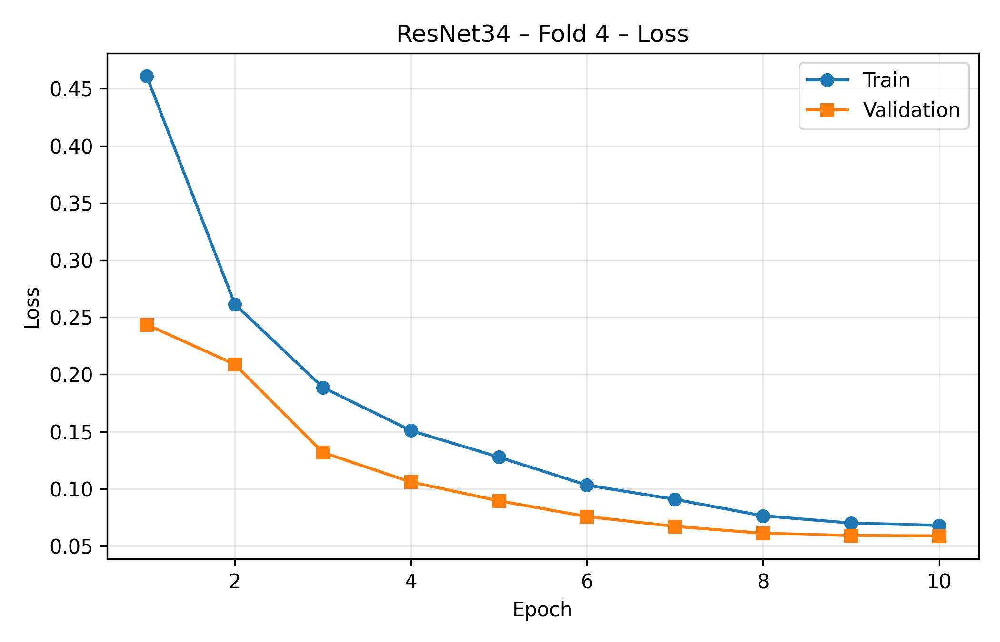

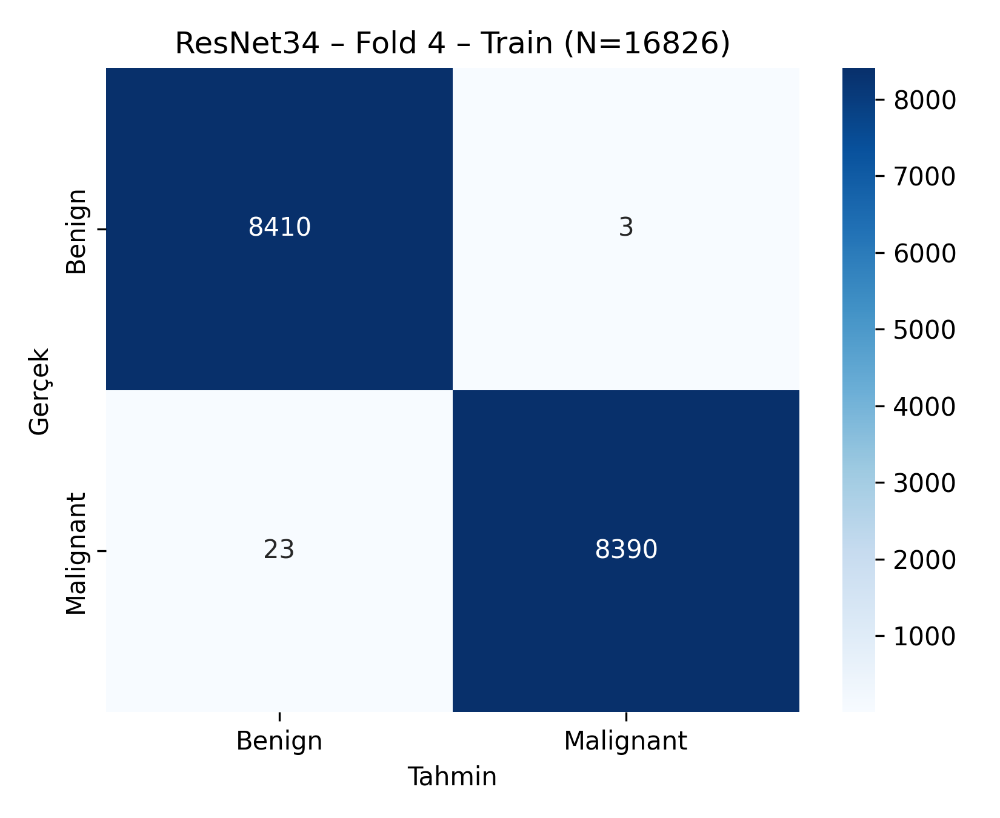

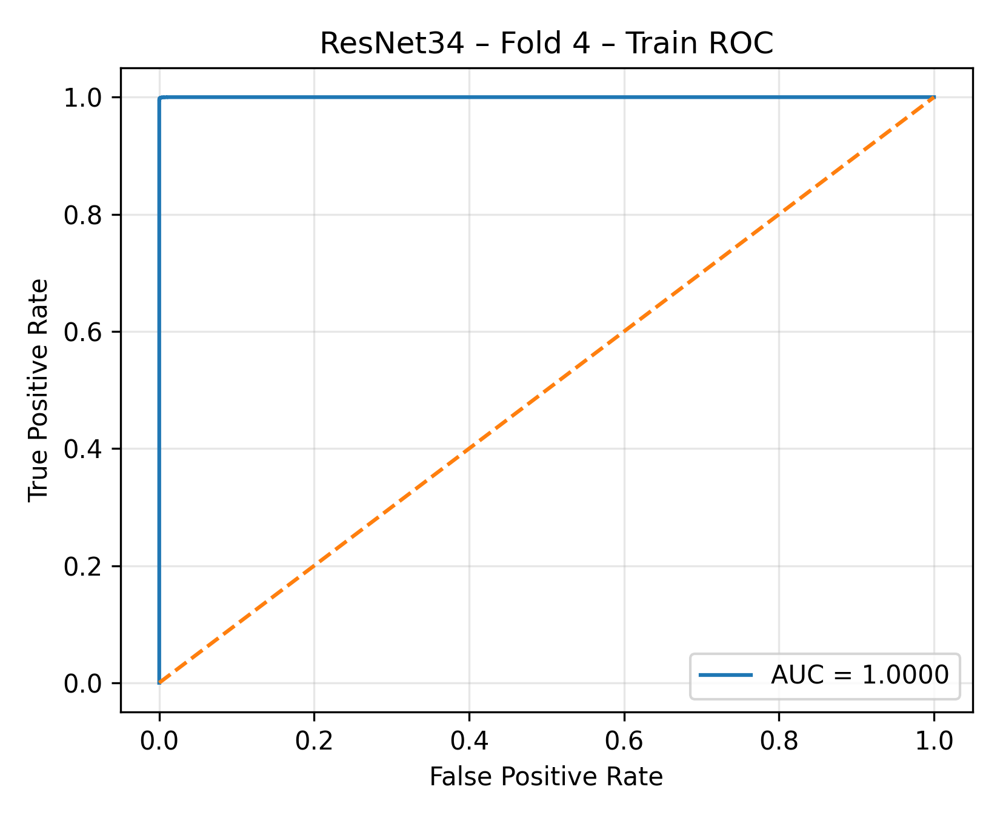

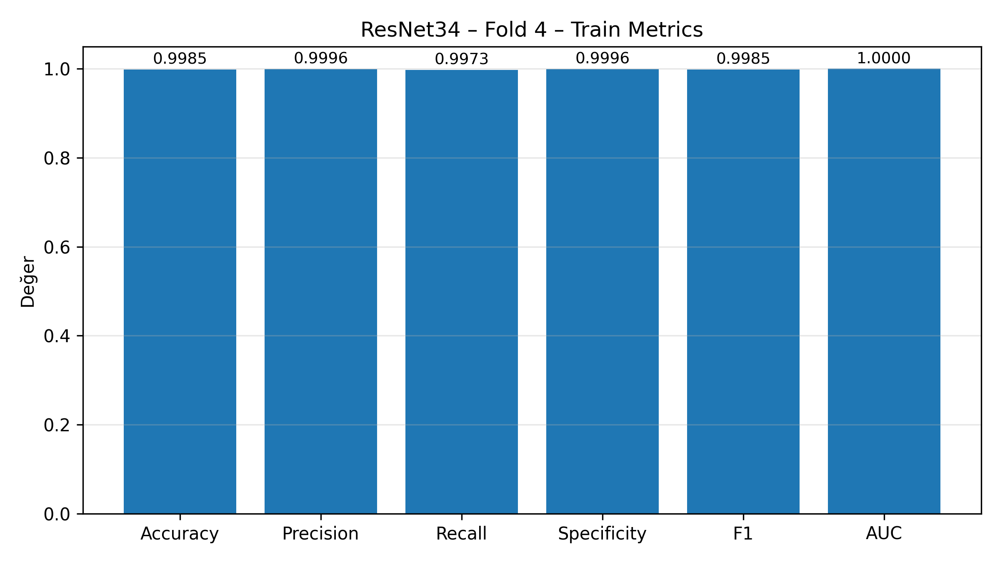

...

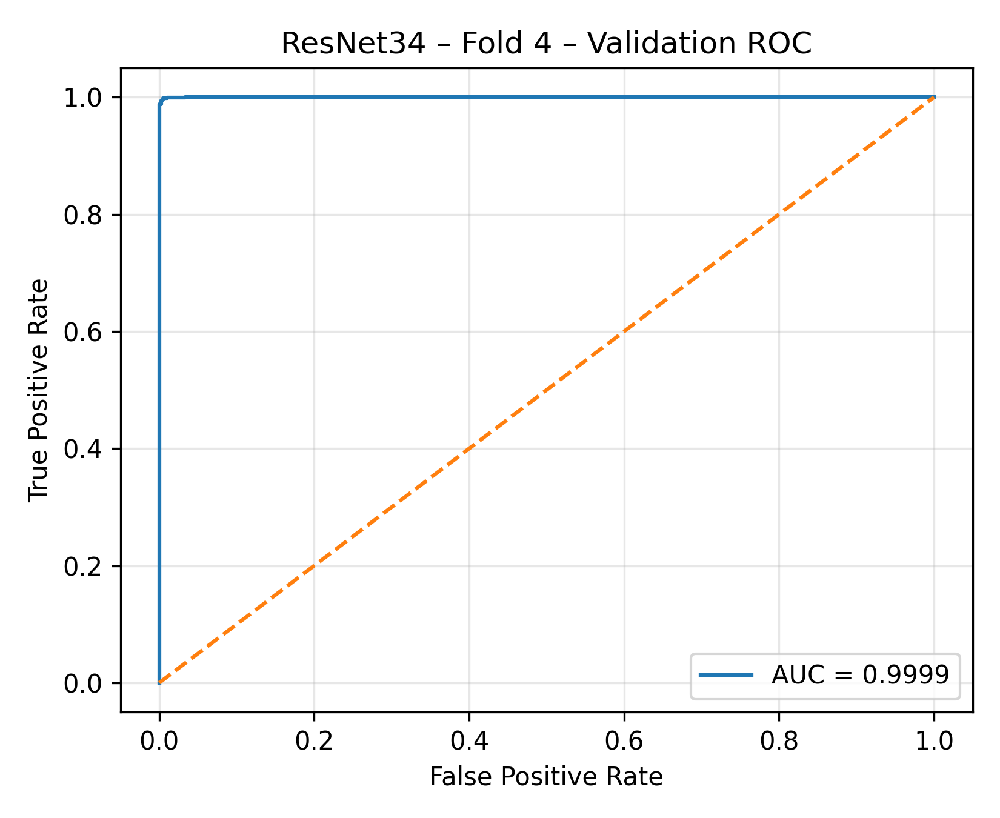

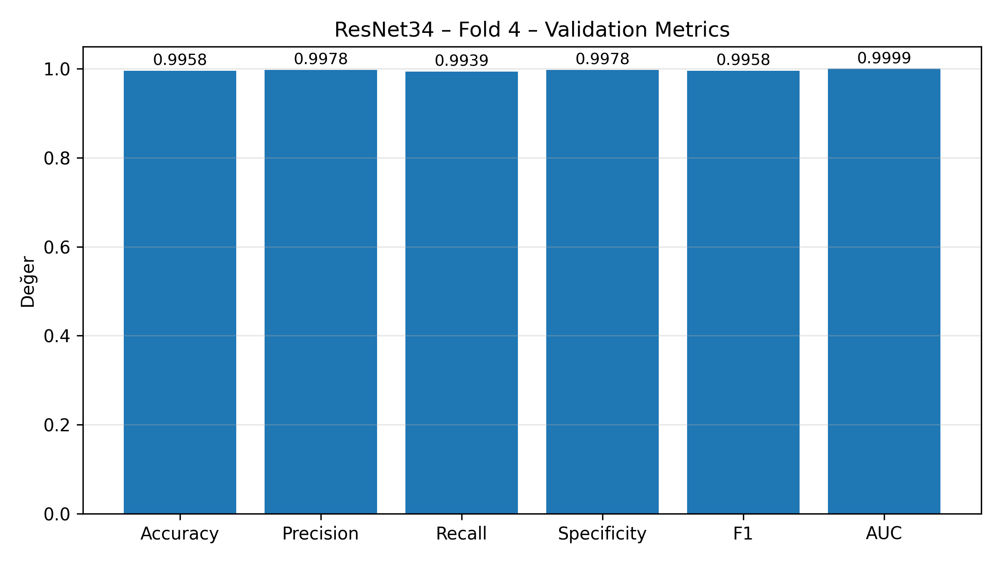

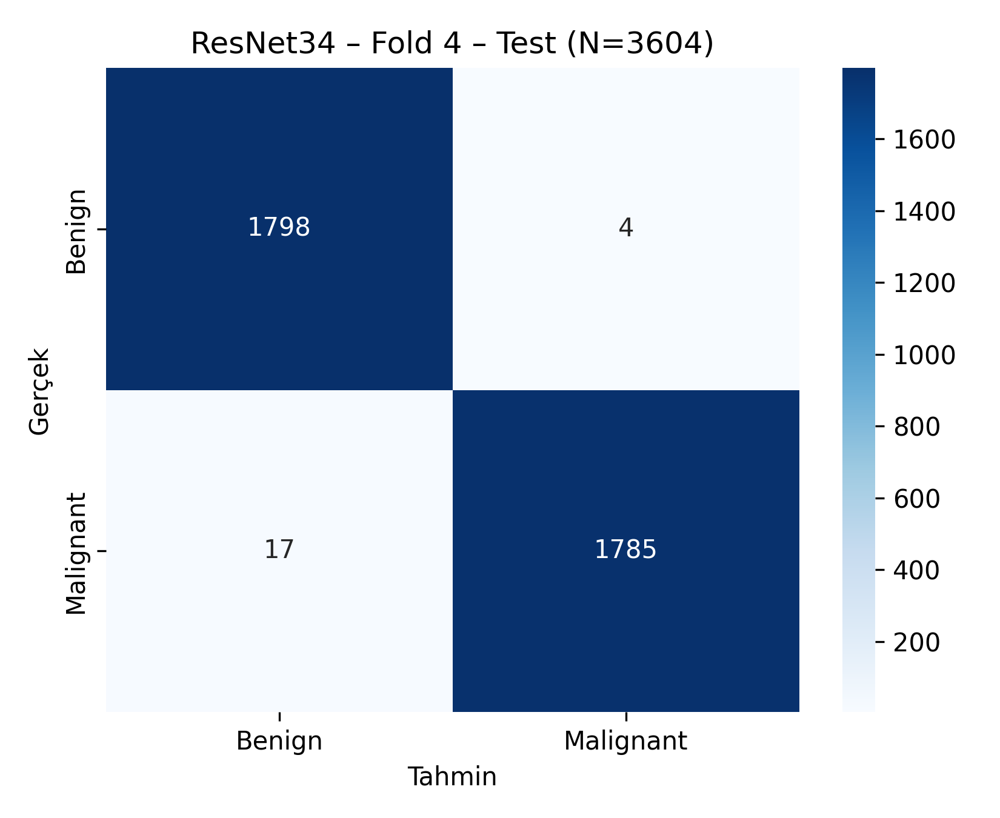

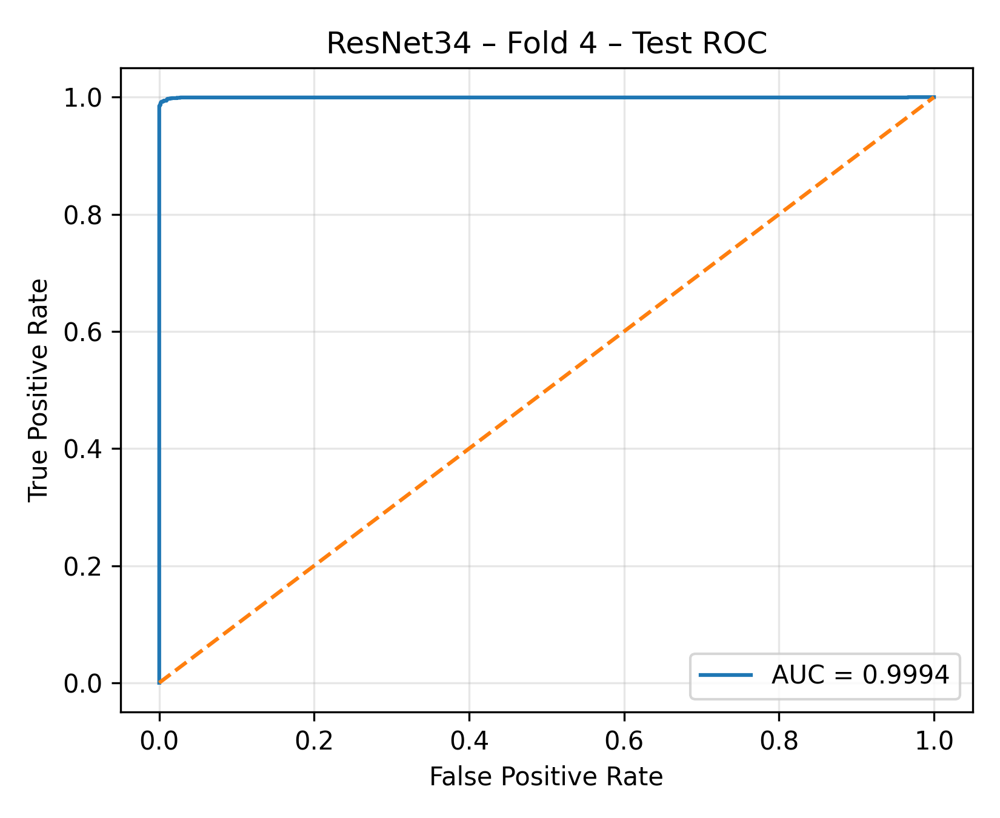

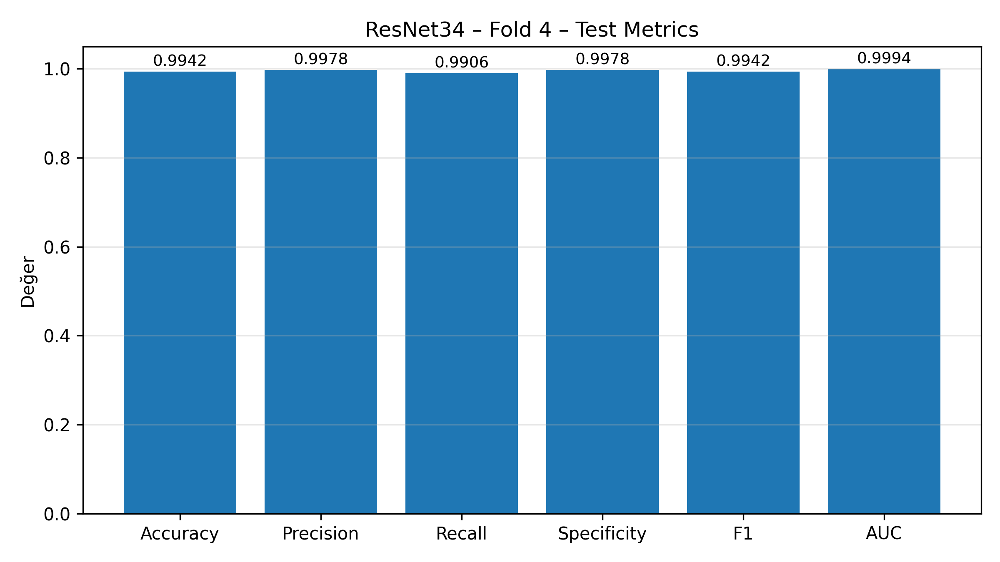

ResNet34 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8410.0,3.0,23.0,8390.0,0.998455,0.999643,0.997266,0.999643,0.998453,0.999994,0.052841
Validation,3594.0,1793.0,4.0,11.0,1786.0,0.995826,0.997765,0.993879,0.997774,0.995818,0.999931,0.058779
Test,3604.0,1798.0,4.0,17.0,1785.0,0.994173,0.997764,0.990566,0.997780,0.994152,0.999365,0.061705


✓ ResNet34 Fold 4: best epoch 10 | Test acc 0.9942
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 218MB/s]


ResNet34 | Fold 5 | Epoch 01/10 | Train loss 0.4540 acc 0.7695 | Val loss 0.2909 acc 0.8751
ResNet34 | Fold 5 | Epoch 02/10 | Train loss 0.2576 acc 0.8965 | Val loss 0.1864 acc 0.9307
ResNet34 | Fold 5 | Epoch 03/10 | Train loss 0.1916 acc 0.9316 | Val loss 0.1180 acc 0.9652
ResNet34 | Fold 5 | Epoch 04/10 | Train loss 0.1514 acc 0.9538 | Val loss 0.1036 acc 0.9738
ResNet34 | Fold 5 | Epoch 05/10 | Train loss 0.1216 acc 0.9681 | Val loss 0.0852 acc 0.9822
ResNet34 | Fold 5 | Epoch 06/10 | Train loss 0.1006 acc 0.9797 | Val loss 0.0828 acc 0.9850
ResNet34 | Fold 5 | Epoch 07/10 | Train loss 0.0865 acc 0.9848 | Val loss 0.0728 acc 0.9897
ResNet34 | Fold 5 | Epoch 08/10 | Train loss 0.0726 acc 0.9908 | Val loss 0.0665 acc 0.9919
ResNet34 | Fold 5 | Epoch 09/10 | Train loss 0.0704 acc 0.9918 | Val loss 0.0652 acc 0.9936
ResNet34 | Fold 5 | Epoch 10/10 | Train loss 0.0629 acc 0.9952 | Val loss 0.0639 acc 0.9942


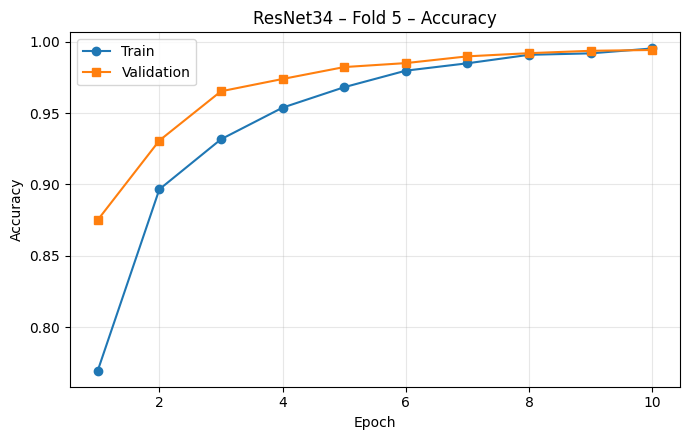

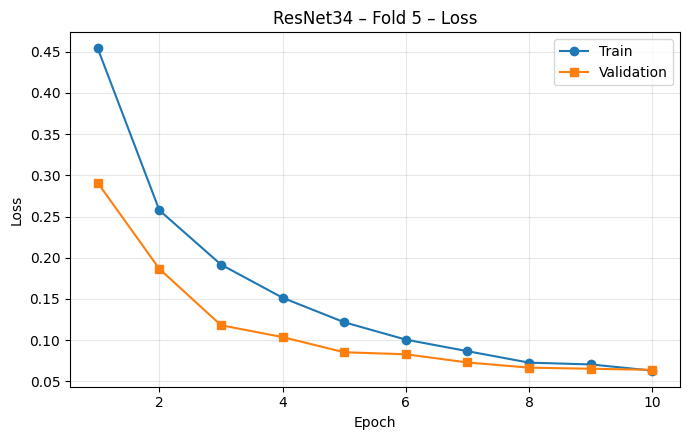

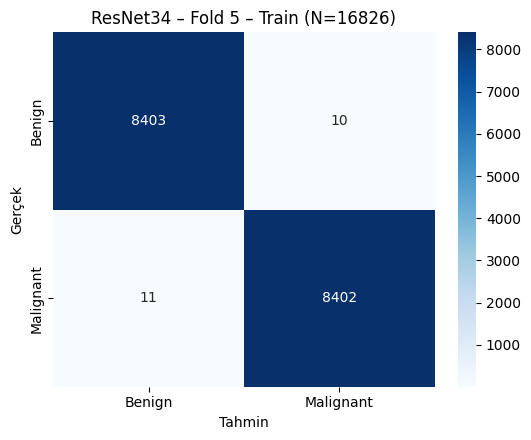

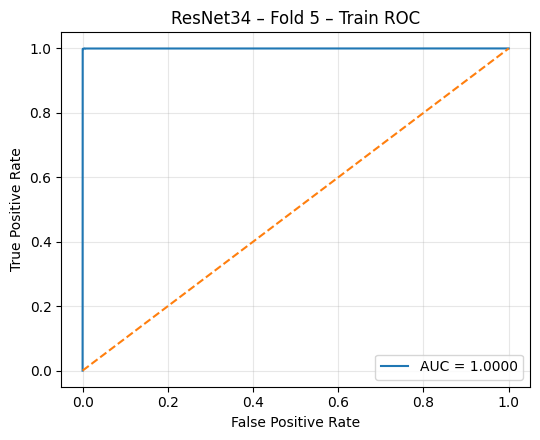

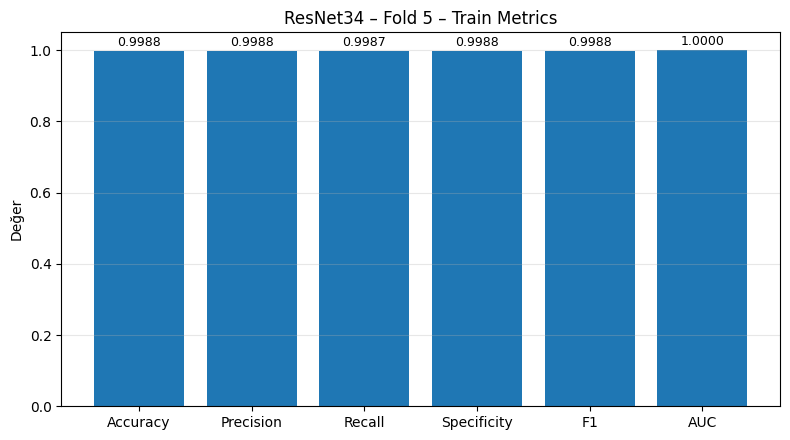

...

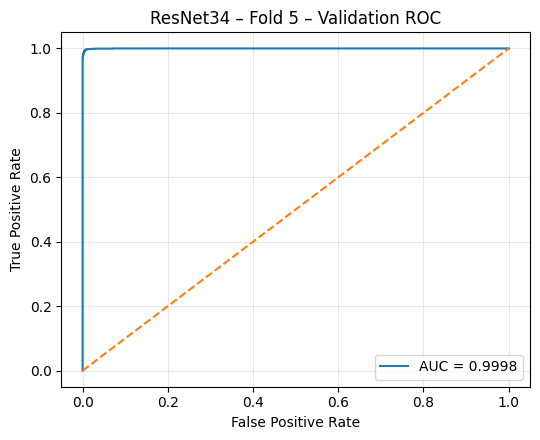

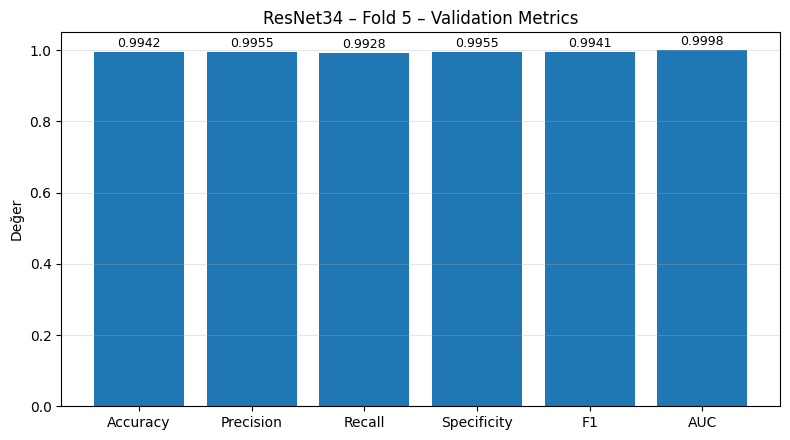

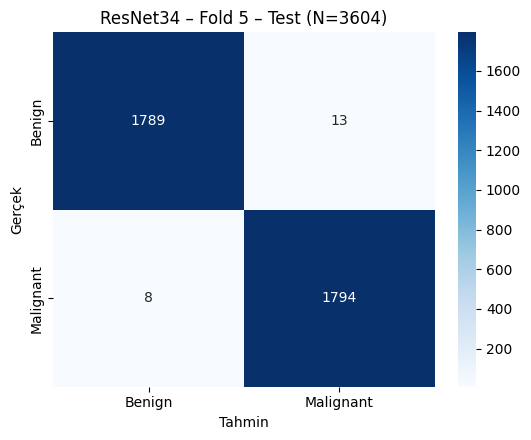

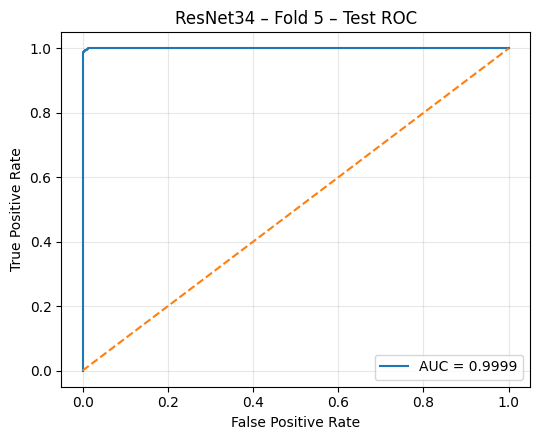

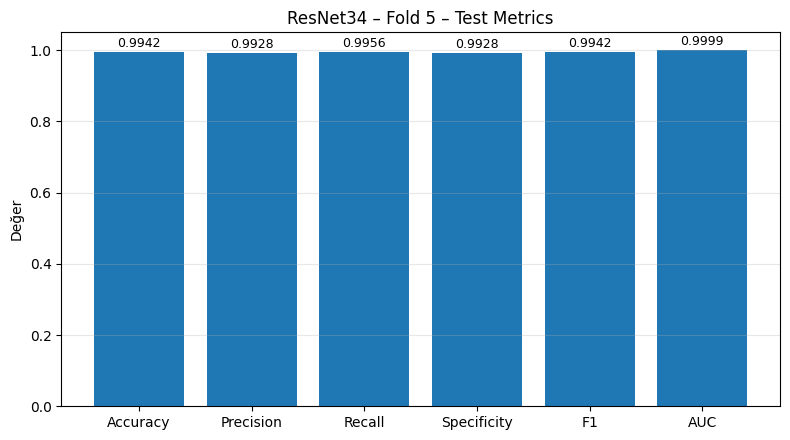

ResNet34 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8403.0,10.0,11.0,8402.0,0.998752,0.998811,0.998692,0.998811,0.998752,0.999990,0.053994
Validation,3594.0,1789.0,8.0,13.0,1784.0,0.994157,0.995536,0.992766,0.995548,0.994149,0.999842,0.063896
Test,3604.0,1789.0,13.0,8.0,1794.0,0.994173,0.992806,0.995560,0.992786,0.994181,0.999894,0.062862


✓ ResNet34 Fold 5: best epoch 10 | Test acc 0.9942
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 202MB/s]


DenseNet121 | Fold 1 | Epoch 01/10 | Train loss 0.4117 acc 0.7953 | Val loss 0.2068 acc 0.9232
DenseNet121 | Fold 1 | Epoch 02/10 | Train loss 0.2251 acc 0.9152 | Val loss 0.1467 acc 0.9496
DenseNet121 | Fold 1 | Epoch 03/10 | Train loss 0.1675 acc 0.9456 | Val loss 0.1062 acc 0.9694
DenseNet121 | Fold 1 | Epoch 04/10 | Train loss 0.1387 acc 0.9610 | Val loss 0.0873 acc 0.9758
DenseNet121 | Fold 1 | Epoch 05/10 | Train loss 0.1165 acc 0.9719 | Val loss 0.0758 acc 0.9917
DenseNet121 | Fold 1 | Epoch 06/10 | Train loss 0.0962 acc 0.9815 | Val loss 0.0702 acc 0.9905
DenseNet121 | Fold 1 | Epoch 07/10 | Train loss 0.0836 acc 0.9866 | Val loss 0.0578 acc 0.9944
DenseNet121 | Fold 1 | Epoch 08/10 | Train loss 0.0742 acc 0.9911 | Val loss 0.0549 acc 0.9961
DenseNet121 | Fold 1 | Epoch 09/10 | Train loss 0.0713 acc 0.9926 | Val loss 0.0540 acc 0.9978
DenseNet121 | Fold 1 | Epoch 10/10 | Train loss 0.0668 acc 0.9947 | Val loss 0.0545 acc 0.9978


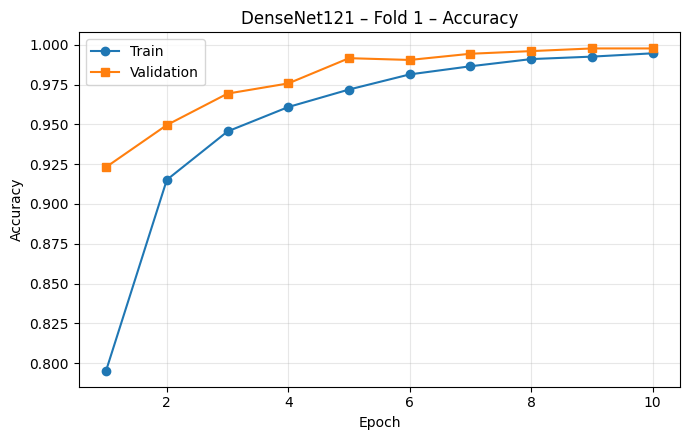

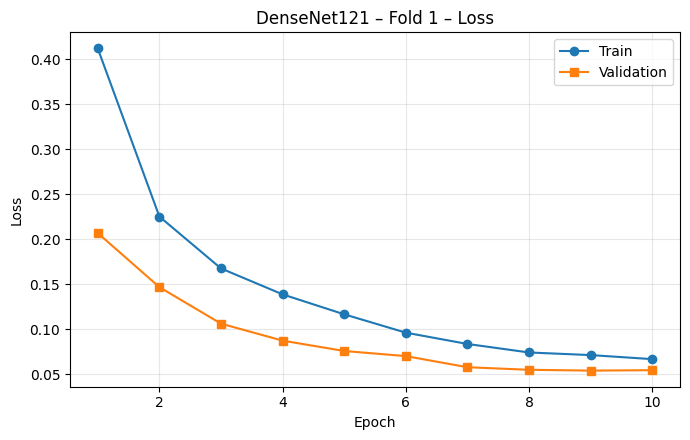

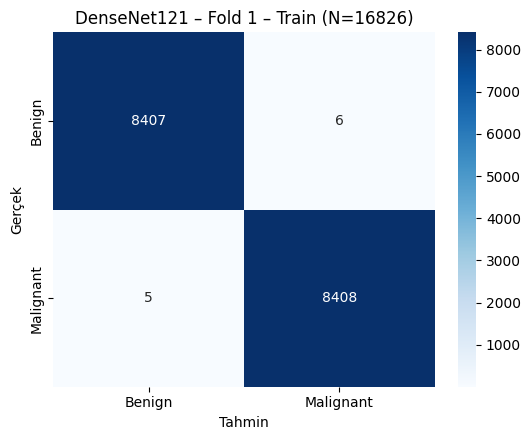

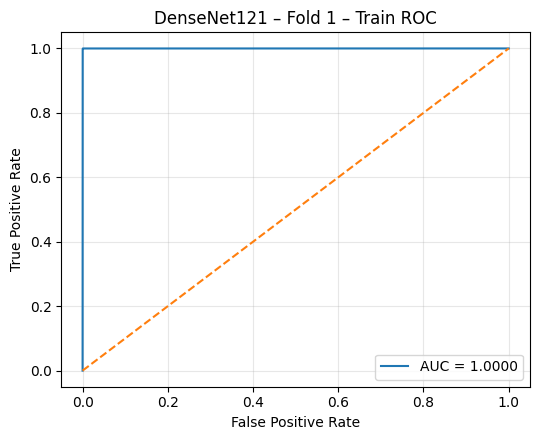

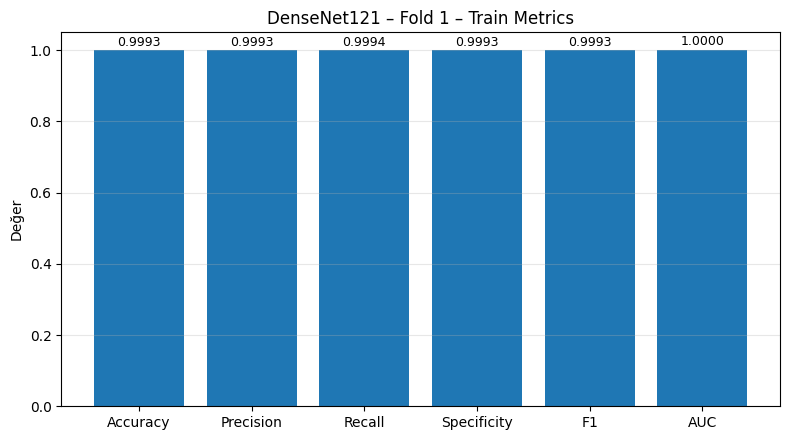

...

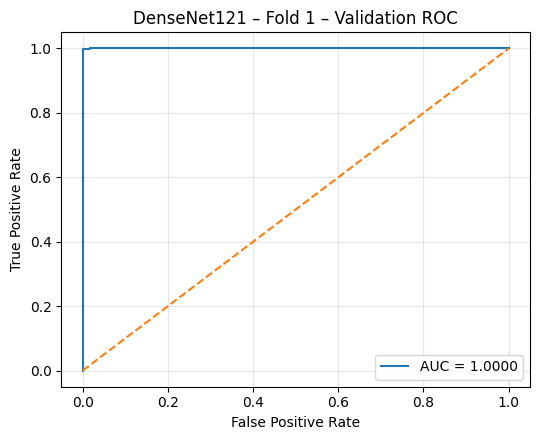

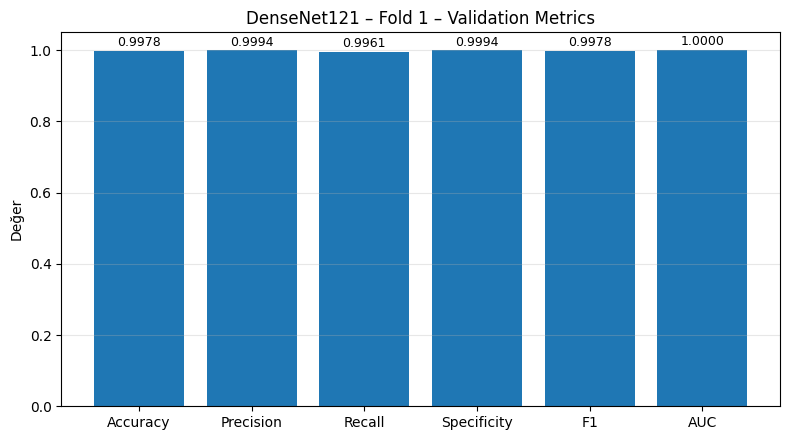

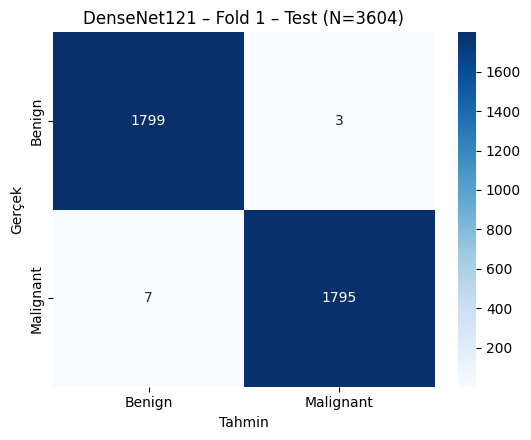

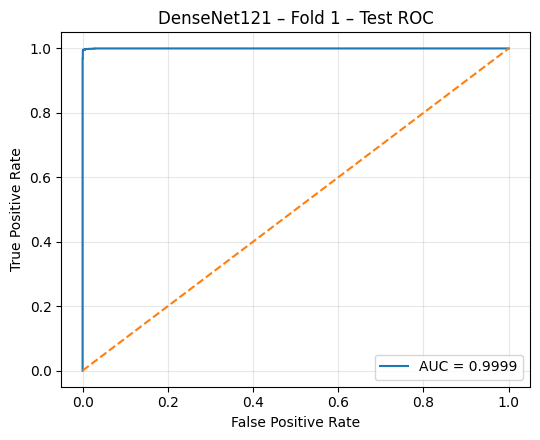

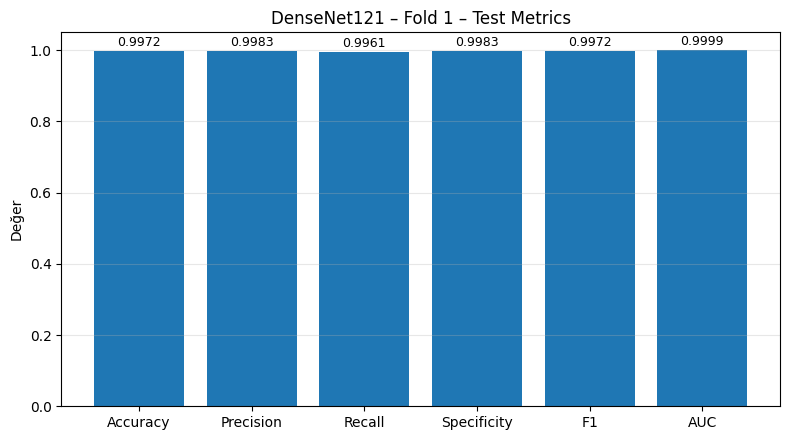

DenseNet121 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8407.0,6.0,5.0,8408.0,0.999346,0.999287,0.999406,0.999287,0.999346,0.999998,0.050850
Validation,3594.0,1796.0,1.0,7.0,1790.0,0.997774,0.999442,0.996105,0.999444,0.997770,0.999983,0.054036
Test,3604.0,1799.0,3.0,7.0,1795.0,0.997225,0.998331,0.996115,0.998335,0.997222,0.999932,0.056524


✓ DenseNet121 Fold 1: best epoch 9 | Test acc 0.9972
DenseNet121 | Fold 2 | Epoch 01/10 | Train loss 0.4117 acc 0.7988 | Val loss 0.2345 acc 0.9162
DenseNet121 | Fold 2 | Epoch 02/10 | Train loss 0.2263 acc 0.9120 | Val loss 0.1573 acc 0.9485
DenseNet121 | Fold 2 | Epoch 03/10 | Train loss 0.1668 acc 0.9462 | Val loss 0.1025 acc 0.9722
DenseNet121 | Fold 2 | Epoch 04/10 | Train loss 0.1395 acc 0.9598 | Val loss 0.1239 acc 0.9699
DenseNet121 | Fold 2 | Epoch 05/10 | Train loss 0.1161 acc 0.9702 | Val loss 0.0808 acc 0.9875
DenseNet121 | Fold 2 | Epoch 06/10 | Train loss 0.0978 acc 0.9807 | Val loss 0.0823 acc 0.9855
DenseNet121 | Fold 2 | Epoch 07/10 | Train loss 0.0841 acc 0.9860 | Val loss 0.0710 acc 0.9886
DenseNet121 | Fold 2 | Epoch 08/10 | Train loss 0.0747 acc 0.9906 | Val loss 0.0639 acc 0.9930
DenseNet121 | Fold 2 | Epoch 09/10 | Train loss 0.0697 acc 0.9931 | Val loss 0.0593 acc 0.9955
DenseNet121 | Fold 2 | Epoch 10/10 | Train loss 0.0659 acc 0.9949 | Val loss 0.0565 acc 0.99

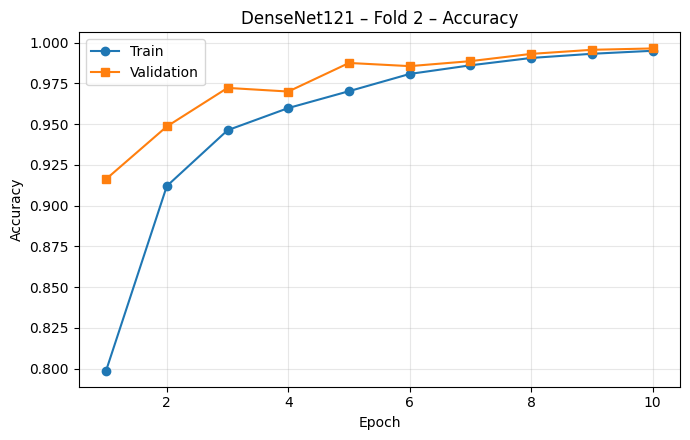

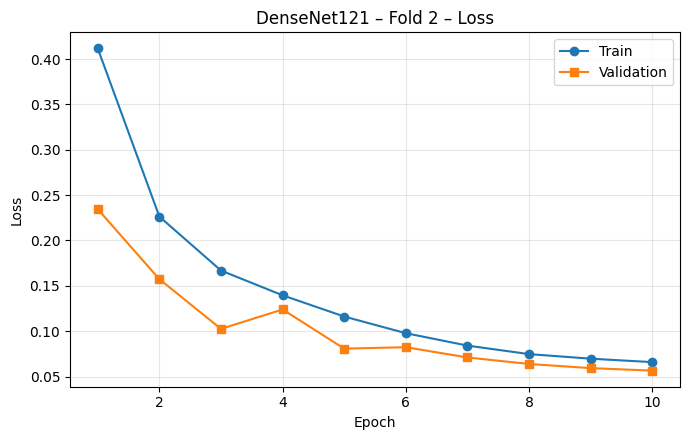

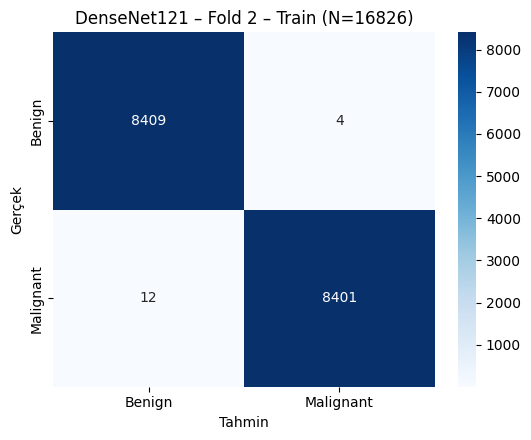

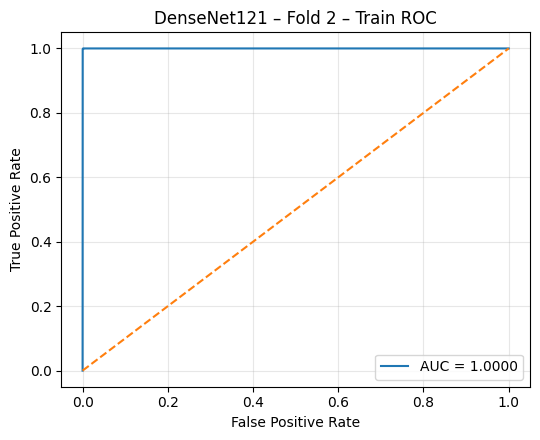

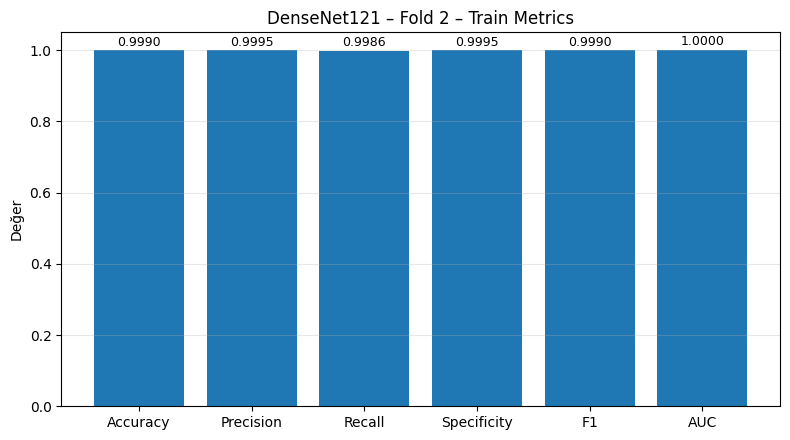

...

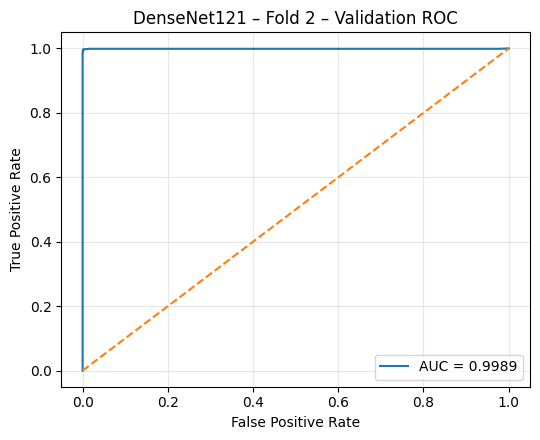

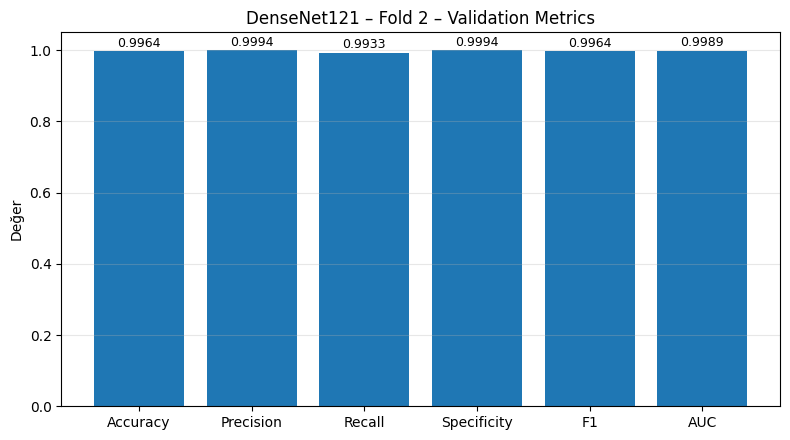

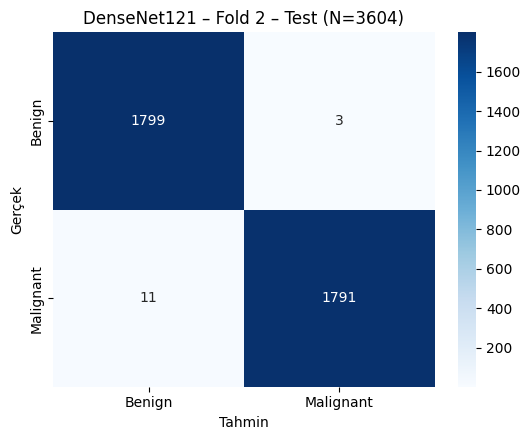

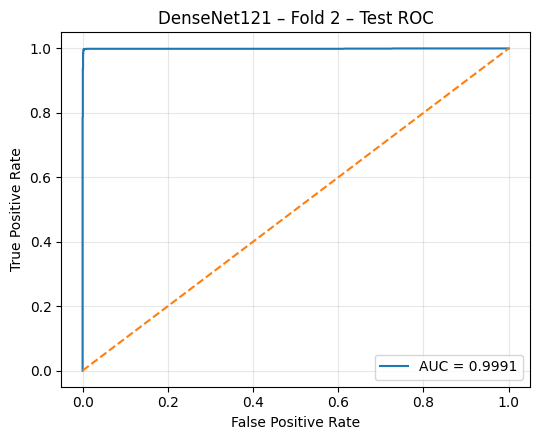

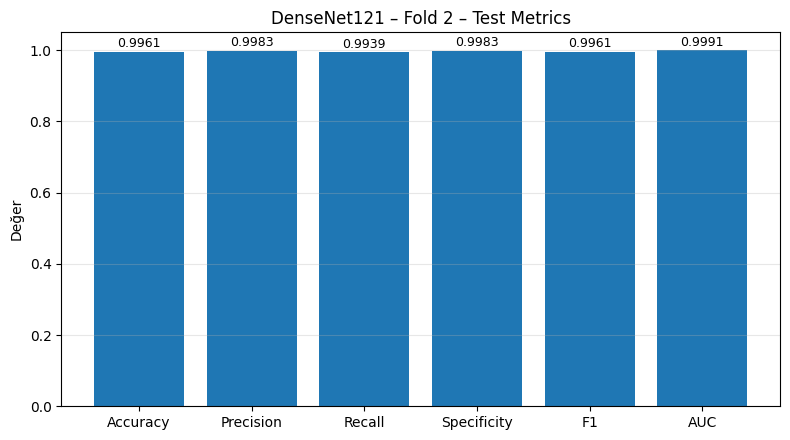

DenseNet121 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8409.0,4.0,12.0,8401.0,0.999049,0.999524,0.998574,0.999525,0.999049,0.999997,0.050431
Validation,3594.0,1796.0,1.0,12.0,1785.0,0.996383,0.999440,0.993322,0.999444,0.996372,0.998875,0.056528
Test,3604.0,1799.0,3.0,11.0,1791.0,0.996115,0.998328,0.993896,0.998335,0.996107,0.999089,0.057100


✓ DenseNet121 Fold 2: best epoch 10 | Test acc 0.9961
DenseNet121 | Fold 3 | Epoch 01/10 | Train loss 0.4198 acc 0.7915 | Val loss 0.2266 acc 0.9143
DenseNet121 | Fold 3 | Epoch 02/10 | Train loss 0.2321 acc 0.9081 | Val loss 0.1512 acc 0.9583
DenseNet121 | Fold 3 | Epoch 03/10 | Train loss 0.1693 acc 0.9445 | Val loss 0.1386 acc 0.9505
DenseNet121 | Fold 3 | Epoch 04/10 | Train loss 0.1400 acc 0.9599 | Val loss 0.0959 acc 0.9814
DenseNet121 | Fold 3 | Epoch 05/10 | Train loss 0.1141 acc 0.9725 | Val loss 0.0792 acc 0.9853
DenseNet121 | Fold 3 | Epoch 06/10 | Train loss 0.0956 acc 0.9809 | Val loss 0.0771 acc 0.9869
DenseNet121 | Fold 3 | Epoch 07/10 | Train loss 0.0837 acc 0.9878 | Val loss 0.0631 acc 0.9922
DenseNet121 | Fold 3 | Epoch 08/10 | Train loss 0.0730 acc 0.9919 | Val loss 0.0555 acc 0.9958
DenseNet121 | Fold 3 | Epoch 09/10 | Train loss 0.0704 acc 0.9936 | Val loss 0.0545 acc 0.9969
DenseNet121 | Fold 3 | Epoch 10/10 | Train loss 0.0674 acc 0.9943 | Val loss 0.0542 acc 0.9

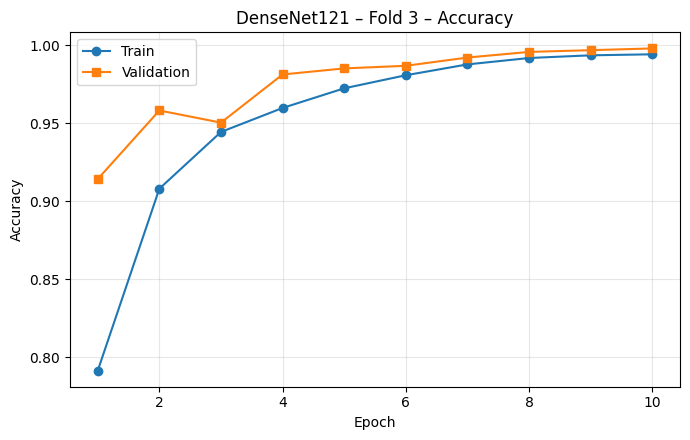

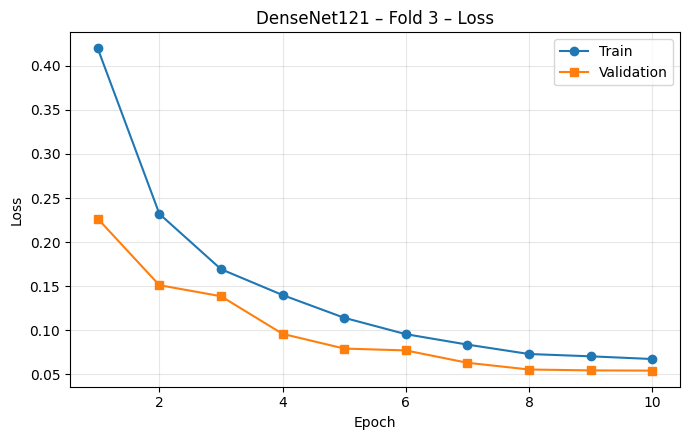

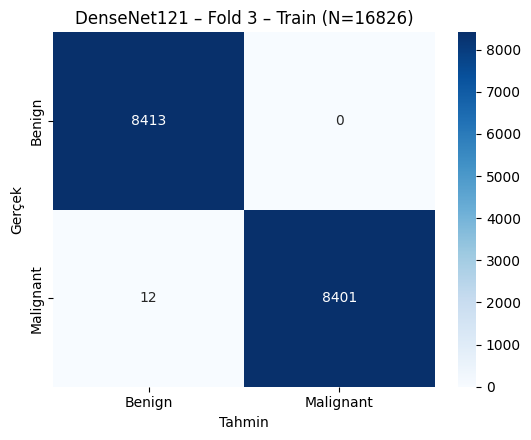

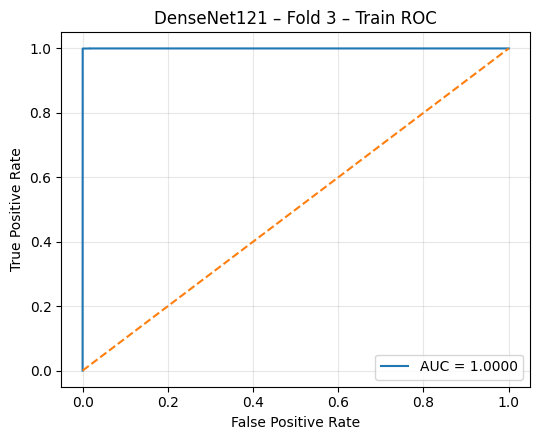

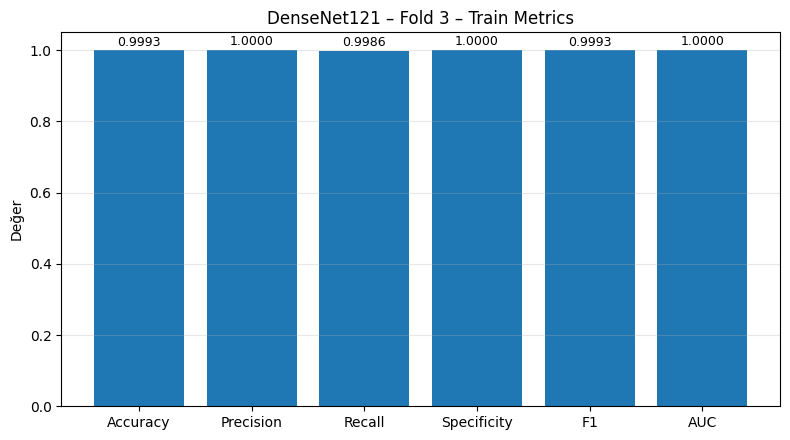

...

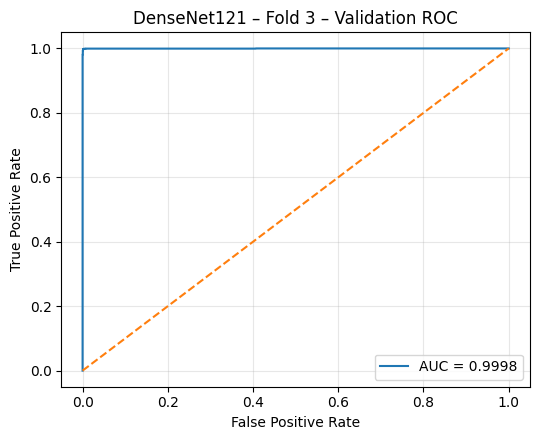

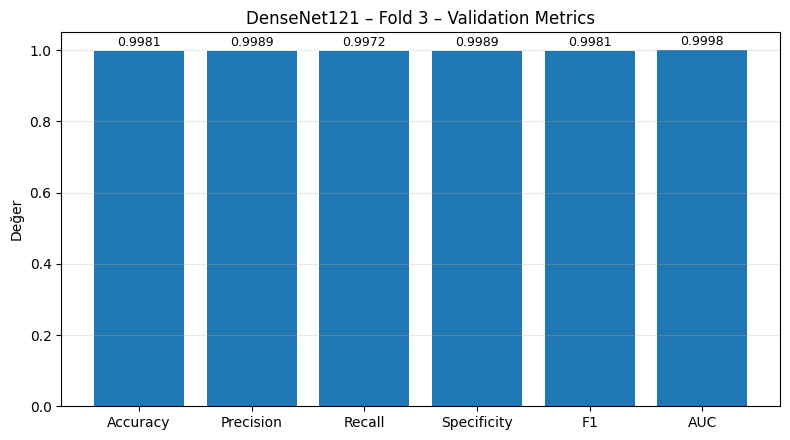

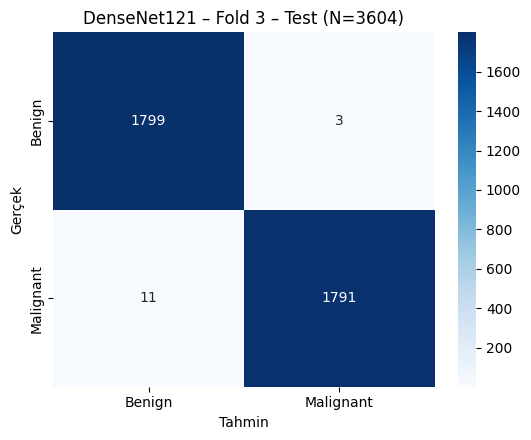

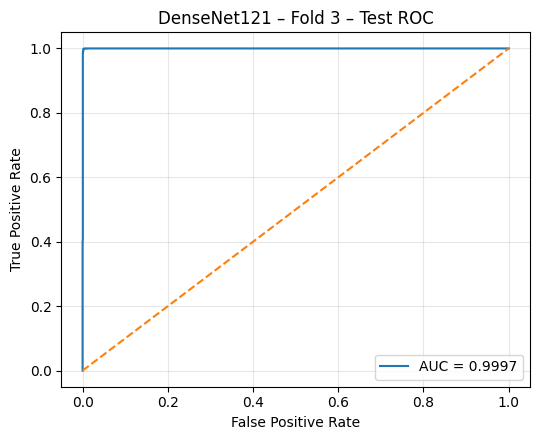

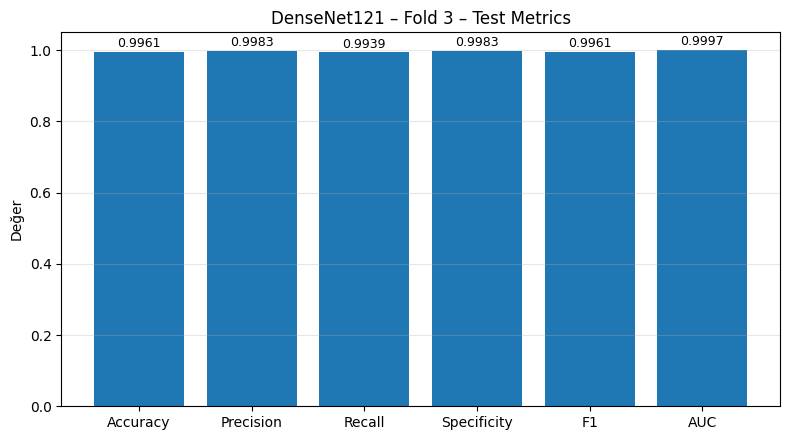

DenseNet121 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8413.0,0.0,12.0,8401.0,0.999287,1.000000,0.998574,1.000000,0.999286,0.999998,0.050606
Validation,3594.0,1795.0,2.0,5.0,1792.0,0.998052,0.998885,0.997218,0.998887,0.998051,0.999757,0.054219
Test,3604.0,1799.0,3.0,11.0,1791.0,0.996115,0.998328,0.993896,0.998335,0.996107,0.999652,0.056125


✓ DenseNet121 Fold 3: best epoch 10 | Test acc 0.9961
DenseNet121 | Fold 4 | Epoch 01/10 | Train loss 0.3977 acc 0.8026 | Val loss 0.2848 acc 0.8834
DenseNet121 | Fold 4 | Epoch 02/10 | Train loss 0.2176 acc 0.9181 | Val loss 0.1622 acc 0.9435
DenseNet121 | Fold 4 | Epoch 03/10 | Train loss 0.1626 acc 0.9489 | Val loss 0.1297 acc 0.9680
DenseNet121 | Fold 4 | Epoch 04/10 | Train loss 0.1328 acc 0.9639 | Val loss 0.0833 acc 0.9825
DenseNet121 | Fold 4 | Epoch 05/10 | Train loss 0.1122 acc 0.9735 | Val loss 0.0790 acc 0.9875
DenseNet121 | Fold 4 | Epoch 06/10 | Train loss 0.0933 acc 0.9823 | Val loss 0.0789 acc 0.9864
DenseNet121 | Fold 4 | Epoch 07/10 | Train loss 0.0816 acc 0.9872 | Val loss 0.0600 acc 0.9953
DenseNet121 | Fold 4 | Epoch 08/10 | Train loss 0.0722 acc 0.9923 | Val loss 0.0625 acc 0.9947
DenseNet121 | Fold 4 | Epoch 09/10 | Train loss 0.0693 acc 0.9938 | Val loss 0.0557 acc 0.9975
DenseNet121 | Fold 4 | Epoch 10/10 | Train loss 0.0669 acc 0.9943 | Val loss 0.0560 acc 0.9

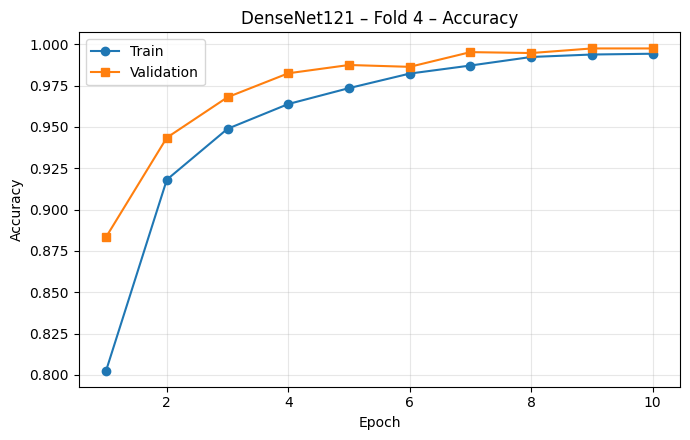

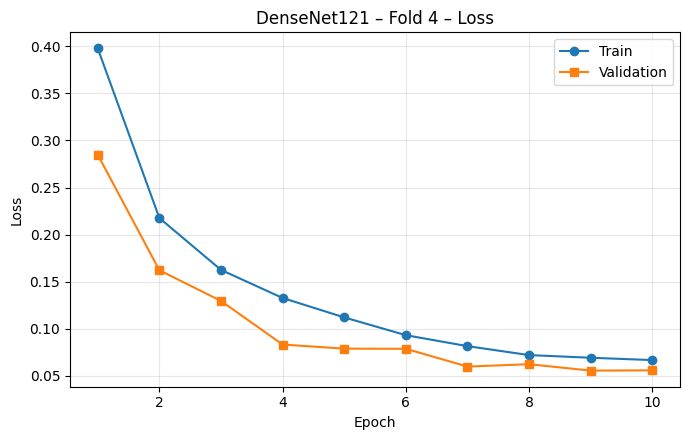

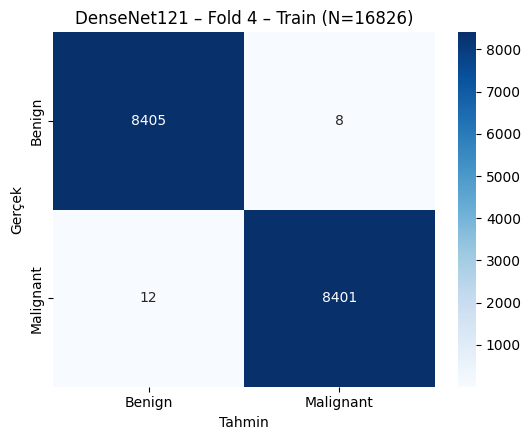

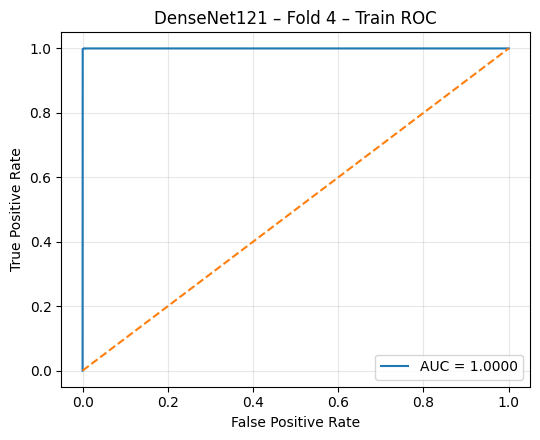

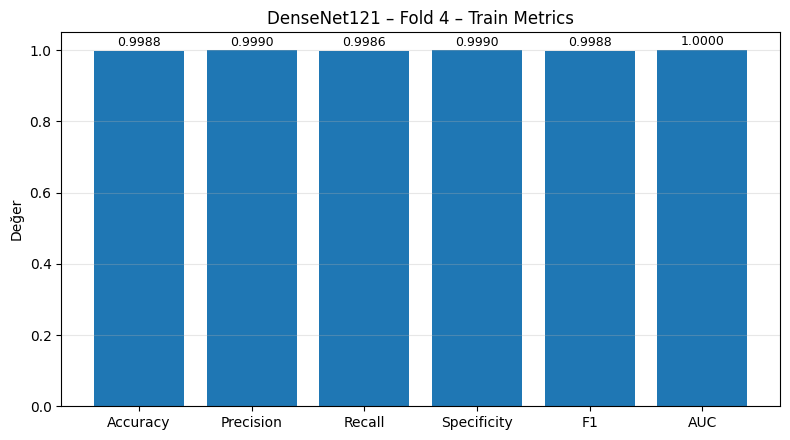

...

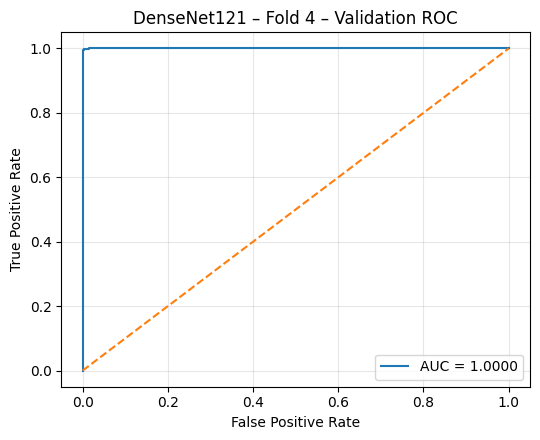

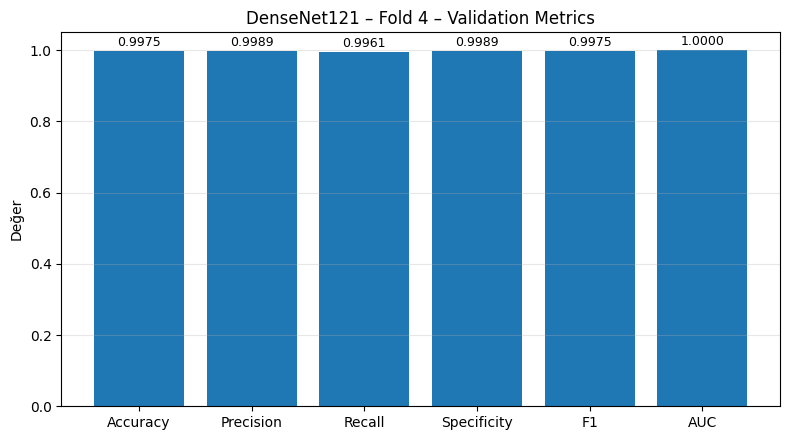

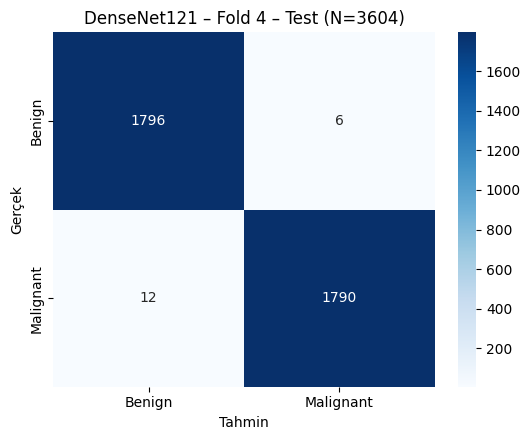

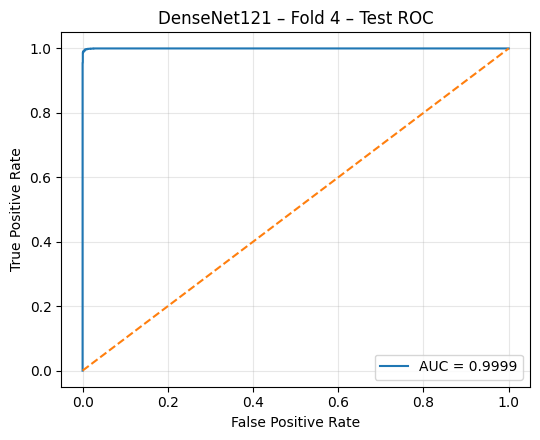

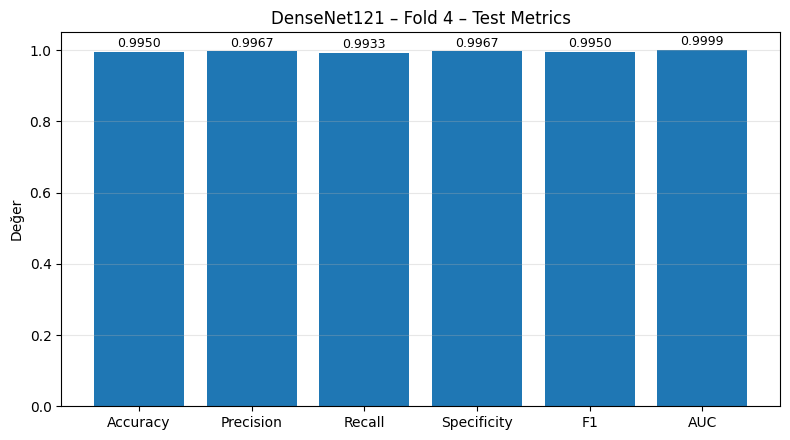

DenseNet121 – Fold 4 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8405.0,8.0,12.0,8401.0,0.998811,0.999049,0.998574,0.999049,0.998811,0.999996,0.051119
Validation,3594.0,1795.0,2.0,7.0,1790.0,0.997496,0.998884,0.996105,0.998887,0.997492,0.999966,0.055685
Test,3604.0,1796.0,6.0,12.0,1790.0,0.995006,0.996659,0.993341,0.996670,0.994997,0.999905,0.059095


✓ DenseNet121 Fold 4: best epoch 9 | Test acc 0.9950
DenseNet121 | Fold 5 | Epoch 01/10 | Train loss 0.4170 acc 0.7941 | Val loss 0.2533 acc 0.8926
DenseNet121 | Fold 5 | Epoch 02/10 | Train loss 0.2328 acc 0.9087 | Val loss 0.1275 acc 0.9636
DenseNet121 | Fold 5 | Epoch 03/10 | Train loss 0.1683 acc 0.9461 | Val loss 0.1436 acc 0.9480
DenseNet121 | Fold 5 | Epoch 04/10 | Train loss 0.1384 acc 0.9605 | Val loss 0.0937 acc 0.9769
DenseNet121 | Fold 5 | Epoch 05/10 | Train loss 0.1126 acc 0.9733 | Val loss 0.0857 acc 0.9836
DenseNet121 | Fold 5 | Epoch 06/10 | Train loss 0.0990 acc 0.9796 | Val loss 0.0737 acc 0.9911
DenseNet121 | Fold 5 | Epoch 07/10 | Train loss 0.0830 acc 0.9876 | Val loss 0.0645 acc 0.9933
DenseNet121 | Fold 5 | Epoch 08/10 | Train loss 0.0759 acc 0.9904 | Val loss 0.0618 acc 0.9958
DenseNet121 | Fold 5 | Epoch 09/10 | Train loss 0.0704 acc 0.9931 | Val loss 0.0555 acc 0.9967
DenseNet121 | Fold 5 | Epoch 10/10 | Train loss 0.0673 acc 0.9944 | Val loss 0.0575 acc 0.99

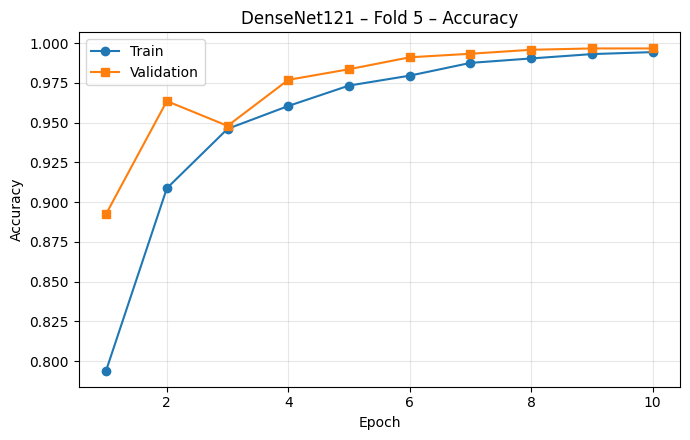

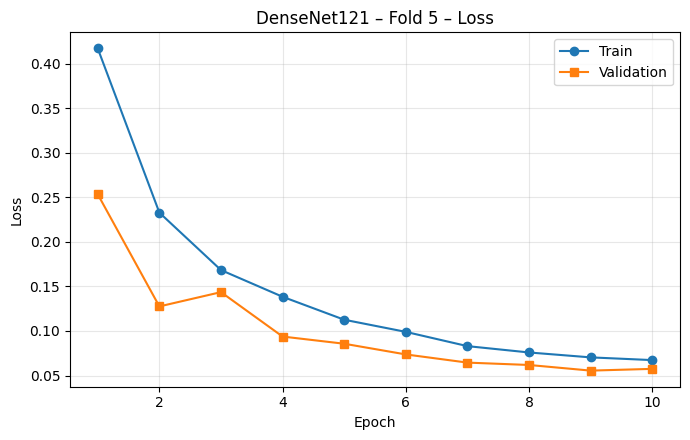

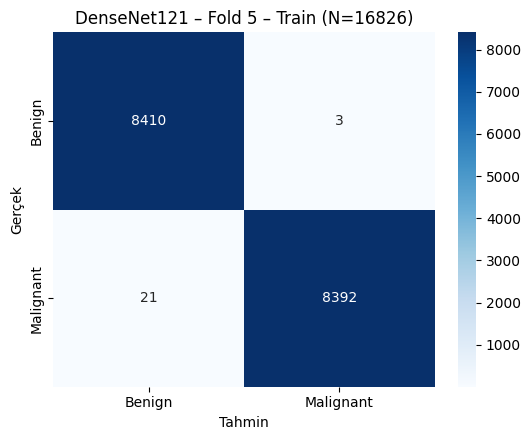

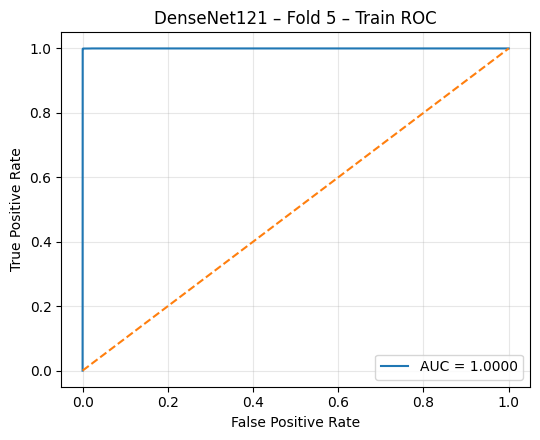

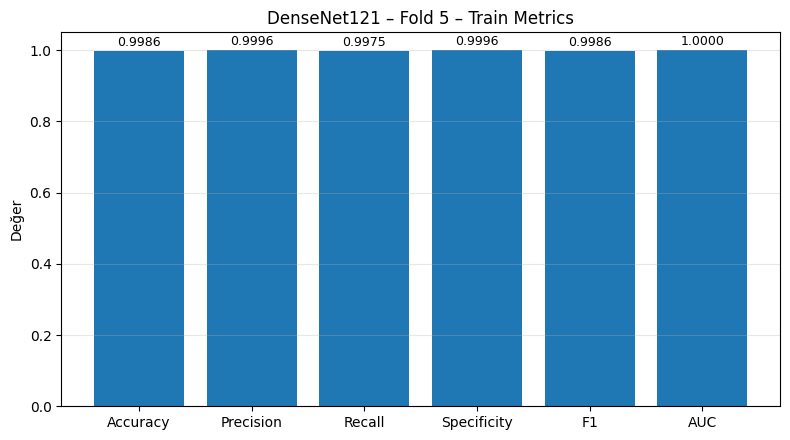

...

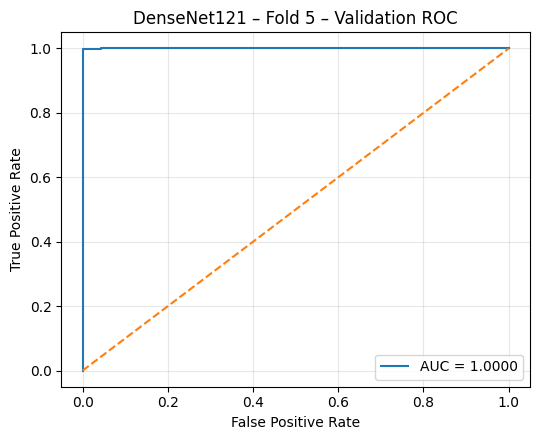

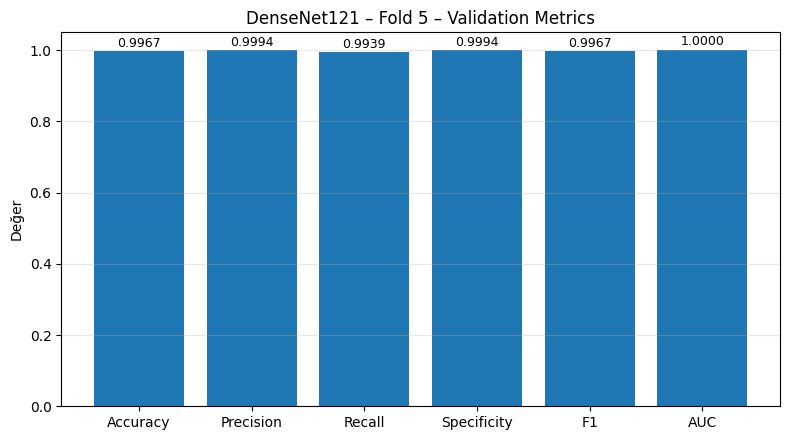

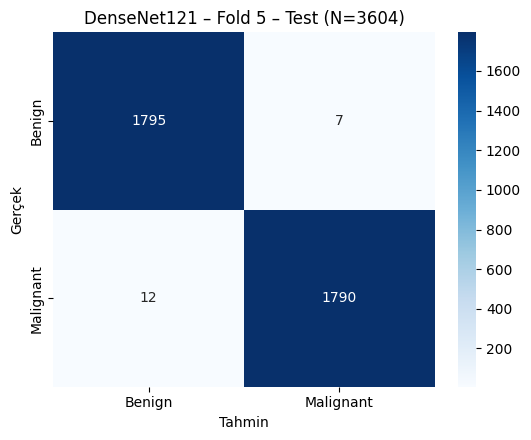

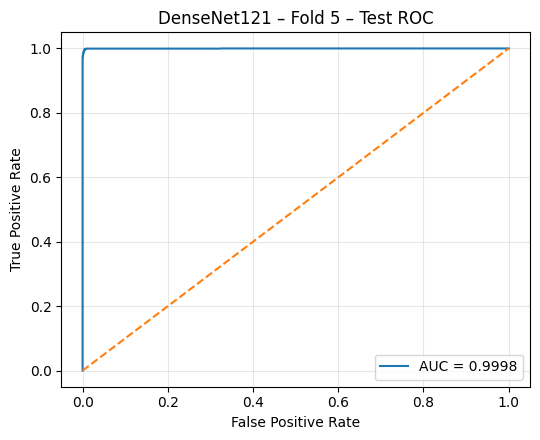

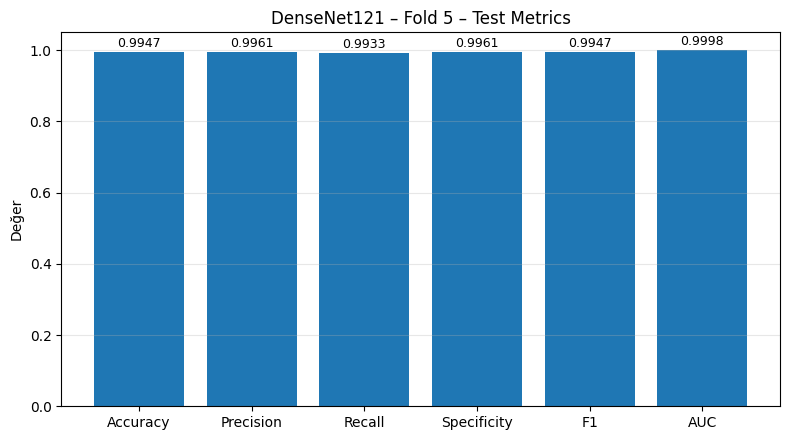

DenseNet121 – Fold 5 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8410.0,3.0,21.0,8392.0,0.998574,0.999643,0.997504,0.999643,0.998572,0.999994,0.051205
Validation,3594.0,1796.0,1.0,11.0,1786.0,0.996661,0.999440,0.993879,0.999444,0.996652,0.999953,0.055501
Test,3604.0,1795.0,7.0,12.0,1790.0,0.994728,0.996105,0.993341,0.996115,0.994721,0.999751,0.058290


✓ DenseNet121 Fold 5: best epoch 9 | Test acc 0.9947
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 186MB/s]


EfficientNet-B0 | Fold 1 | Epoch 01/10 | Train loss 0.4525 acc 0.7731 | Val loss 0.2313 acc 0.9149
EfficientNet-B0 | Fold 1 | Epoch 02/10 | Train loss 0.2615 acc 0.8954 | Val loss 0.1463 acc 0.9608
EfficientNet-B0 | Fold 1 | Epoch 03/10 | Train loss 0.1858 acc 0.9355 | Val loss 0.1175 acc 0.9711
EfficientNet-B0 | Fold 1 | Epoch 04/10 | Train loss 0.1516 acc 0.9520 | Val loss 0.0994 acc 0.9805
EfficientNet-B0 | Fold 1 | Epoch 05/10 | Train loss 0.1272 acc 0.9649 | Val loss 0.0791 acc 0.9864
EfficientNet-B0 | Fold 1 | Epoch 06/10 | Train loss 0.1100 acc 0.9736 | Val loss 0.0758 acc 0.9880
EfficientNet-B0 | Fold 1 | Epoch 07/10 | Train loss 0.0964 acc 0.9800 | Val loss 0.0694 acc 0.9889
EfficientNet-B0 | Fold 1 | Epoch 08/10 | Train loss 0.0909 acc 0.9813 | Val loss 0.0668 acc 0.9925
EfficientNet-B0 | Fold 1 | Epoch 09/10 | Train loss 0.0864 acc 0.9838 | Val loss 0.0612 acc 0.9939
EfficientNet-B0 | Fold 1 | Epoch 10/10 | Train loss 0.0849 acc 0.9854 | Val loss 0.0628 acc 0.9930


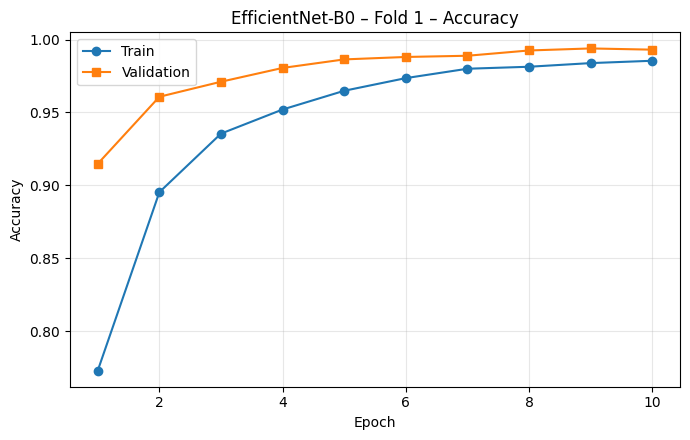

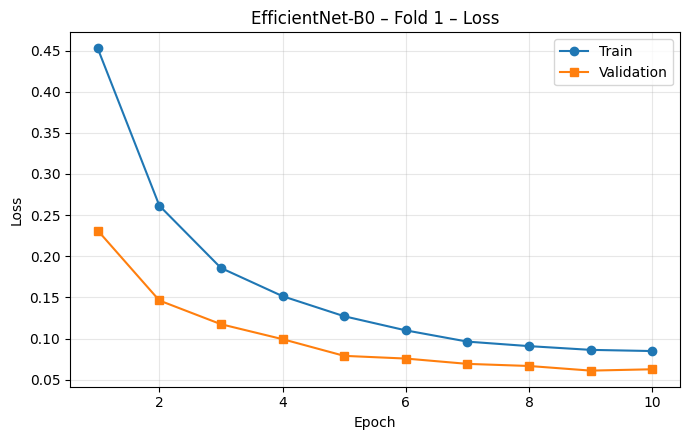

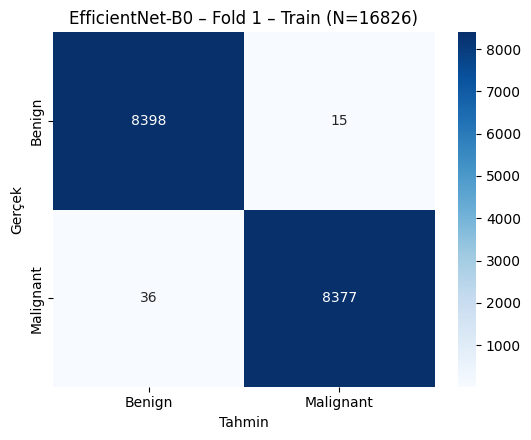

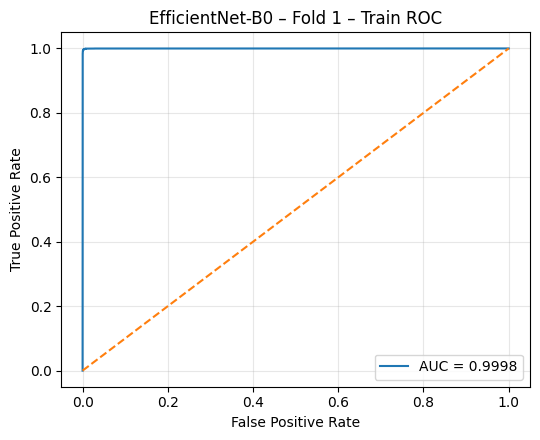

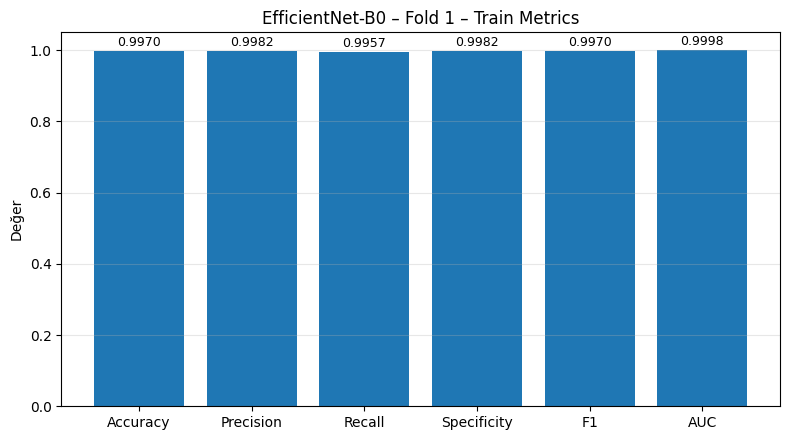

...

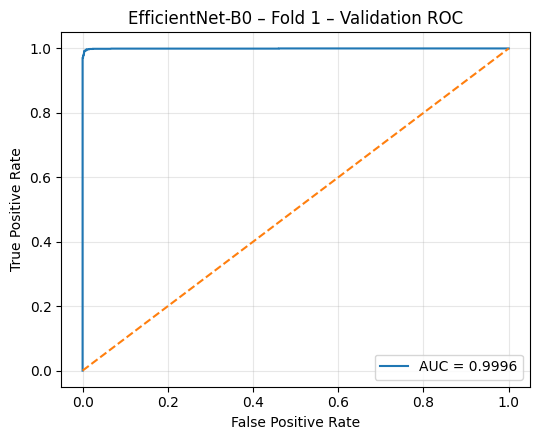

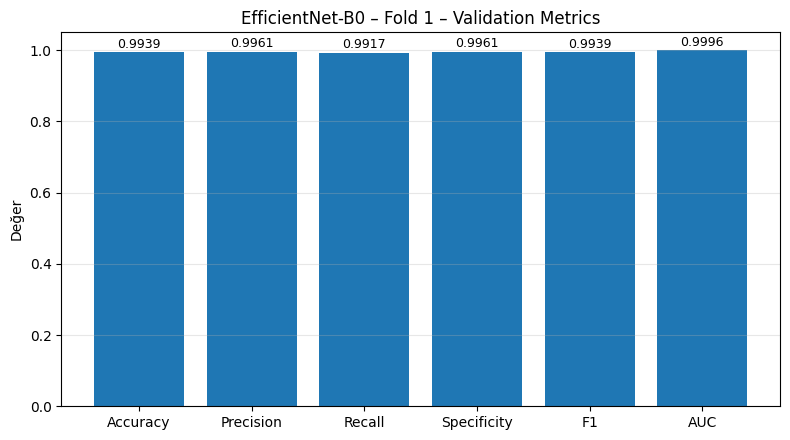

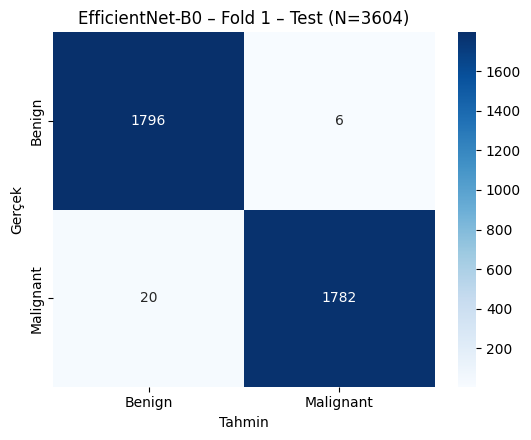

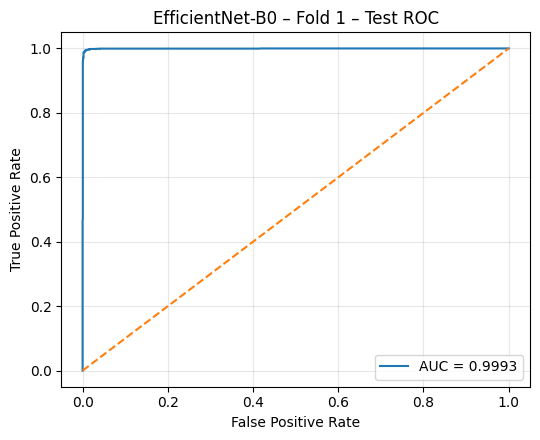

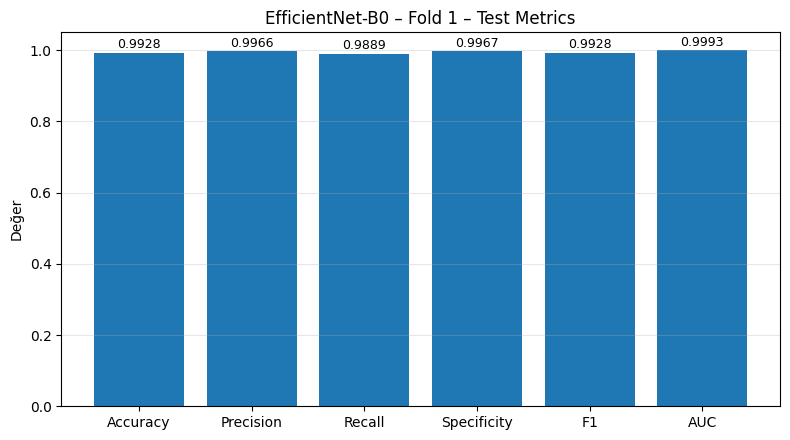

EfficientNet-B0 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8398.0,15.0,36.0,8377.0,0.996969,0.998213,0.995721,0.998217,0.996965,0.999850,0.053283
Validation,3594.0,1790.0,7.0,15.0,1782.0,0.993879,0.996087,0.991653,0.996105,0.993865,0.999583,0.061165
Test,3604.0,1796.0,6.0,20.0,1782.0,0.992786,0.996644,0.988901,0.996670,0.992758,0.999320,0.062177


✓ EfficientNet-B0 Fold 1: best epoch 9 | Test acc 0.9928
EfficientNet-B0 | Fold 2 | Epoch 01/10 | Train loss 0.4657 acc 0.7634 | Val loss 0.2770 acc 0.8962
EfficientNet-B0 | Fold 2 | Epoch 02/10 | Train loss 0.2662 acc 0.8898 | Val loss 0.1595 acc 0.9441
EfficientNet-B0 | Fold 2 | Epoch 03/10 | Train loss 0.1906 acc 0.9330 | Val loss 0.1148 acc 0.9638
EfficientNet-B0 | Fold 2 | Epoch 04/10 | Train loss 0.1550 acc 0.9517 | Val loss 0.0918 acc 0.9789
EfficientNet-B0 | Fold 2 | Epoch 05/10 | Train loss 0.1315 acc 0.9625 | Val loss 0.0898 acc 0.9822
EfficientNet-B0 | Fold 2 | Epoch 06/10 | Train loss 0.1141 acc 0.9726 | Val loss 0.0779 acc 0.9875
EfficientNet-B0 | Fold 2 | Epoch 07/10 | Train loss 0.1012 acc 0.9770 | Val loss 0.0727 acc 0.9875
EfficientNet-B0 | Fold 2 | Epoch 08/10 | Train loss 0.0935 acc 0.9811 | Val loss 0.0640 acc 0.9914
EfficientNet-B0 | Fold 2 | Epoch 09/10 | Train loss 0.0864 acc 0.9844 | Val loss 0.0652 acc 0.9933
EfficientNet-B0 | Fold 2 | Epoch 10/10 | Train loss 

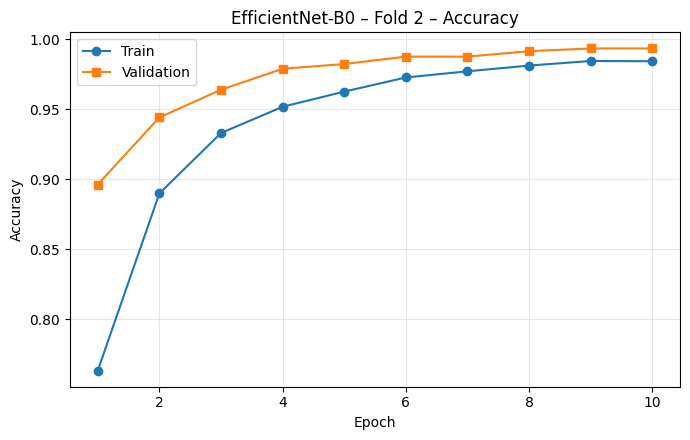

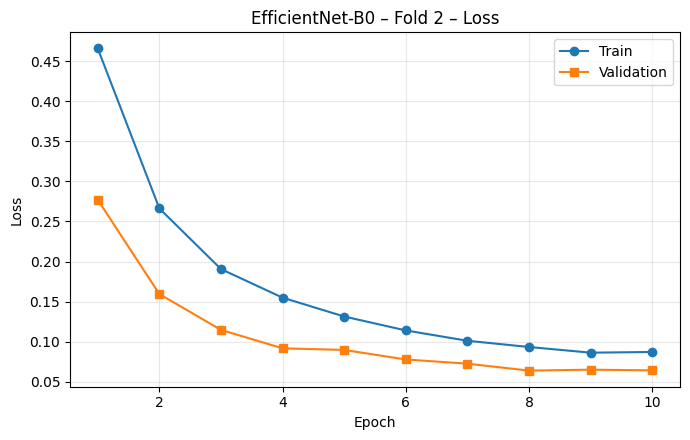

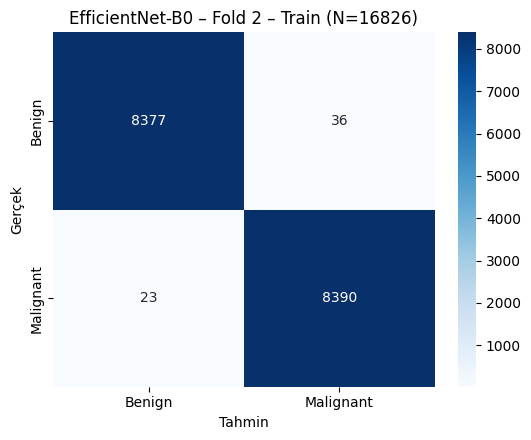

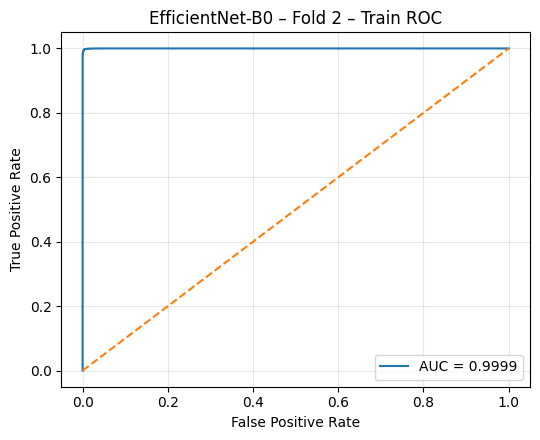

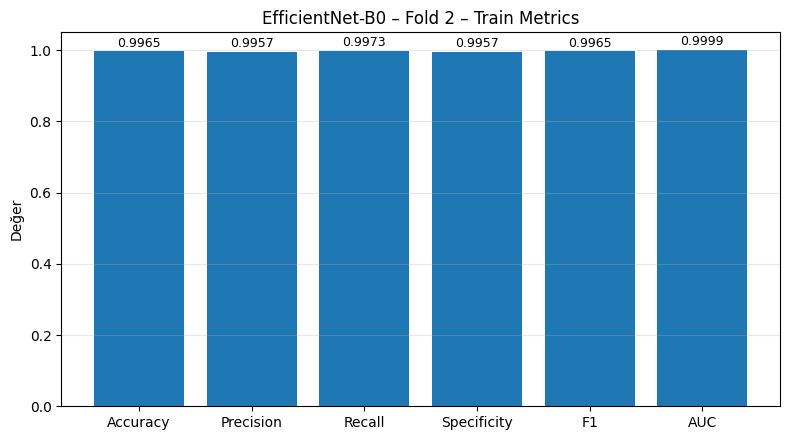

...

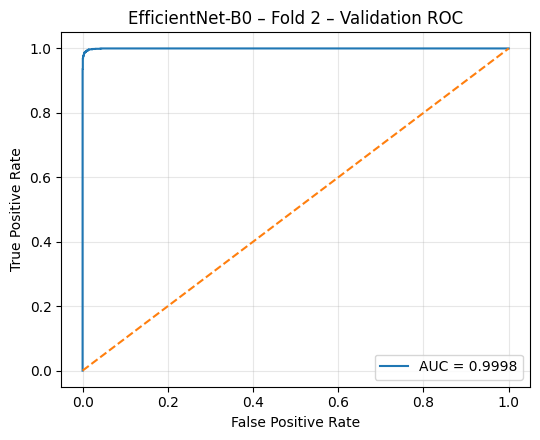

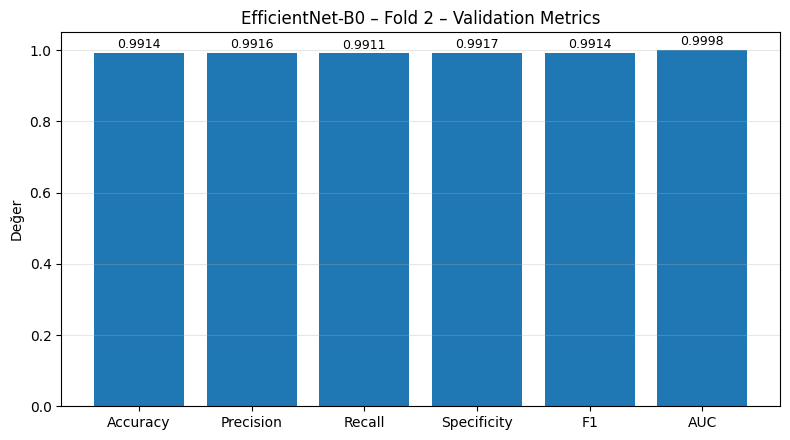

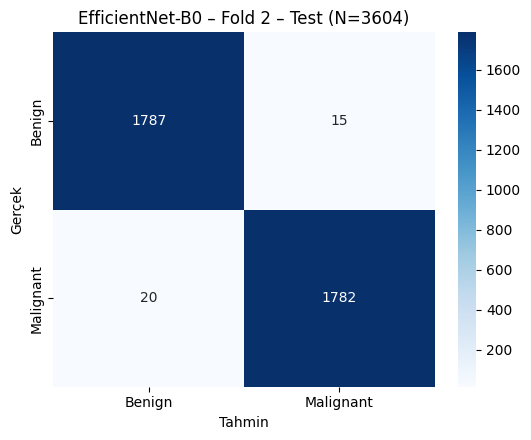

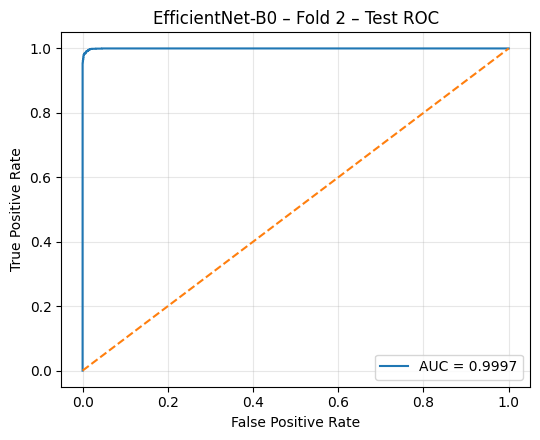

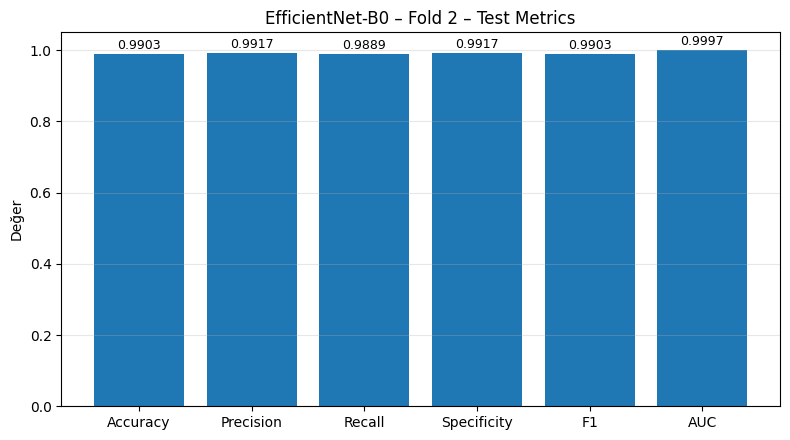

EfficientNet-B0 – Fold 2 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8377.0,36.0,23.0,8390.0,0.996494,0.995728,0.997266,0.995721,0.996496,0.999943,0.055297
Validation,3594.0,1782.0,15.0,16.0,1781.0,0.991375,0.991648,0.991096,0.991653,0.991372,0.999751,0.064028
Test,3604.0,1787.0,15.0,20.0,1782.0,0.990289,0.991653,0.988901,0.991676,0.990275,0.999742,0.064381


✓ EfficientNet-B0 Fold 2: best epoch 8 | Test acc 0.9903
EfficientNet-B0 | Fold 3 | Epoch 01/10 | Train loss 0.4613 acc 0.7649 | Val loss 0.2413 acc 0.8948
EfficientNet-B0 | Fold 3 | Epoch 02/10 | Train loss 0.2680 acc 0.8918 | Val loss 0.1532 acc 0.9541
EfficientNet-B0 | Fold 3 | Epoch 03/10 | Train loss 0.1925 acc 0.9311 | Val loss 0.1121 acc 0.9647
EfficientNet-B0 | Fold 3 | Epoch 04/10 | Train loss 0.1589 acc 0.9494 | Val loss 0.0927 acc 0.9822
EfficientNet-B0 | Fold 3 | Epoch 05/10 | Train loss 0.1291 acc 0.9645 | Val loss 0.0796 acc 0.9875
EfficientNet-B0 | Fold 3 | Epoch 06/10 | Train loss 0.1115 acc 0.9729 | Val loss 0.0726 acc 0.9917
EfficientNet-B0 | Fold 3 | Epoch 07/10 | Train loss 0.1012 acc 0.9788 | Val loss 0.0660 acc 0.9925
EfficientNet-B0 | Fold 3 | Epoch 08/10 | Train loss 0.0912 acc 0.9823 | Val loss 0.0631 acc 0.9917
EfficientNet-B0 | Fold 3 | Epoch 09/10 | Train loss 0.0873 acc 0.9839 | Val loss 0.0627 acc 0.9947
EfficientNet-B0 | Fold 3 | Epoch 10/10 | Train loss 

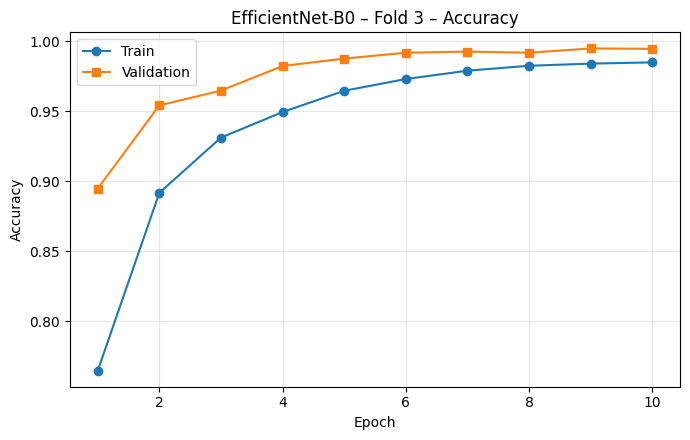

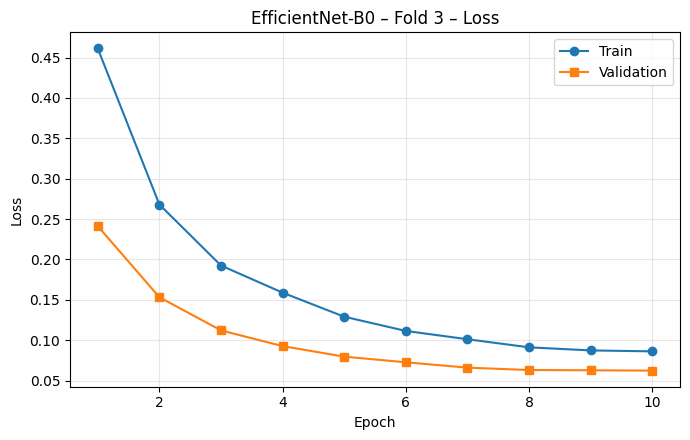

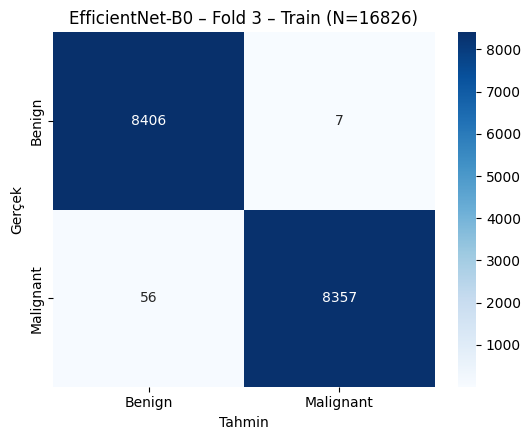

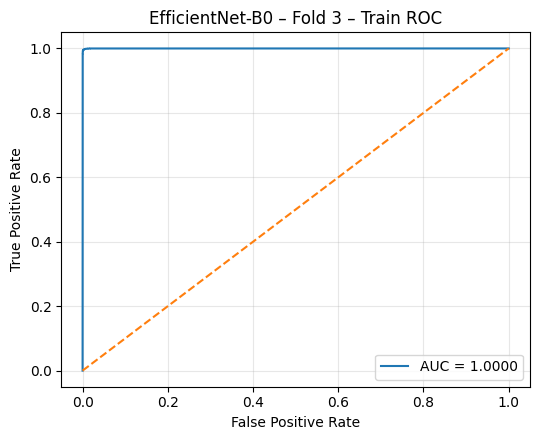

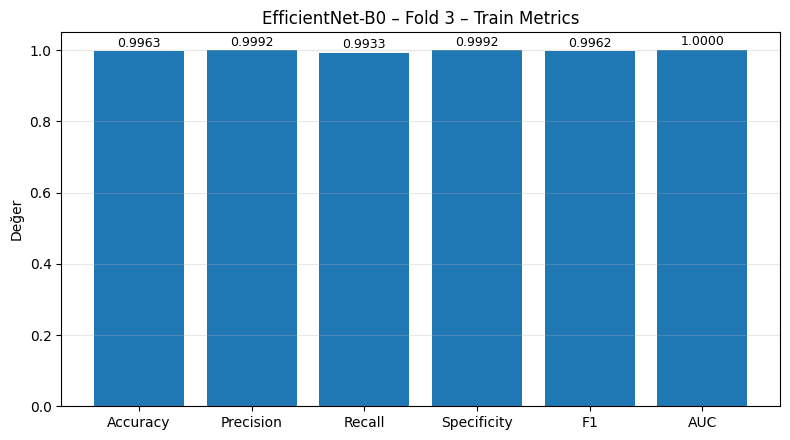

...

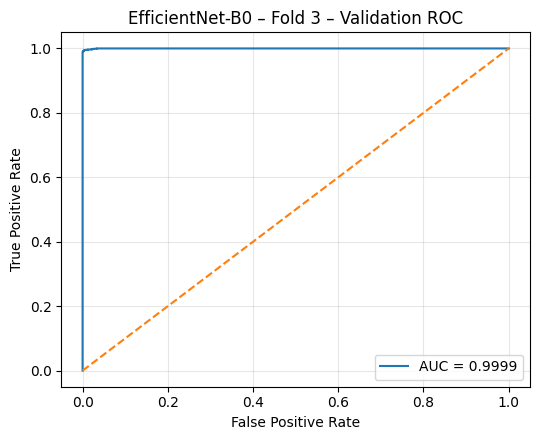

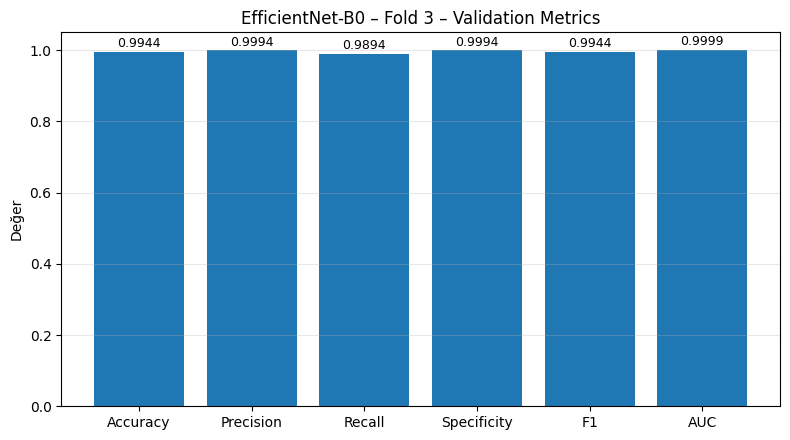

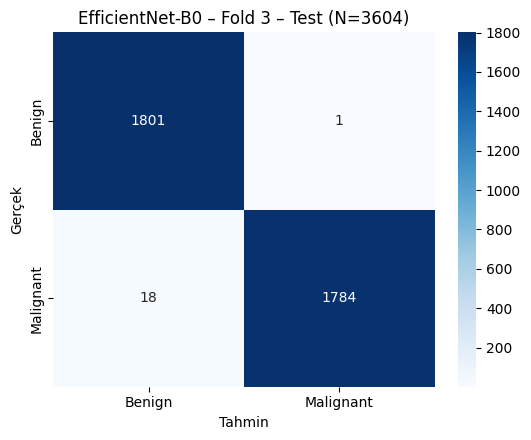

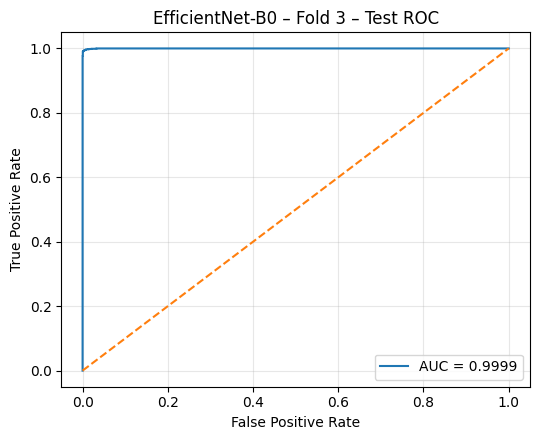

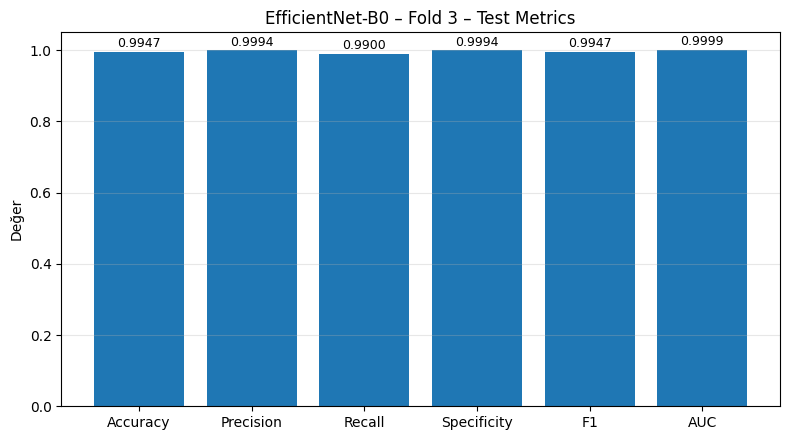

EfficientNet-B0 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8406.0,7.0,56.0,8357.0,0.996256,0.999163,0.993344,0.999168,0.996245,0.999963,0.057678
Validation,3594.0,1796.0,1.0,19.0,1778.0,0.994435,0.999438,0.989427,0.999444,0.994407,0.999877,0.062315
Test,3604.0,1801.0,1.0,18.0,1784.0,0.994728,0.999440,0.990011,0.999445,0.994703,0.999899,0.063772


✓ EfficientNet-B0 Fold 3: best epoch 10 | Test acc 0.9947
EfficientNet-B0 | Fold 4 | Epoch 01/10 | Train loss 0.4567 acc 0.7679 | Val loss 0.2500 acc 0.9012
EfficientNet-B0 | Fold 4 | Epoch 02/10 | Train loss 0.2606 acc 0.8964 | Val loss 0.1570 acc 0.9463
EfficientNet-B0 | Fold 4 | Epoch 03/10 | Train loss 0.1886 acc 0.9346 | Val loss 0.1227 acc 0.9652
EfficientNet-B0 | Fold 4 | Epoch 04/10 | Train loss 0.1538 acc 0.9525 | Val loss 0.0933 acc 0.9783
EfficientNet-B0 | Fold 4 | Epoch 05/10 | Train loss 0.1311 acc 0.9634 | Val loss 0.0862 acc 0.9819
EfficientNet-B0 | Fold 4 | Epoch 06/10 | Train loss 0.1131 acc 0.9719 | Val loss 0.0819 acc 0.9836
EfficientNet-B0 | Fold 4 | Epoch 07/10 | Train loss 0.1016 acc 0.9769 | Val loss 0.0800 acc 0.9850
EfficientNet-B0 | Fold 4 | Epoch 08/10 | Train loss 0.0923 acc 0.9828 | Val loss 0.0718 acc 0.9875
EfficientNet-B0 | Fold 4 | Epoch 09/10 | Train loss 0.0858 acc 0.9852 | Val loss 0.0688 acc 0.9900
EfficientNet-B0 | Fold 4 | Epoch 10/10 | Train loss

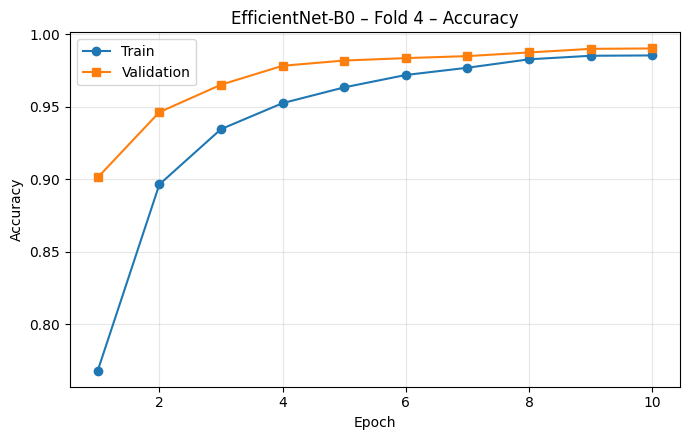

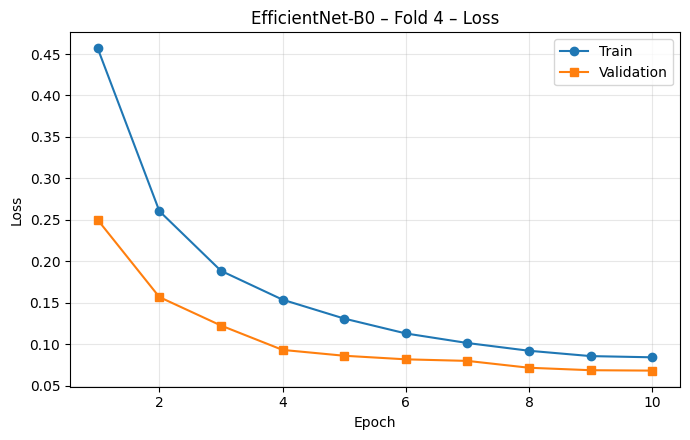

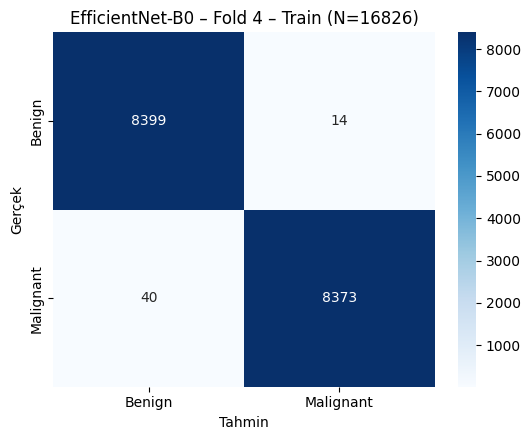

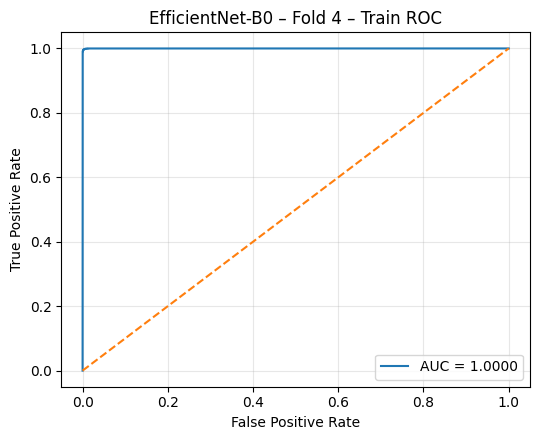

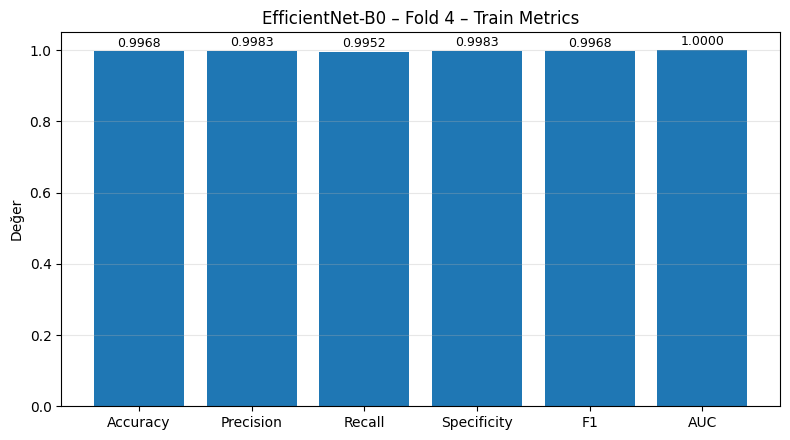

...

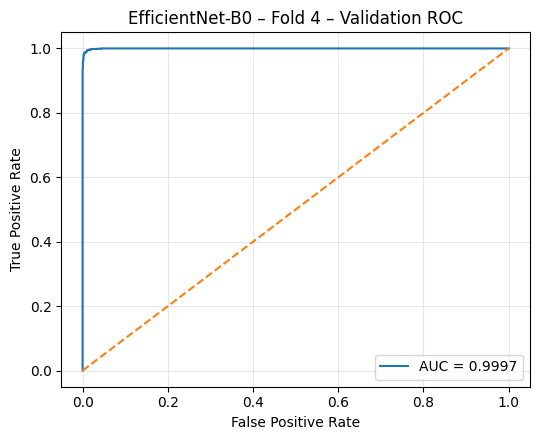

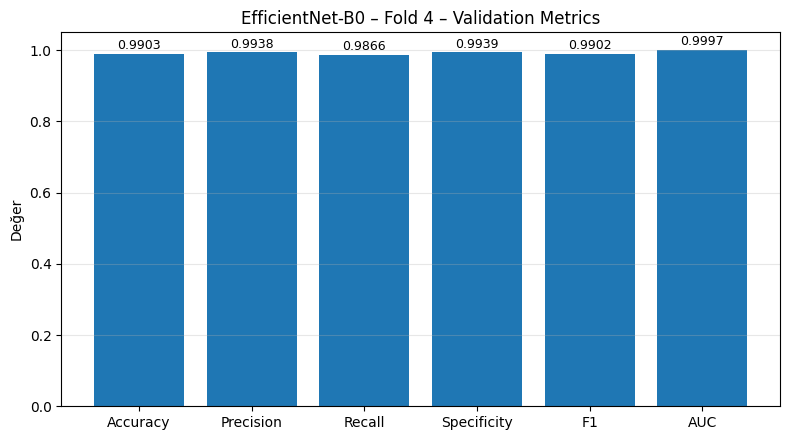

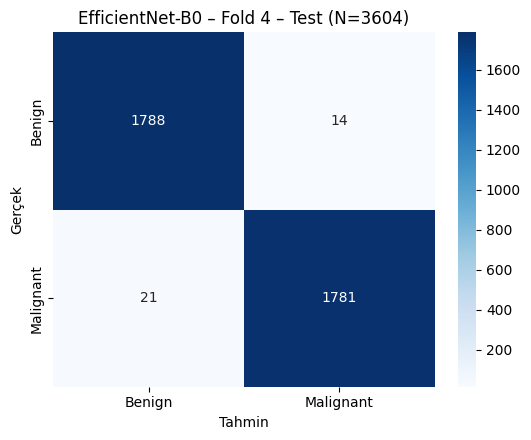

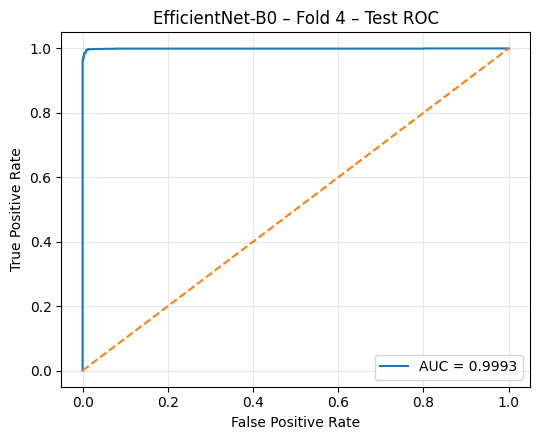

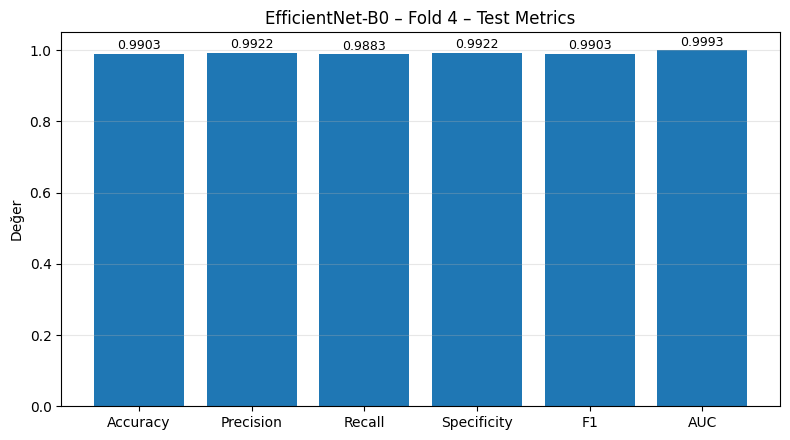

EfficientNet-B0 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8399.0,14.0,40.0,8373.0,0.996791,0.998331,0.995245,0.998336,0.996786,0.999970,0.055903
Validation,3594.0,1786.0,11.0,24.0,1773.0,0.990262,0.993834,0.986644,0.993879,0.990226,0.999714,0.068320
Test,3604.0,1788.0,14.0,21.0,1781.0,0.990289,0.992201,0.988346,0.992231,0.990270,0.999310,0.066294


✓ EfficientNet-B0 Fold 4: best epoch 10 | Test acc 0.9903
EfficientNet-B0 | Fold 5 | Epoch 01/10 | Train loss 0.4652 acc 0.7626 | Val loss 0.2634 acc 0.9040
EfficientNet-B0 | Fold 5 | Epoch 02/10 | Train loss 0.2660 acc 0.8921 | Val loss 0.1629 acc 0.9502
EfficientNet-B0 | Fold 5 | Epoch 03/10 | Train loss 0.1901 acc 0.9324 | Val loss 0.1229 acc 0.9594
EfficientNet-B0 | Fold 5 | Epoch 04/10 | Train loss 0.1552 acc 0.9504 | Val loss 0.0905 acc 0.9816
EfficientNet-B0 | Fold 5 | Epoch 05/10 | Train loss 0.1348 acc 0.9612 | Val loss 0.0885 acc 0.9841
EfficientNet-B0 | Fold 5 | Epoch 06/10 | Train loss 0.1124 acc 0.9728 | Val loss 0.0728 acc 0.9861
EfficientNet-B0 | Fold 5 | Epoch 07/10 | Train loss 0.1001 acc 0.9776 | Val loss 0.0767 acc 0.9861
EfficientNet-B0 | Fold 5 | Epoch 08/10 | Train loss 0.0934 acc 0.9812 | Val loss 0.0684 acc 0.9903
EfficientNet-B0 | Fold 5 | Epoch 09/10 | Train loss 0.0882 acc 0.9838 | Val loss 0.0681 acc 0.9908
EfficientNet-B0 | Fold 5 | Epoch 10/10 | Train loss

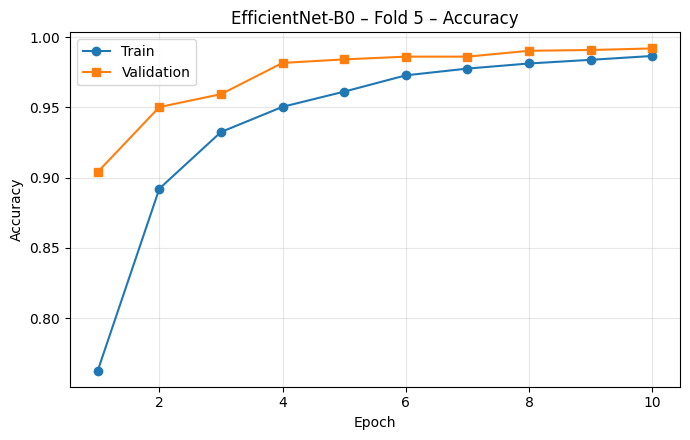

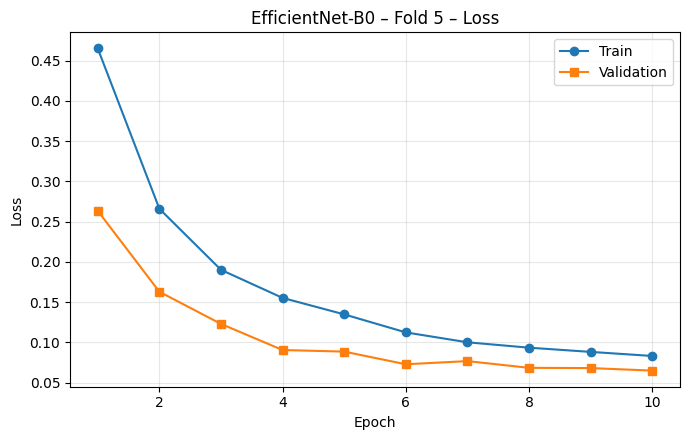

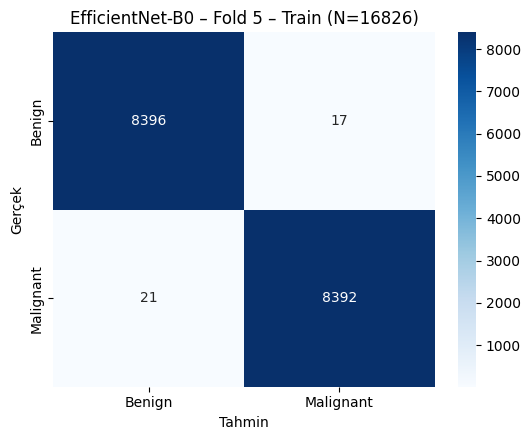

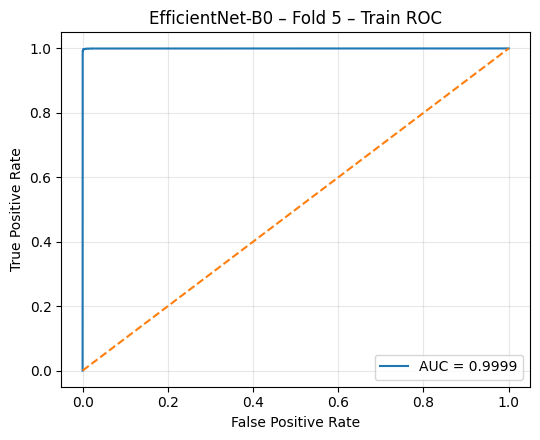

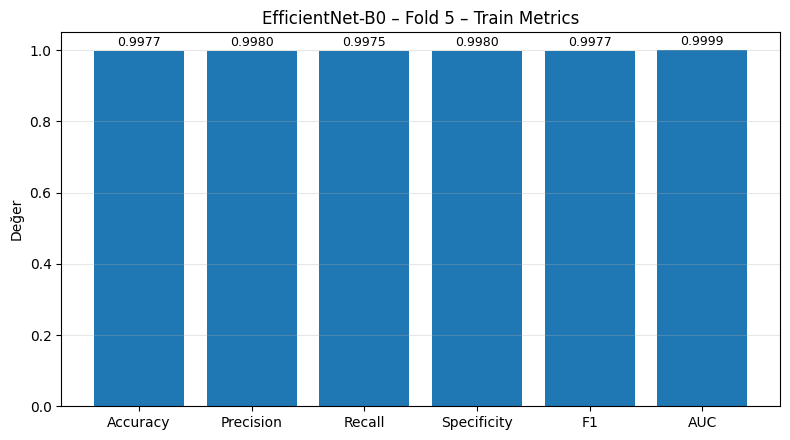

...

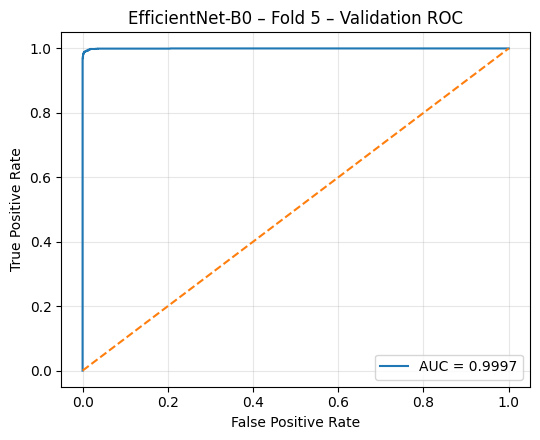

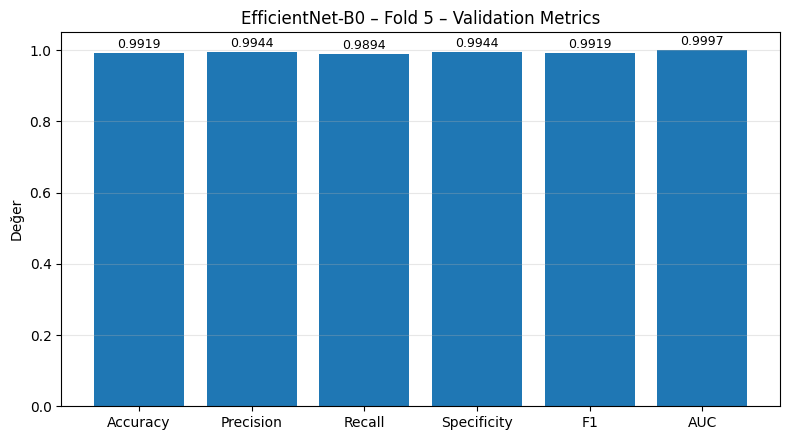

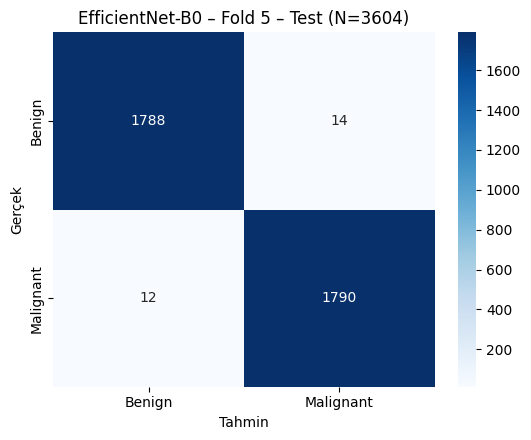

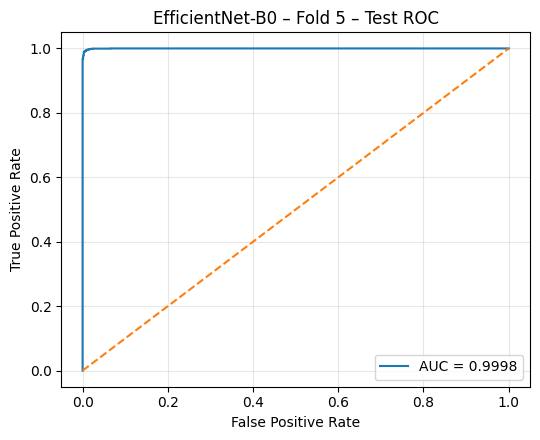

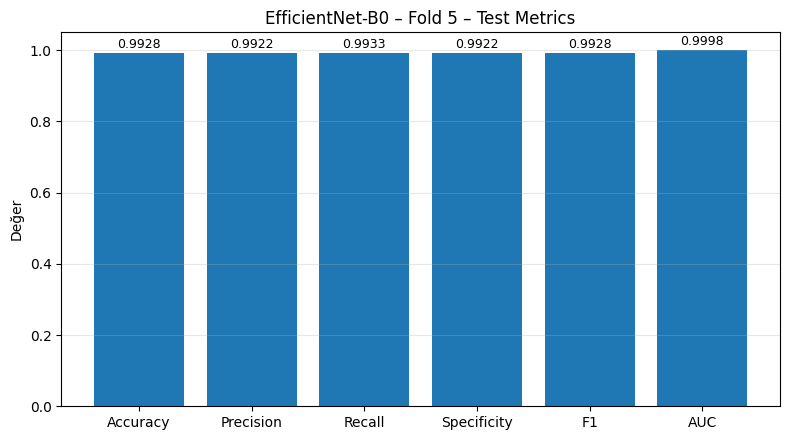

EfficientNet-B0 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8396.0,17.0,21.0,8392.0,0.997742,0.997978,0.997504,0.997979,0.997741,0.999943,0.055295
Validation,3594.0,1787.0,10.0,19.0,1778.0,0.991931,0.994407,0.989427,0.994435,0.991911,0.999713,0.064909
Test,3604.0,1788.0,14.0,12.0,1790.0,0.992786,0.992239,0.993341,0.992231,0.992790,0.999810,0.062947


✓ EfficientNet-B0 Fold 5: best epoch 10 | Test acc 0.9928
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 157MB/s]


MobileNetV2 | Fold 1 | Epoch 01/10 | Train loss 0.4358 acc 0.7843 | Val loss 0.2686 acc 0.8831
MobileNetV2 | Fold 1 | Epoch 02/10 | Train loss 0.2665 acc 0.8925 | Val loss 0.1812 acc 0.9410
MobileNetV2 | Fold 1 | Epoch 03/10 | Train loss 0.1949 acc 0.9300 | Val loss 0.1300 acc 0.9583
MobileNetV2 | Fold 1 | Epoch 04/10 | Train loss 0.1634 acc 0.9485 | Val loss 0.1106 acc 0.9722
MobileNetV2 | Fold 1 | Epoch 05/10 | Train loss 0.1381 acc 0.9630 | Val loss 0.1014 acc 0.9766
MobileNetV2 | Fold 1 | Epoch 06/10 | Train loss 0.1196 acc 0.9723 | Val loss 0.0992 acc 0.9783
MobileNetV2 | Fold 1 | Epoch 07/10 | Train loss 0.1049 acc 0.9783 | Val loss 0.0799 acc 0.9869
MobileNetV2 | Fold 1 | Epoch 08/10 | Train loss 0.0923 acc 0.9840 | Val loss 0.0750 acc 0.9889
MobileNetV2 | Fold 1 | Epoch 09/10 | Train loss 0.0884 acc 0.9858 | Val loss 0.0695 acc 0.9919
MobileNetV2 | Fold 1 | Epoch 10/10 | Train loss 0.0837 acc 0.9884 | Val loss 0.0716 acc 0.9908


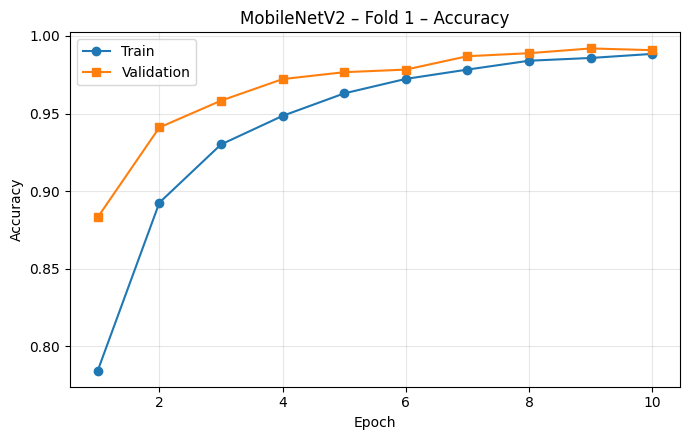

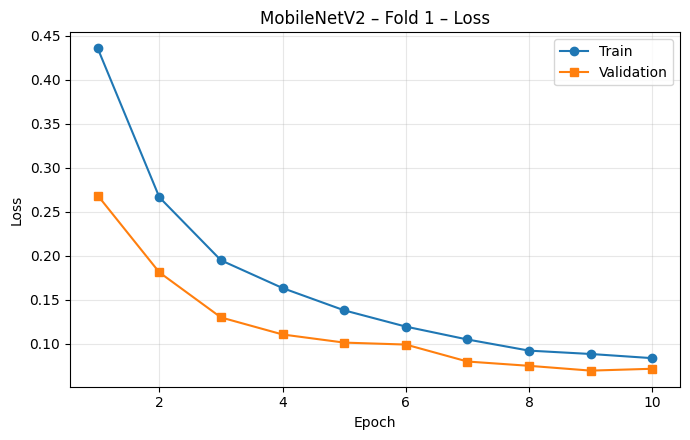

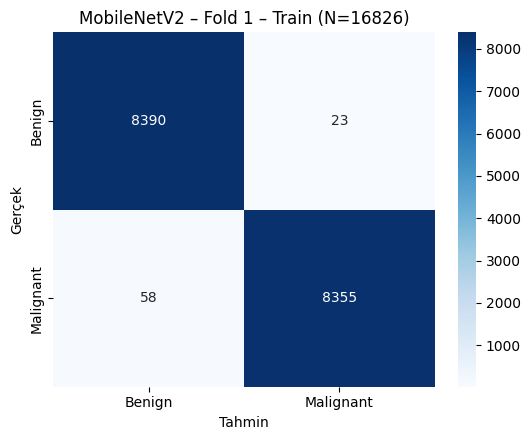

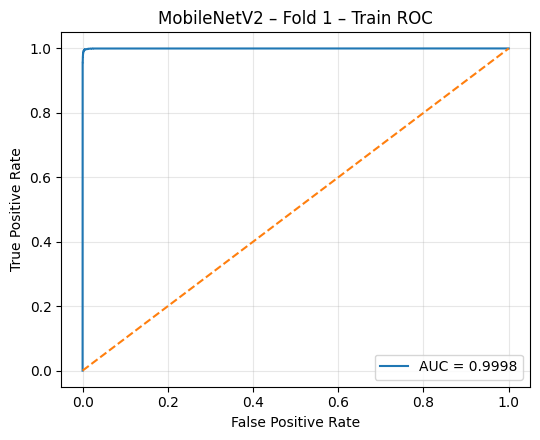

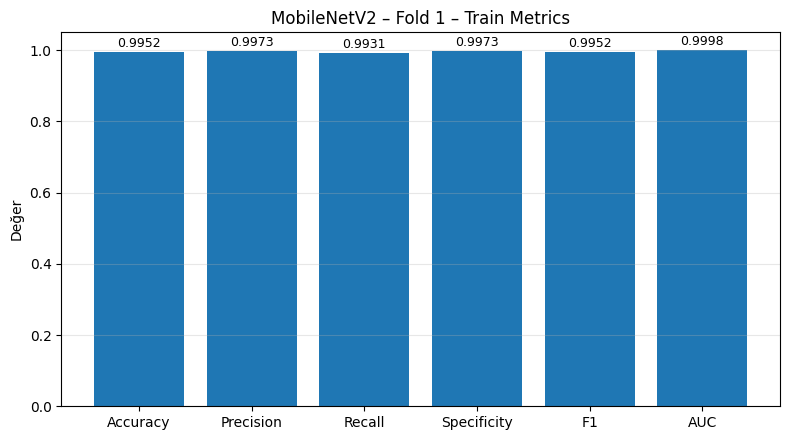

...

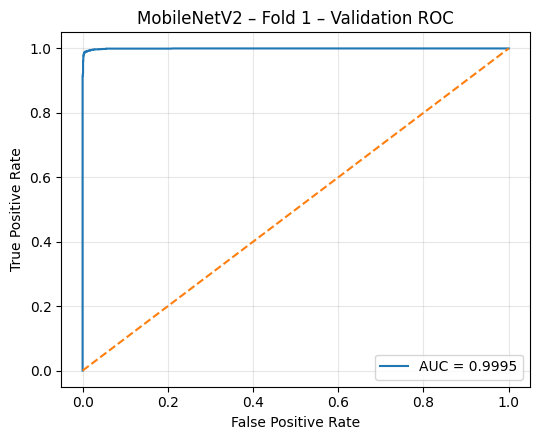

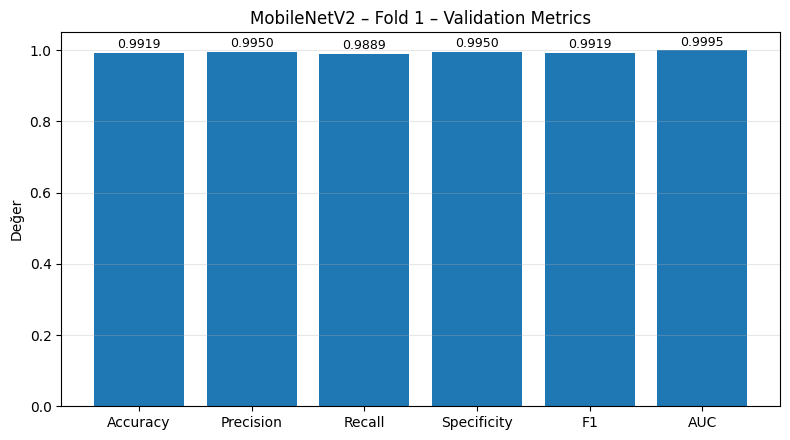

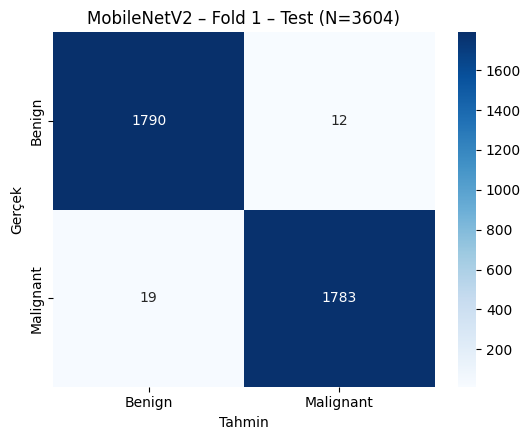

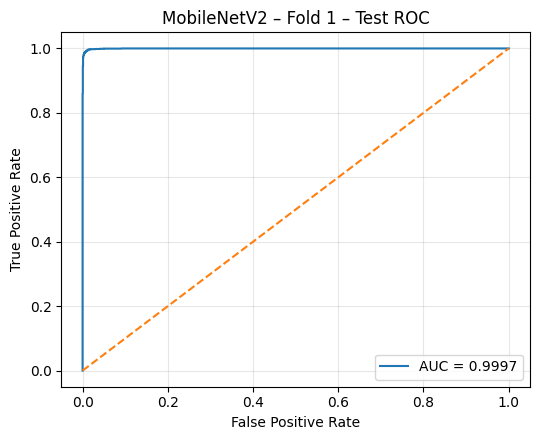

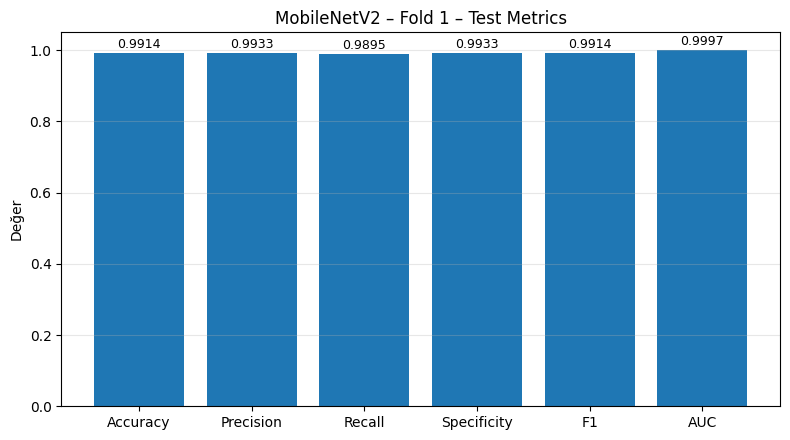

MobileNetV2 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8390.0,23.0,58.0,8355.0,0.995186,0.997255,0.993106,0.997266,0.995176,0.999798,0.058845
Validation,3594.0,1788.0,9.0,20.0,1777.0,0.991931,0.994961,0.988870,0.994992,0.991906,0.999533,0.069546
Test,3604.0,1790.0,12.0,19.0,1783.0,0.991398,0.993315,0.989456,0.993341,0.991382,0.999656,0.066095


✓ MobileNetV2 Fold 1: best epoch 9 | Test acc 0.9914
MobileNetV2 | Fold 2 | Epoch 01/10 | Train loss 0.4380 acc 0.7828 | Val loss 0.2508 acc 0.8993
MobileNetV2 | Fold 2 | Epoch 02/10 | Train loss 0.2641 acc 0.8943 | Val loss 0.1727 acc 0.9371
MobileNetV2 | Fold 2 | Epoch 03/10 | Train loss 0.1968 acc 0.9322 | Val loss 0.1269 acc 0.9730
MobileNetV2 | Fold 2 | Epoch 04/10 | Train loss 0.1656 acc 0.9495 | Val loss 0.1057 acc 0.9763
MobileNetV2 | Fold 2 | Epoch 05/10 | Train loss 0.1374 acc 0.9630 | Val loss 0.1030 acc 0.9800
MobileNetV2 | Fold 2 | Epoch 06/10 | Train loss 0.1173 acc 0.9728 | Val loss 0.0941 acc 0.9800
MobileNetV2 | Fold 2 | Epoch 07/10 | Train loss 0.1039 acc 0.9792 | Val loss 0.0716 acc 0.9894
MobileNetV2 | Fold 2 | Epoch 08/10 | Train loss 0.0936 acc 0.9831 | Val loss 0.0679 acc 0.9914
MobileNetV2 | Fold 2 | Epoch 09/10 | Train loss 0.0855 acc 0.9879 | Val loss 0.0692 acc 0.9908
MobileNetV2 | Fold 2 | Epoch 10/10 | Train loss 0.0829 acc 0.9881 | Val loss 0.0669 acc 0.99

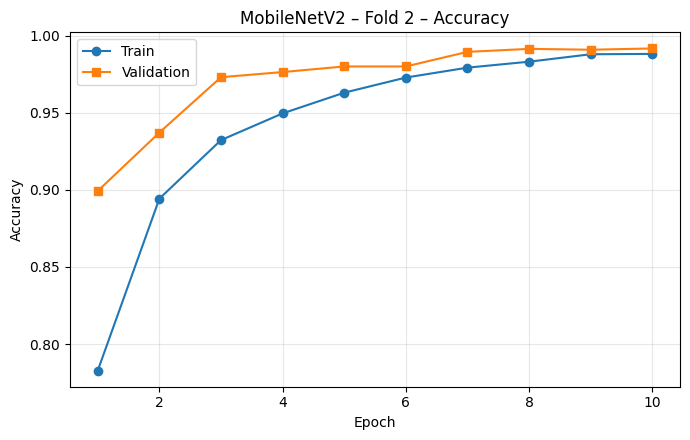

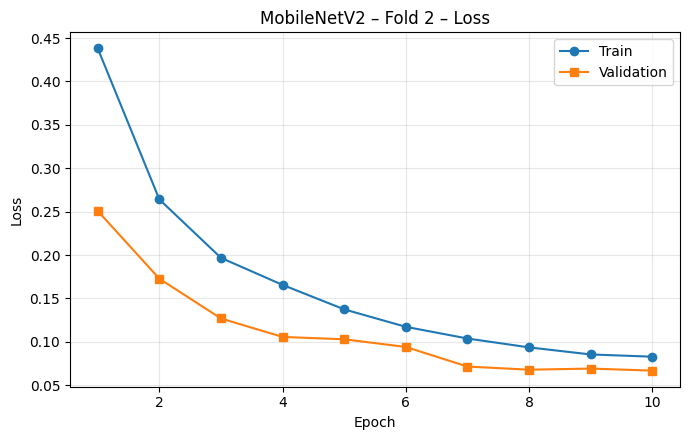

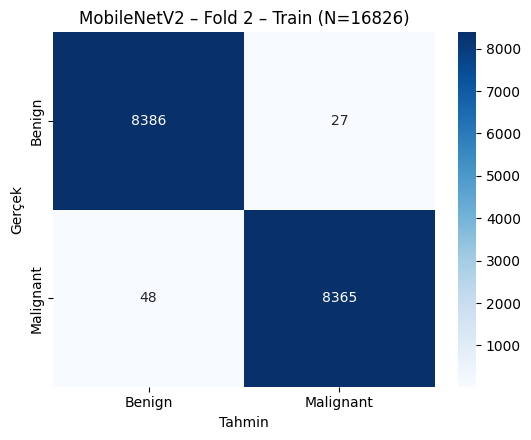

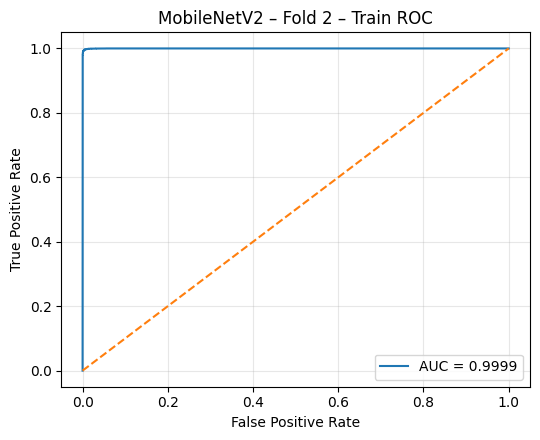

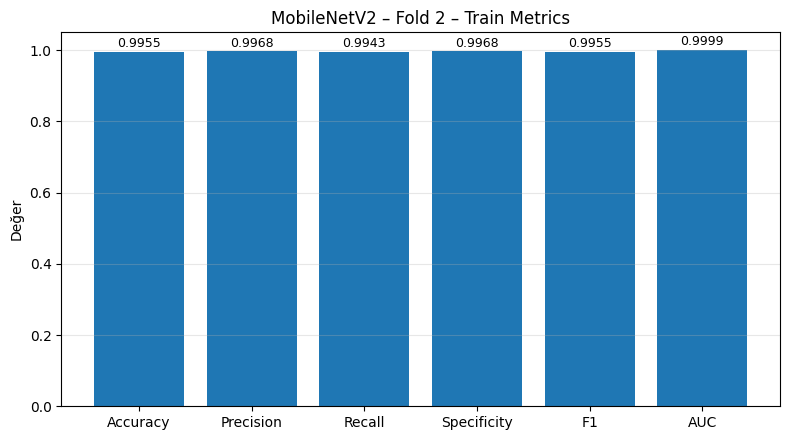

...

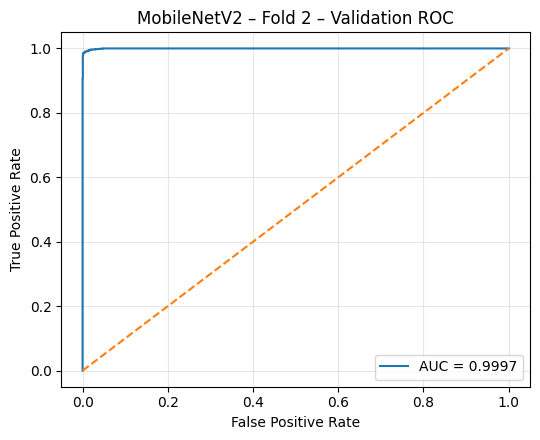

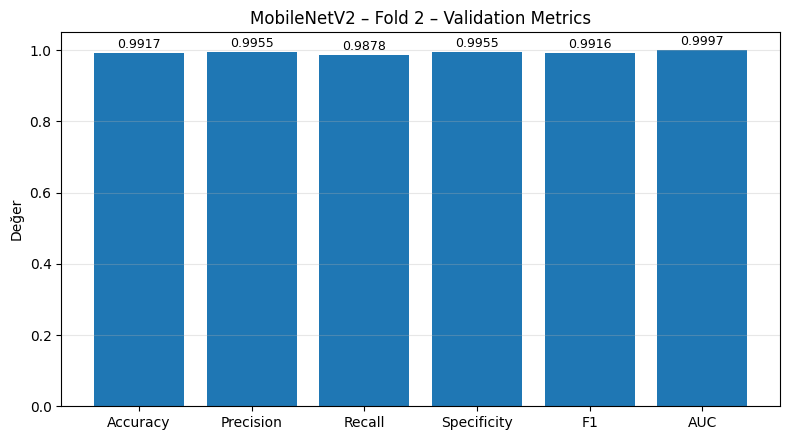

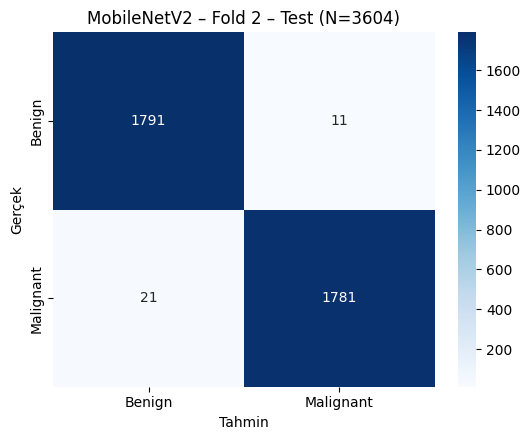

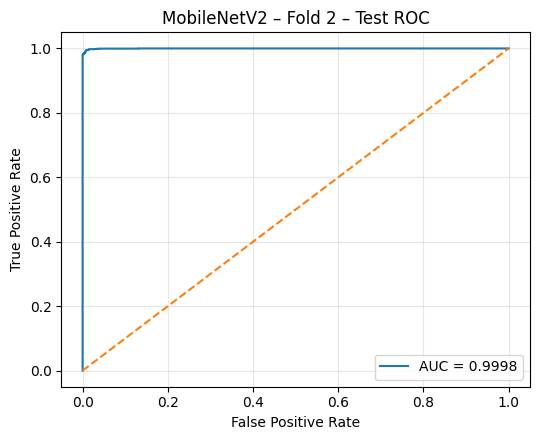

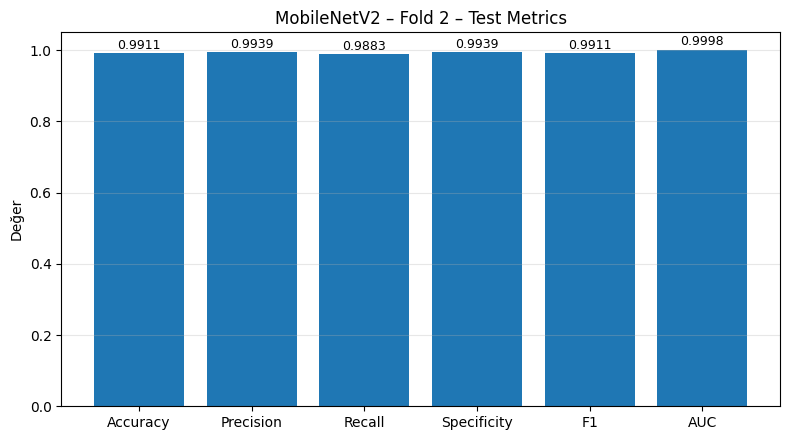

MobileNetV2 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8386.0,27.0,48.0,8365.0,0.995543,0.996783,0.994295,0.996791,0.995537,0.999920,0.058337
Validation,3594.0,1789.0,8.0,22.0,1775.0,0.991653,0.995513,0.987757,0.995548,0.991620,0.999708,0.066887
Test,3604.0,1791.0,11.0,21.0,1781.0,0.991121,0.993862,0.988346,0.993896,0.991096,0.999753,0.065548


✓ MobileNetV2 Fold 2: best epoch 10 | Test acc 0.9911
MobileNetV2 | Fold 3 | Epoch 01/10 | Train loss 0.4392 acc 0.7826 | Val loss 0.2391 acc 0.9043
MobileNetV2 | Fold 3 | Epoch 02/10 | Train loss 0.2675 acc 0.8899 | Val loss 0.1730 acc 0.9438
MobileNetV2 | Fold 3 | Epoch 03/10 | Train loss 0.1946 acc 0.9337 | Val loss 0.1530 acc 0.9527
MobileNetV2 | Fold 3 | Epoch 04/10 | Train loss 0.1662 acc 0.9490 | Val loss 0.1145 acc 0.9758
MobileNetV2 | Fold 3 | Epoch 05/10 | Train loss 0.1347 acc 0.9643 | Val loss 0.0828 acc 0.9839
MobileNetV2 | Fold 3 | Epoch 06/10 | Train loss 0.1162 acc 0.9728 | Val loss 0.0783 acc 0.9872
MobileNetV2 | Fold 3 | Epoch 07/10 | Train loss 0.1051 acc 0.9784 | Val loss 0.0797 acc 0.9886
MobileNetV2 | Fold 3 | Epoch 08/10 | Train loss 0.0902 acc 0.9853 | Val loss 0.0682 acc 0.9911
MobileNetV2 | Fold 3 | Epoch 09/10 | Train loss 0.0867 acc 0.9870 | Val loss 0.0633 acc 0.9950
MobileNetV2 | Fold 3 | Epoch 10/10 | Train loss 0.0802 acc 0.9900 | Val loss 0.0628 acc 0.9

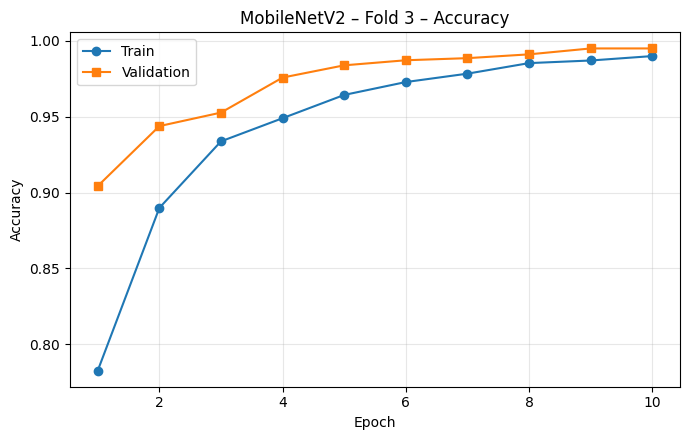

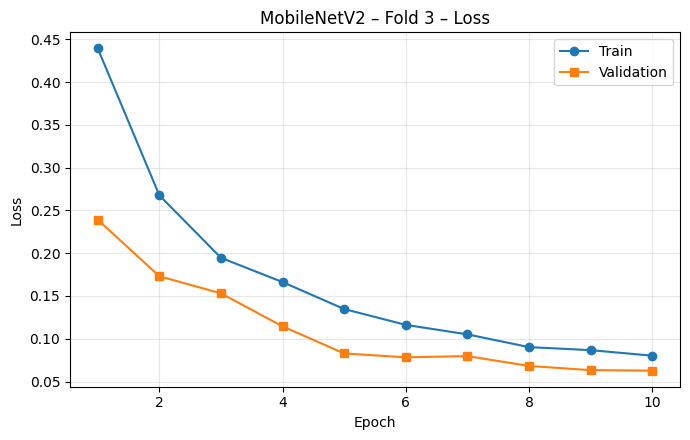

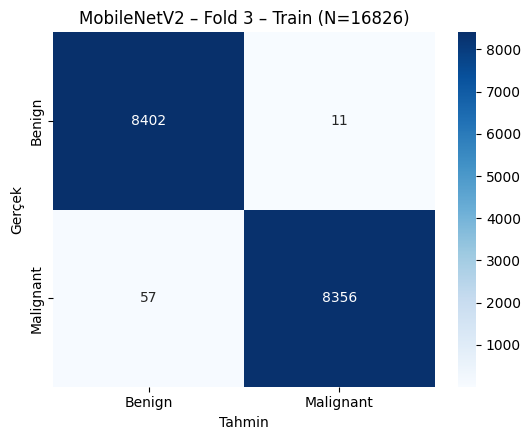

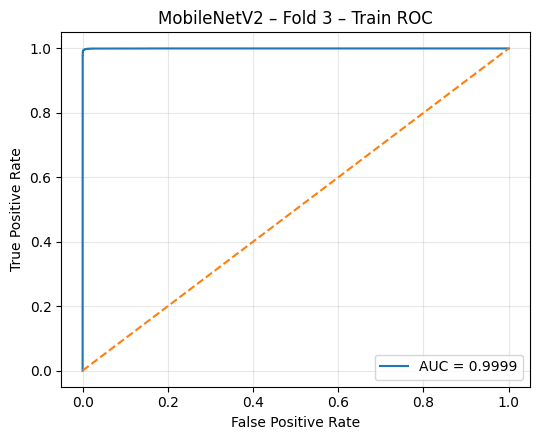

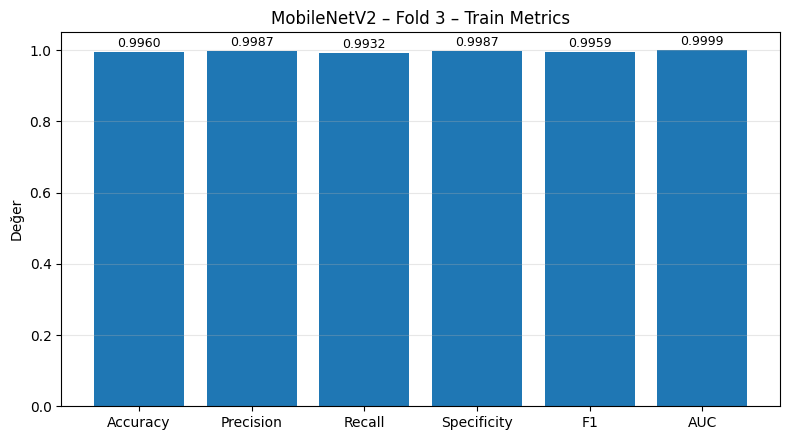

...

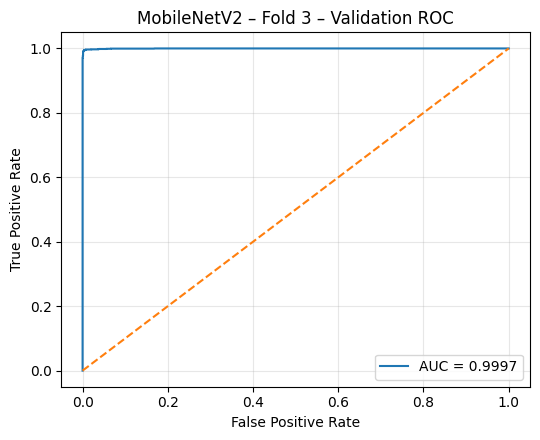

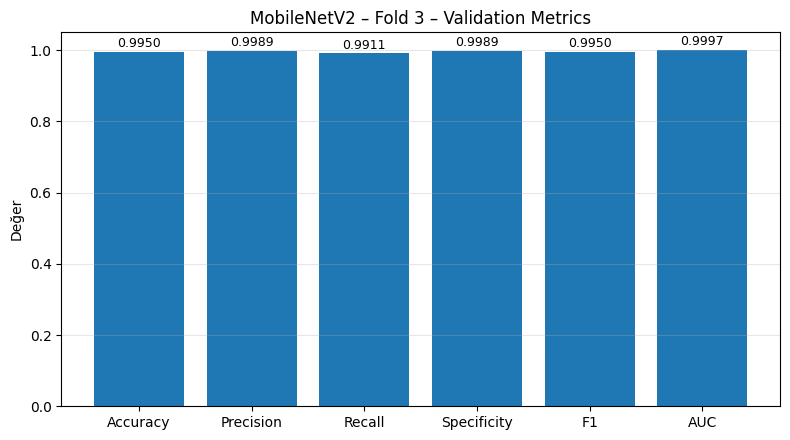

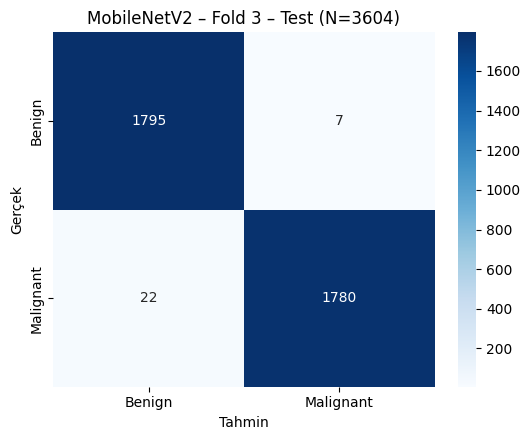

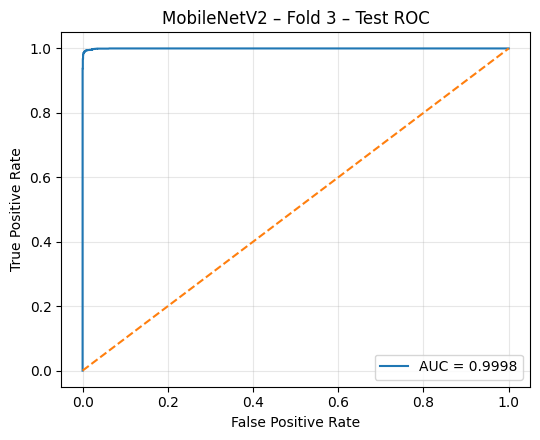

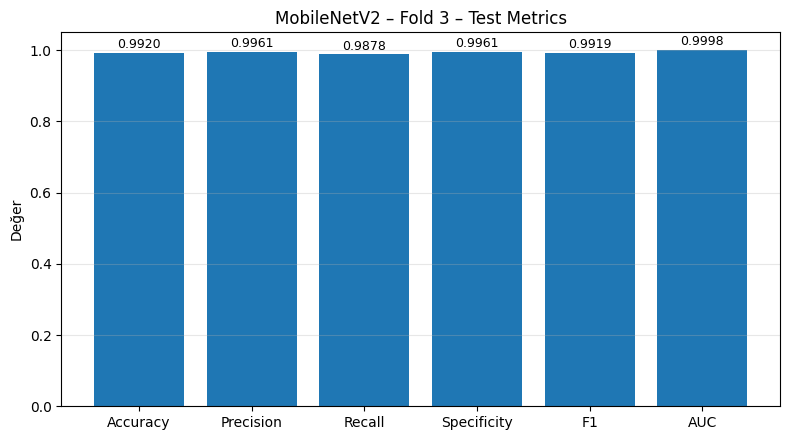

MobileNetV2 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8402.0,11.0,57.0,8356.0,0.995959,0.998685,0.993225,0.998692,0.995948,0.999917,0.057873
Validation,3594.0,1795.0,2.0,16.0,1781.0,0.994992,0.998878,0.991096,0.998887,0.994972,0.999742,0.062779
Test,3604.0,1795.0,7.0,22.0,1780.0,0.991953,0.996083,0.987791,0.996115,0.991920,0.999768,0.065055


✓ MobileNetV2 Fold 3: best epoch 10 | Test acc 0.9920
MobileNetV2 | Fold 4 | Epoch 01/10 | Train loss 0.4373 acc 0.7828 | Val loss 0.2764 acc 0.8817
MobileNetV2 | Fold 4 | Epoch 02/10 | Train loss 0.2635 acc 0.8954 | Val loss 0.1892 acc 0.9329
MobileNetV2 | Fold 4 | Epoch 03/10 | Train loss 0.1954 acc 0.9337 | Val loss 0.1402 acc 0.9591
MobileNetV2 | Fold 4 | Epoch 04/10 | Train loss 0.1585 acc 0.9512 | Val loss 0.1131 acc 0.9680
MobileNetV2 | Fold 4 | Epoch 05/10 | Train loss 0.1351 acc 0.9627 | Val loss 0.1033 acc 0.9758
MobileNetV2 | Fold 4 | Epoch 06/10 | Train loss 0.1142 acc 0.9742 | Val loss 0.0965 acc 0.9802
MobileNetV2 | Fold 4 | Epoch 07/10 | Train loss 0.1032 acc 0.9784 | Val loss 0.0815 acc 0.9891
MobileNetV2 | Fold 4 | Epoch 08/10 | Train loss 0.0918 acc 0.9851 | Val loss 0.0751 acc 0.9886
MobileNetV2 | Fold 4 | Epoch 09/10 | Train loss 0.0862 acc 0.9866 | Val loss 0.0762 acc 0.9889
MobileNetV2 | Fold 4 | Epoch 10/10 | Train loss 0.0814 acc 0.9891 | Val loss 0.0728 acc 0.9

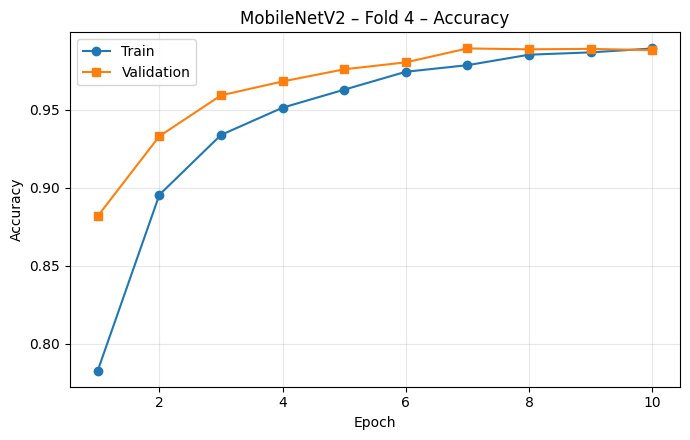

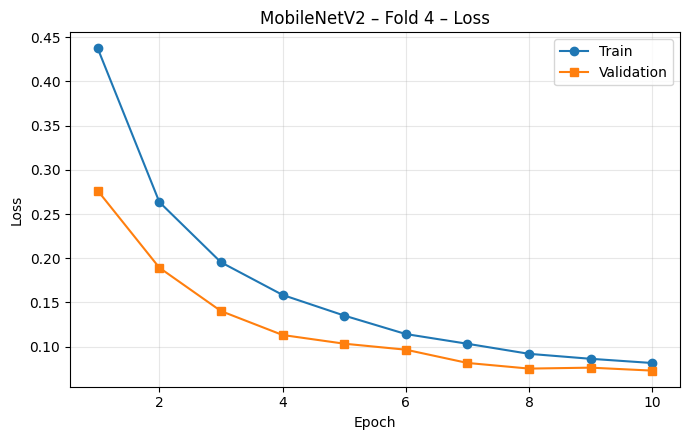

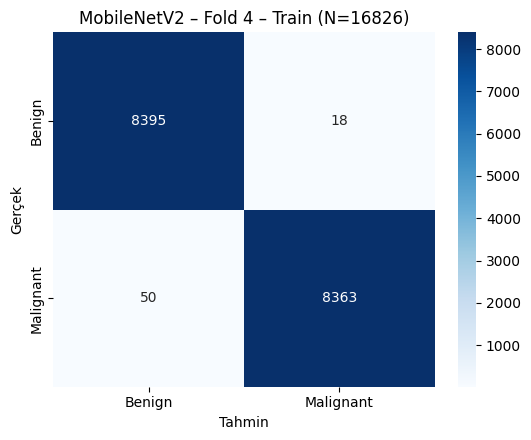

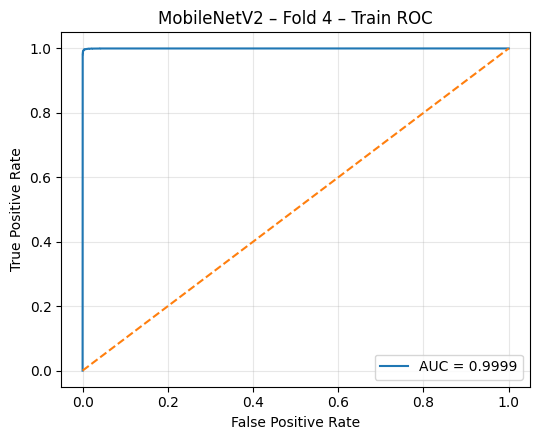

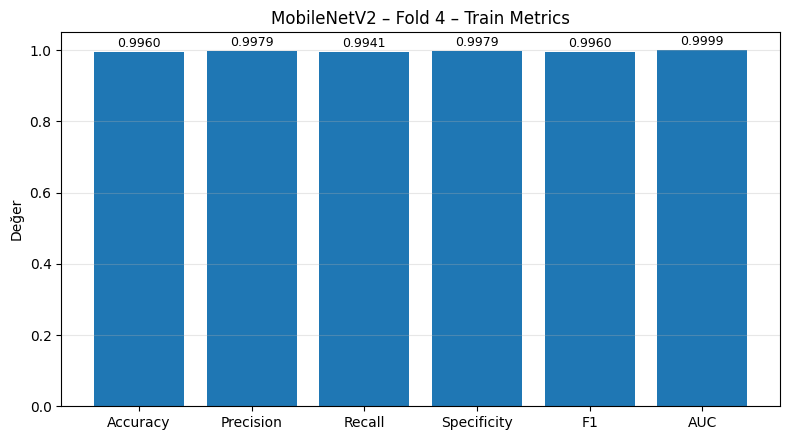

...

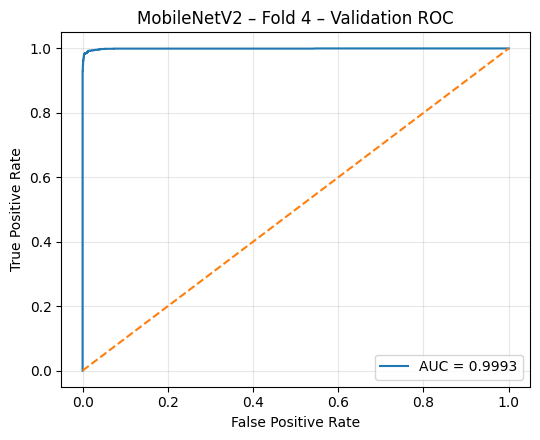

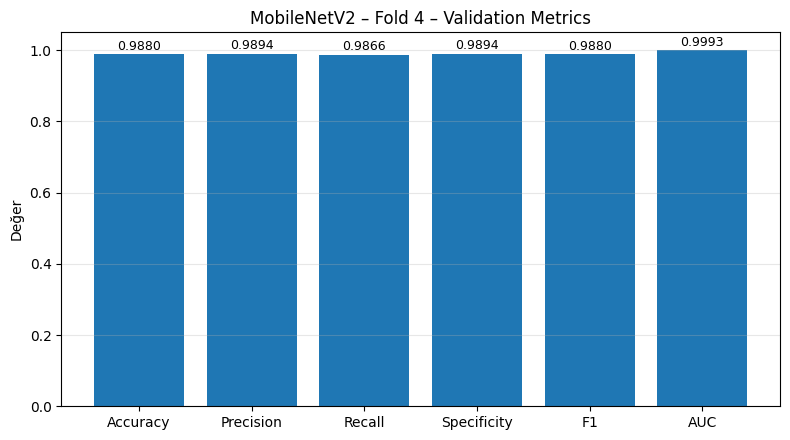

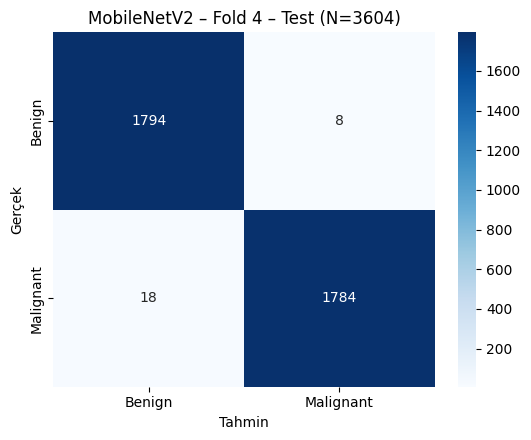

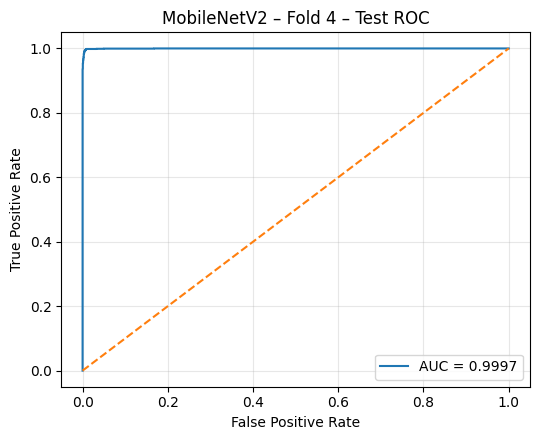

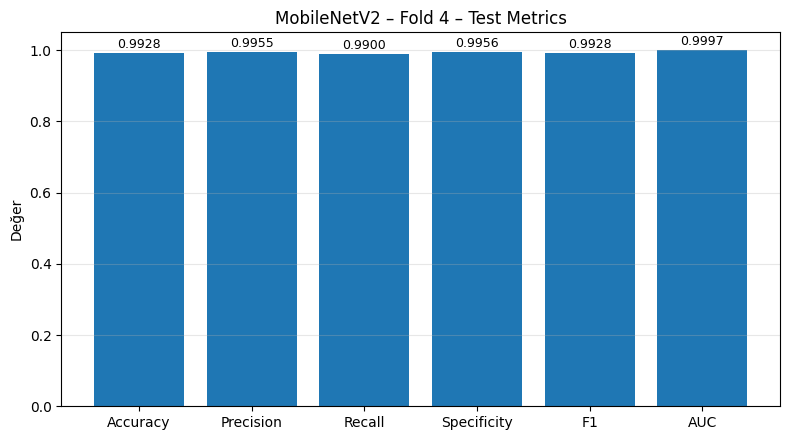

MobileNetV2 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8395.0,18.0,50.0,8363.0,0.995959,0.997852,0.994057,0.997860,0.995951,0.999896,0.059059
Validation,3594.0,1778.0,19.0,24.0,1773.0,0.988036,0.989397,0.986644,0.989427,0.988019,0.999273,0.072814
Test,3604.0,1794.0,8.0,18.0,1784.0,0.992786,0.995536,0.990011,0.995560,0.992766,0.999717,0.066284


✓ MobileNetV2 Fold 4: best epoch 10 | Test acc 0.9928
MobileNetV2 | Fold 5 | Epoch 01/10 | Train loss 0.4377 acc 0.7828 | Val loss 0.2408 acc 0.9037
MobileNetV2 | Fold 5 | Epoch 02/10 | Train loss 0.2632 acc 0.8945 | Val loss 0.1713 acc 0.9469
MobileNetV2 | Fold 5 | Epoch 03/10 | Train loss 0.1955 acc 0.9347 | Val loss 0.1589 acc 0.9413
MobileNetV2 | Fold 5 | Epoch 04/10 | Train loss 0.1619 acc 0.9500 | Val loss 0.1038 acc 0.9769
MobileNetV2 | Fold 5 | Epoch 05/10 | Train loss 0.1327 acc 0.9653 | Val loss 0.0957 acc 0.9755
MobileNetV2 | Fold 5 | Epoch 06/10 | Train loss 0.1159 acc 0.9736 | Val loss 0.1052 acc 0.9755
MobileNetV2 | Fold 5 | Epoch 07/10 | Train loss 0.1025 acc 0.9793 | Val loss 0.0818 acc 0.9861
MobileNetV2 | Fold 5 | Epoch 08/10 | Train loss 0.0917 acc 0.9848 | Val loss 0.0727 acc 0.9900
MobileNetV2 | Fold 5 | Epoch 09/10 | Train loss 0.0845 acc 0.9872 | Val loss 0.0687 acc 0.9917
MobileNetV2 | Fold 5 | Epoch 10/10 | Train loss 0.0817 acc 0.9886 | Val loss 0.0674 acc 0.9

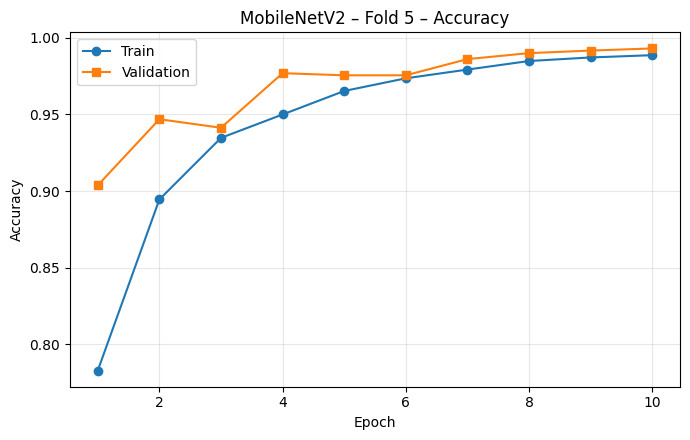

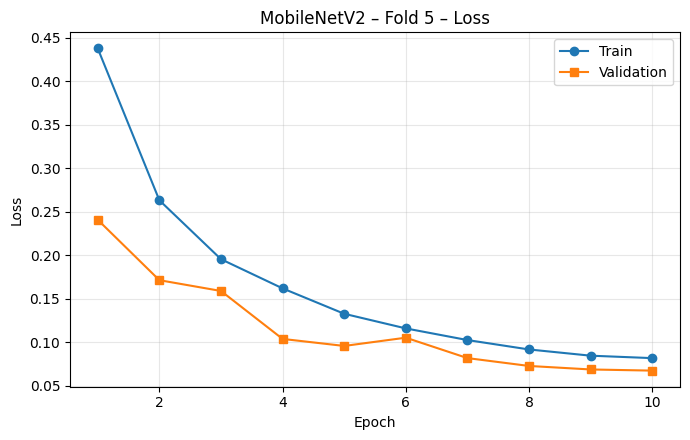

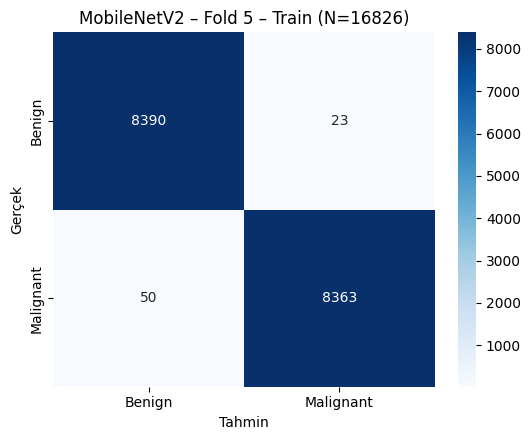

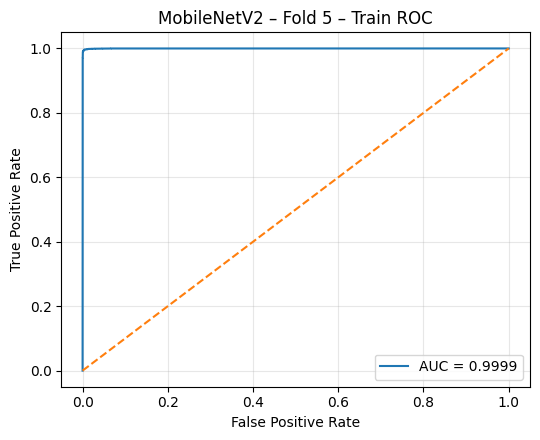

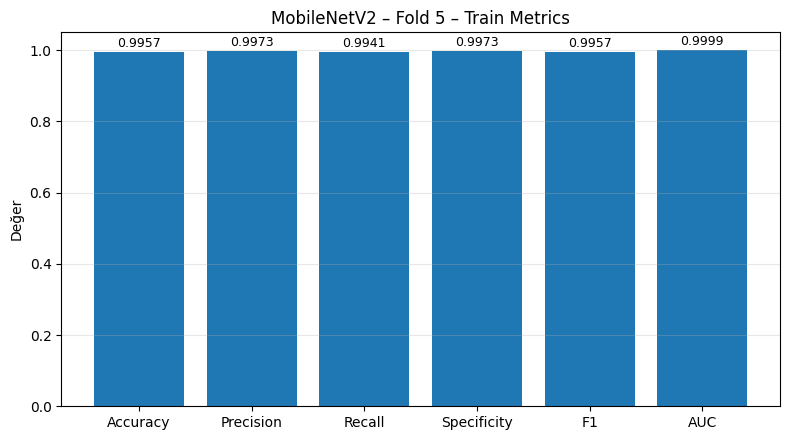

...

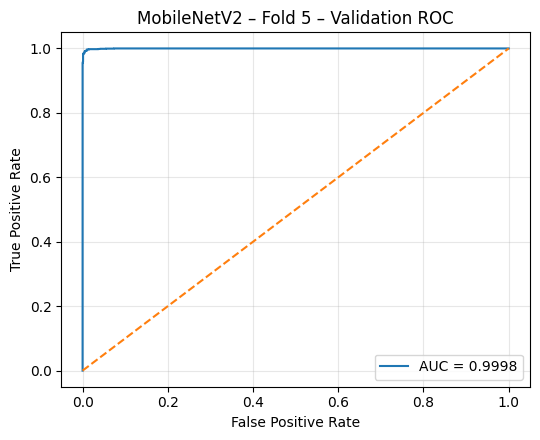

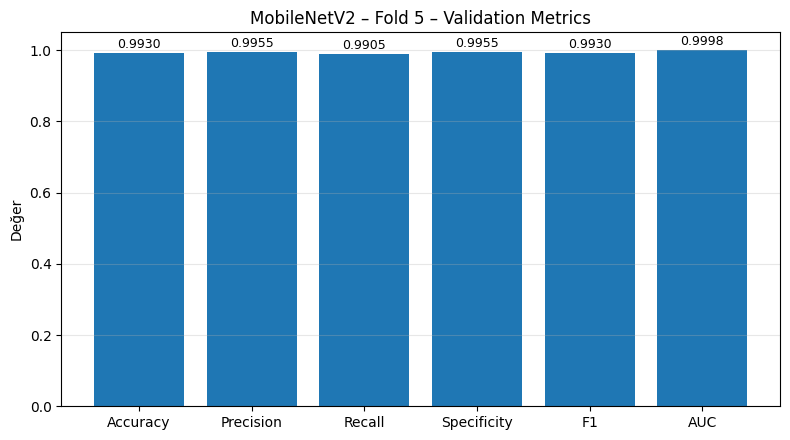

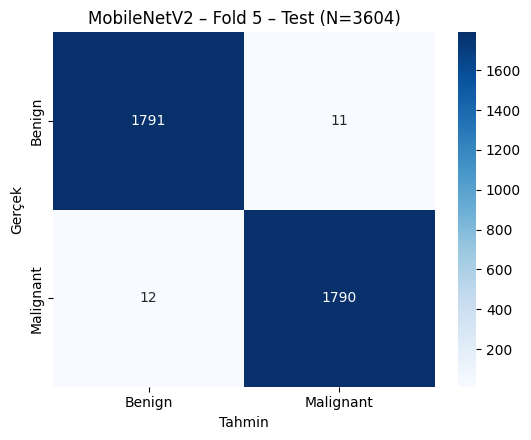

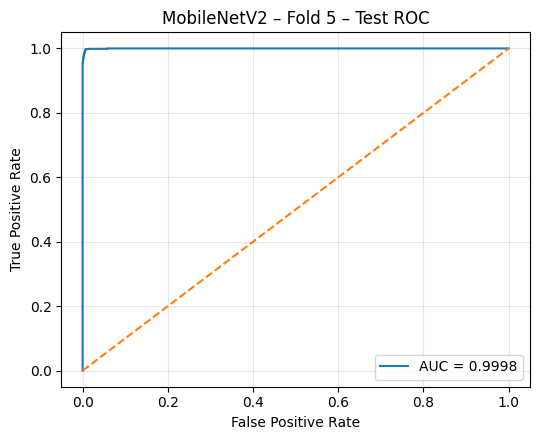

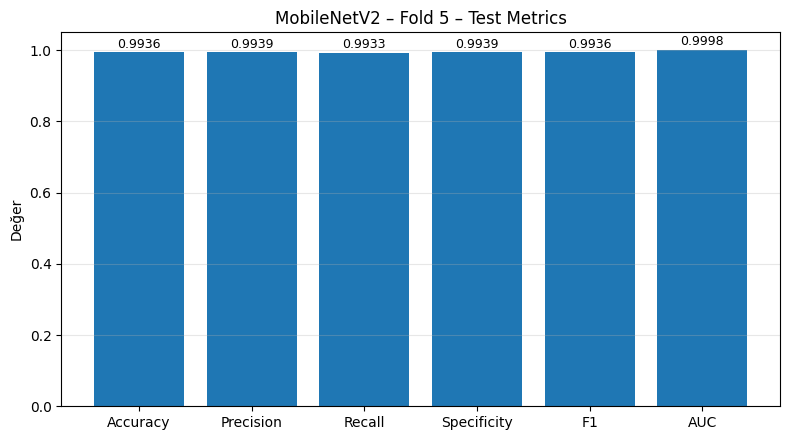

MobileNetV2 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8390.0,23.0,50.0,8363.0,0.995661,0.997257,0.994057,0.997266,0.995655,0.999894,0.059821
Validation,3594.0,1789.0,8.0,17.0,1780.0,0.993044,0.995526,0.990540,0.995548,0.993026,0.999758,0.067384
Test,3604.0,1791.0,11.0,12.0,1790.0,0.993618,0.993892,0.993341,0.993896,0.993616,0.999788,0.065414


✓ MobileNetV2 Fold 5: best epoch 10 | Test acc 0.9936
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 221MB/s] 


InceptionV3 | Fold 1 | Epoch 01/10 | Train loss 0.4078 acc 0.7976 | Val loss 0.2054 acc 0.9151
InceptionV3 | Fold 1 | Epoch 02/10 | Train loss 0.2257 acc 0.9123 | Val loss 0.1404 acc 0.9591
InceptionV3 | Fold 1 | Epoch 03/10 | Train loss 0.1610 acc 0.9486 | Val loss 0.1020 acc 0.9722
InceptionV3 | Fold 1 | Epoch 04/10 | Train loss 0.1310 acc 0.9626 | Val loss 0.0936 acc 0.9791
InceptionV3 | Fold 1 | Epoch 05/10 | Train loss 0.1060 acc 0.9752 | Val loss 0.0923 acc 0.9841
InceptionV3 | Fold 1 | Epoch 06/10 | Train loss 0.0883 acc 0.9828 | Val loss 0.0827 acc 0.9864
InceptionV3 | Fold 1 | Epoch 07/10 | Train loss 0.0764 acc 0.9893 | Val loss 0.0663 acc 0.9950
InceptionV3 | Fold 1 | Epoch 08/10 | Train loss 0.0676 acc 0.9929 | Val loss 0.0670 acc 0.9939
InceptionV3 | Fold 1 | Epoch 09/10 | Train loss 0.0648 acc 0.9942 | Val loss 0.0609 acc 0.9967
InceptionV3 | Fold 1 | Epoch 10/10 | Train loss 0.0602 acc 0.9964 | Val loss 0.0594 acc 0.9969


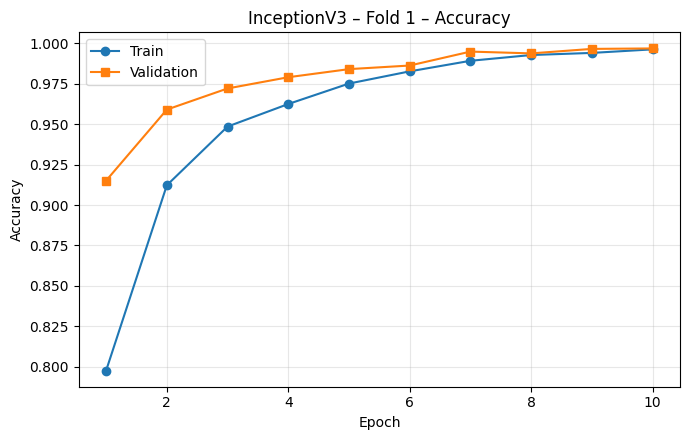

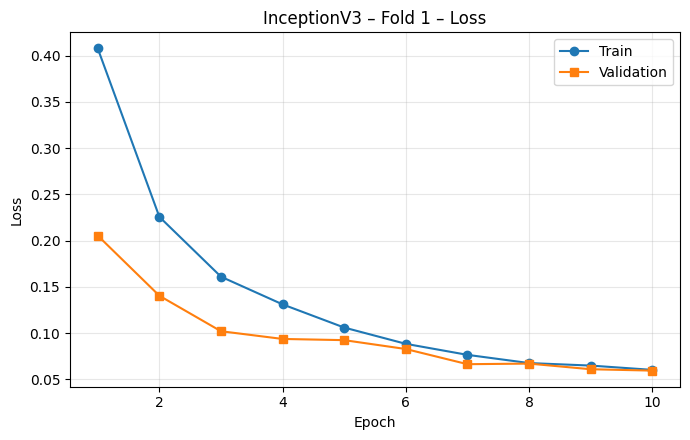

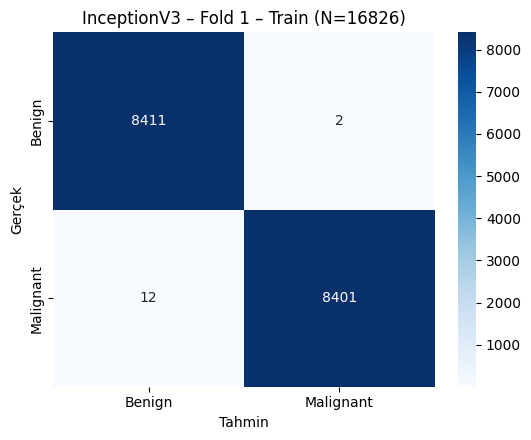

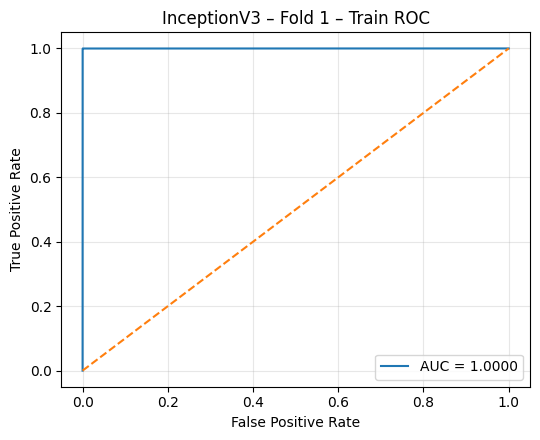

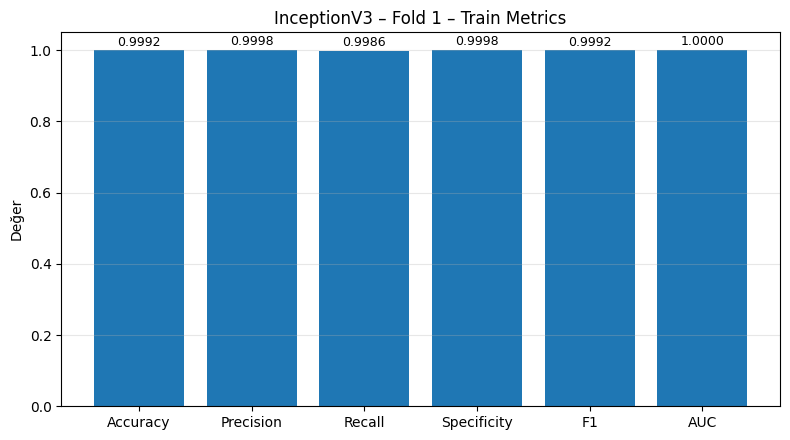

...

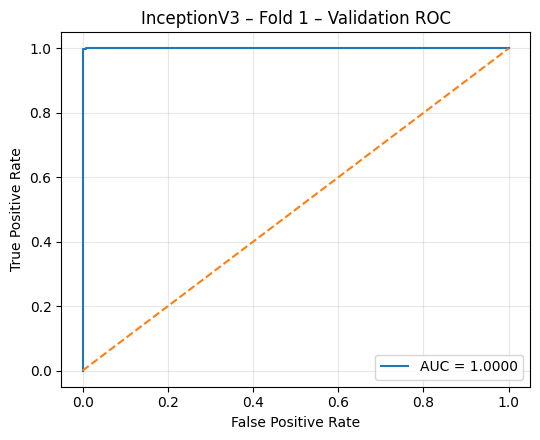

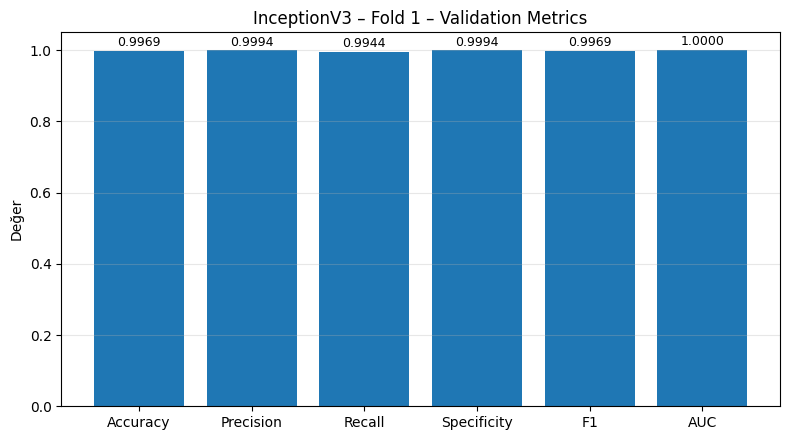

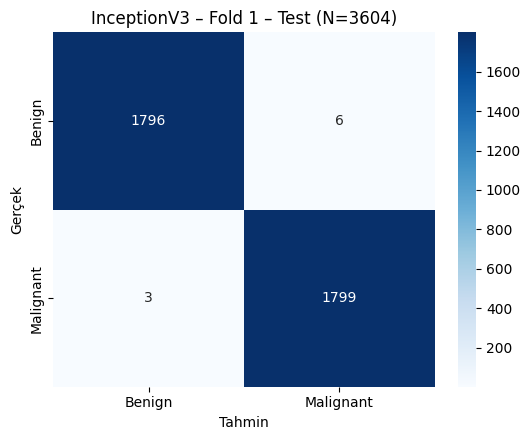

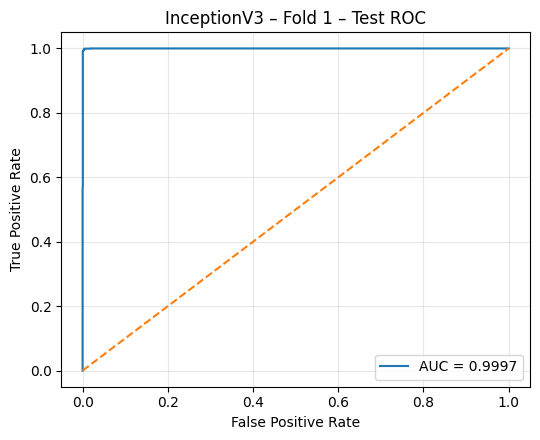

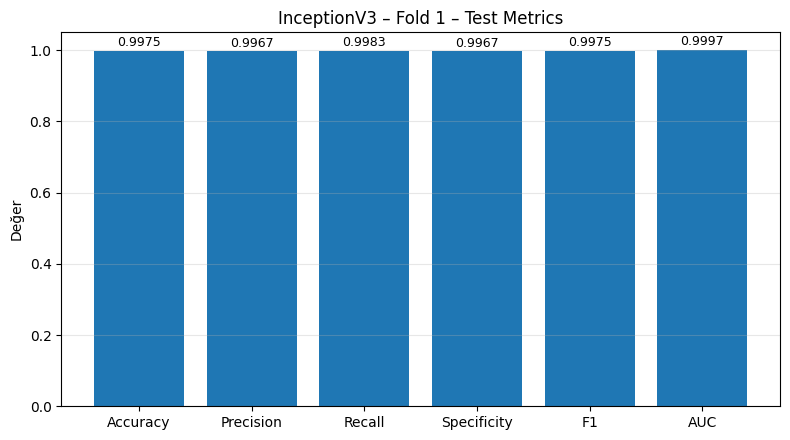

InceptionV3 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8411.0,2.0,12.0,8401.0,0.999168,0.999762,0.998574,0.999762,0.999167,0.999998,0.054712
Validation,3594.0,1796.0,1.0,10.0,1787.0,0.996939,0.999441,0.994435,0.999444,0.996932,0.999988,0.059390
Test,3604.0,1796.0,6.0,3.0,1799.0,0.997503,0.996676,0.998335,0.996670,0.997505,0.999732,0.058938


✓ InceptionV3 Fold 1: best epoch 10 | Test acc 0.9975
InceptionV3 | Fold 2 | Epoch 01/10 | Train loss 0.4095 acc 0.7965 | Val loss 0.2296 acc 0.9110
InceptionV3 | Fold 2 | Epoch 02/10 | Train loss 0.2234 acc 0.9155 | Val loss 0.1319 acc 0.9555
InceptionV3 | Fold 2 | Epoch 03/10 | Train loss 0.1635 acc 0.9472 | Val loss 0.1126 acc 0.9702
InceptionV3 | Fold 2 | Epoch 04/10 | Train loss 0.1322 acc 0.9634 | Val loss 0.0947 acc 0.9780
InceptionV3 | Fold 2 | Epoch 05/10 | Train loss 0.1070 acc 0.9752 | Val loss 0.0790 acc 0.9855
InceptionV3 | Fold 2 | Epoch 06/10 | Train loss 0.0895 acc 0.9826 | Val loss 0.0708 acc 0.9917
InceptionV3 | Fold 2 | Epoch 07/10 | Train loss 0.0764 acc 0.9885 | Val loss 0.0639 acc 0.9950
InceptionV3 | Fold 2 | Epoch 08/10 | Train loss 0.0683 acc 0.9927 | Val loss 0.0619 acc 0.9958
InceptionV3 | Fold 2 | Epoch 09/10 | Train loss 0.0640 acc 0.9945 | Val loss 0.0581 acc 0.9964
InceptionV3 | Fold 2 | Epoch 10/10 | Train loss 0.0589 acc 0.9969 | Val loss 0.0602 acc 0.9

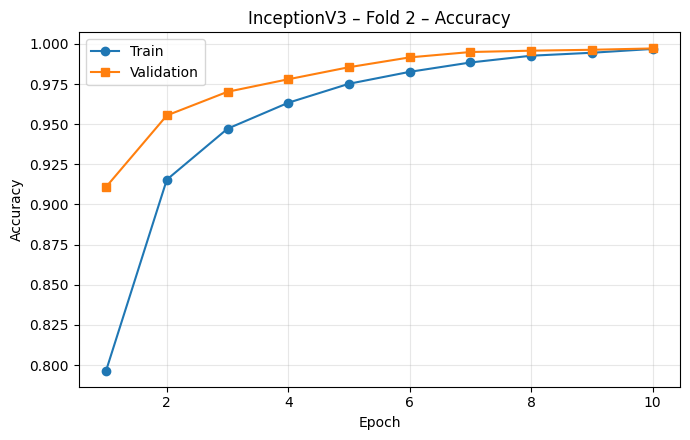

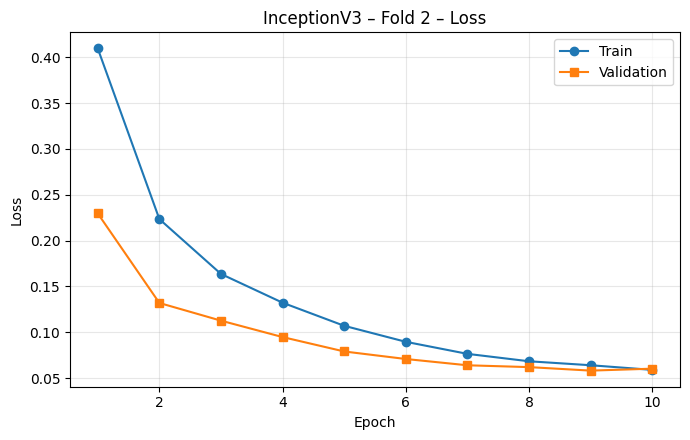

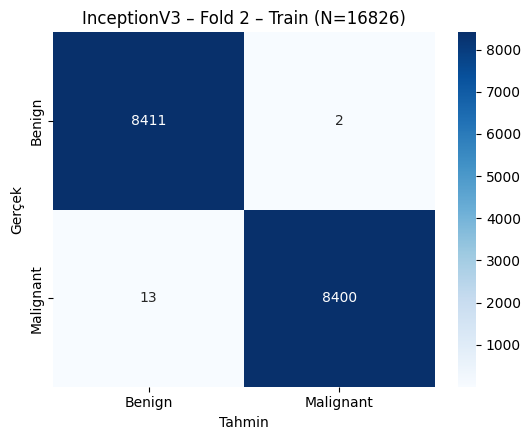

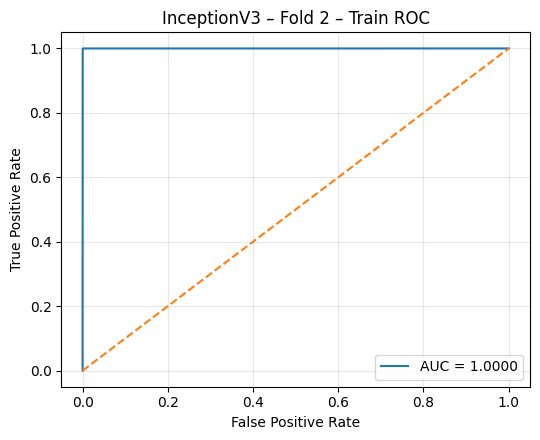

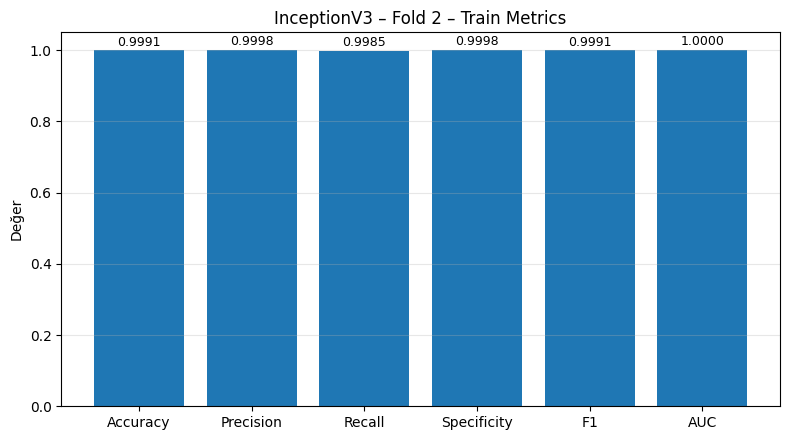

...

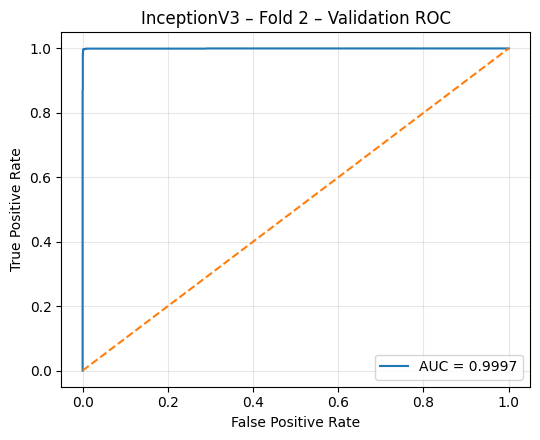

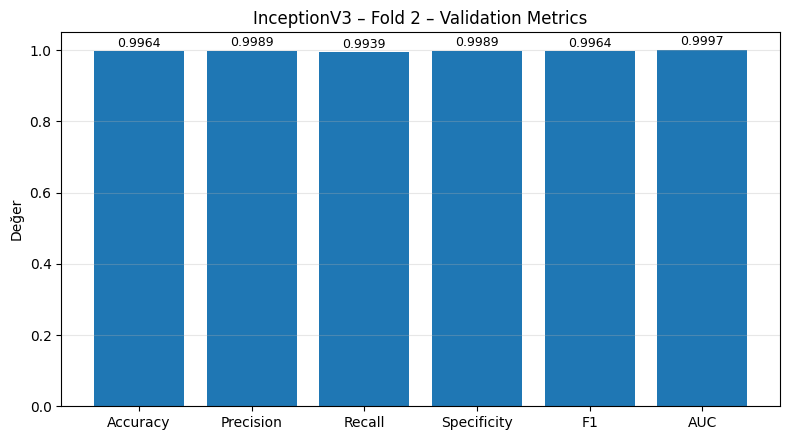

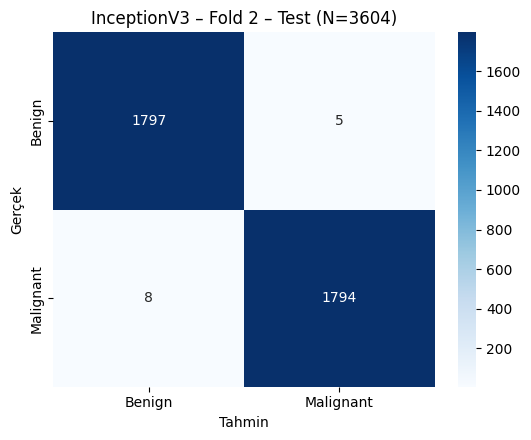

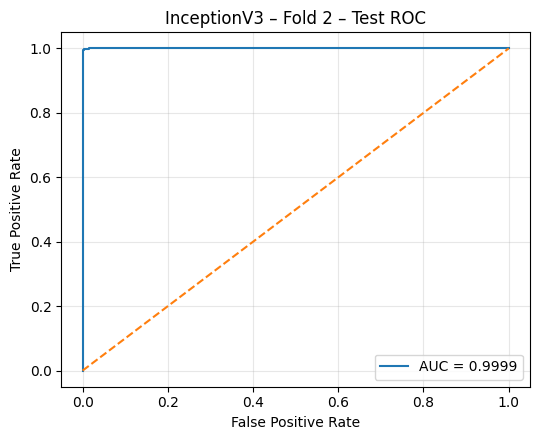

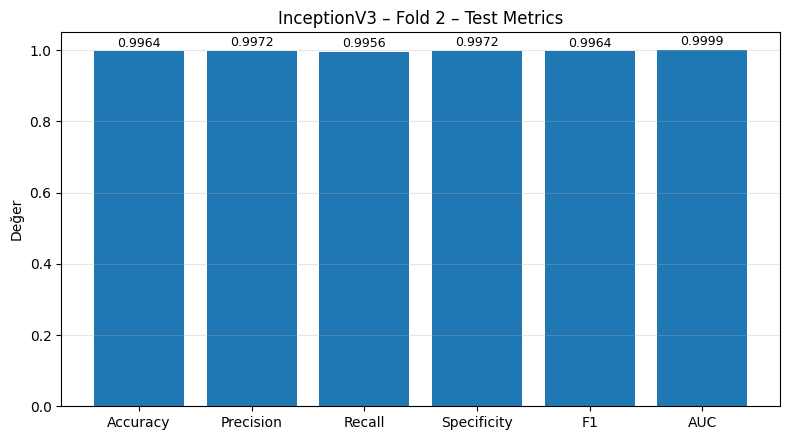

InceptionV3 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8411.0,2.0,13.0,8400.0,0.999109,0.999762,0.998455,0.999762,0.999108,0.999999,0.051430
Validation,3594.0,1795.0,2.0,11.0,1786.0,0.996383,0.998881,0.993879,0.998887,0.996374,0.999747,0.058114
Test,3604.0,1797.0,5.0,8.0,1794.0,0.996393,0.997221,0.995560,0.997225,0.996390,0.999947,0.057883


✓ InceptionV3 Fold 2: best epoch 9 | Test acc 0.9964
InceptionV3 | Fold 3 | Epoch 01/10 | Train loss 0.4199 acc 0.7901 | Val loss 0.2099 acc 0.9207
InceptionV3 | Fold 3 | Epoch 02/10 | Train loss 0.2309 acc 0.9119 | Val loss 0.1262 acc 0.9616
InceptionV3 | Fold 3 | Epoch 03/10 | Train loss 0.1709 acc 0.9421 | Val loss 0.1148 acc 0.9694
InceptionV3 | Fold 3 | Epoch 04/10 | Train loss 0.1343 acc 0.9613 | Val loss 0.0994 acc 0.9750
InceptionV3 | Fold 3 | Epoch 05/10 | Train loss 0.1090 acc 0.9740 | Val loss 0.0745 acc 0.9883
InceptionV3 | Fold 3 | Epoch 06/10 | Train loss 0.0912 acc 0.9829 | Val loss 0.0736 acc 0.9903
InceptionV3 | Fold 3 | Epoch 07/10 | Train loss 0.0768 acc 0.9885 | Val loss 0.0648 acc 0.9928
InceptionV3 | Fold 3 | Epoch 08/10 | Train loss 0.0671 acc 0.9933 | Val loss 0.0582 acc 0.9964
InceptionV3 | Fold 3 | Epoch 09/10 | Train loss 0.0632 acc 0.9944 | Val loss 0.0575 acc 0.9972
InceptionV3 | Fold 3 | Epoch 10/10 | Train loss 0.0621 acc 0.9952 | Val loss 0.0609 acc 0.99

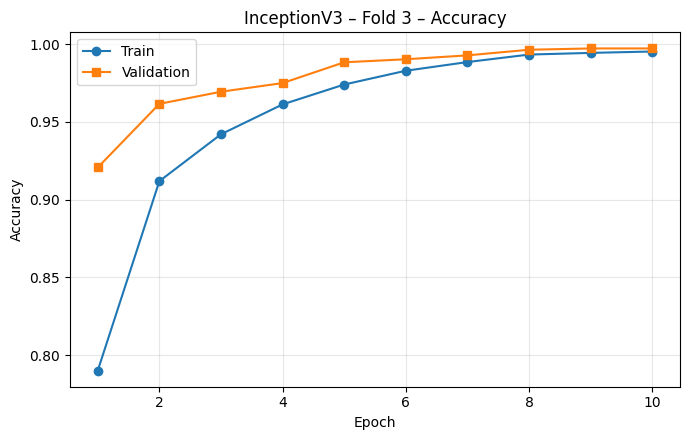

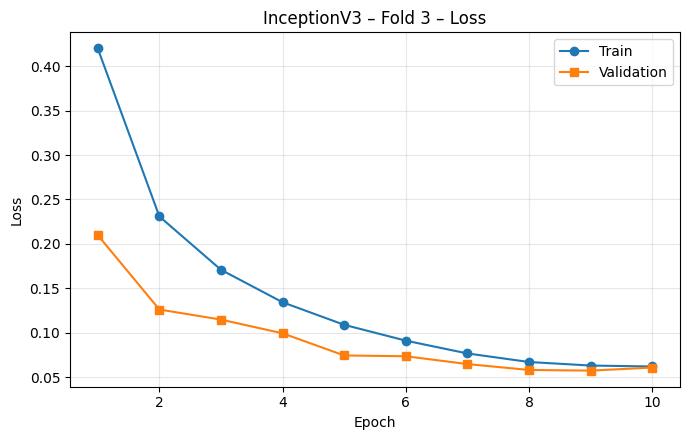

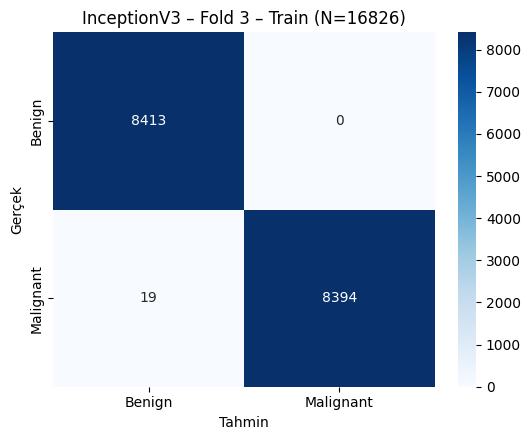

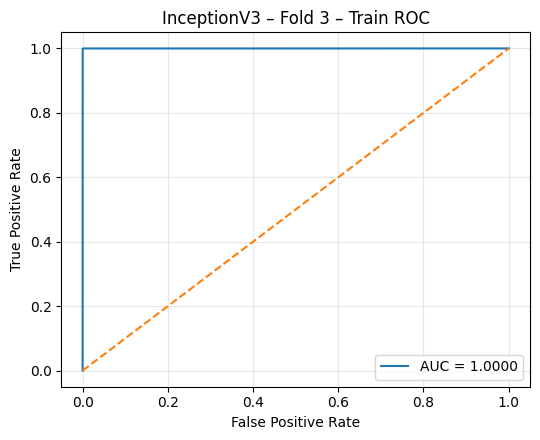

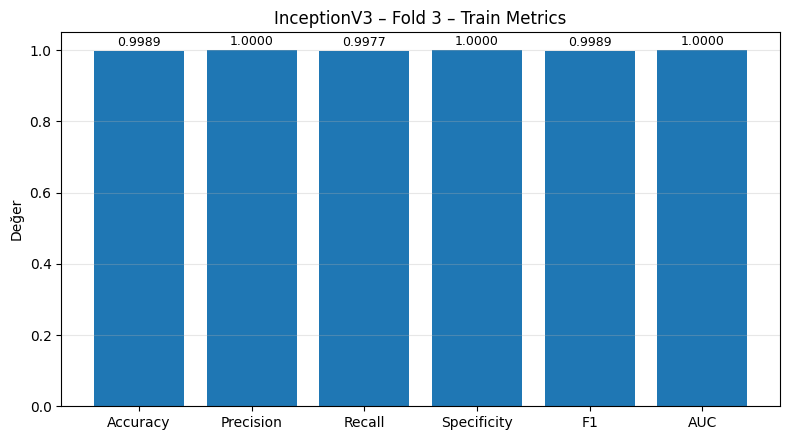

...

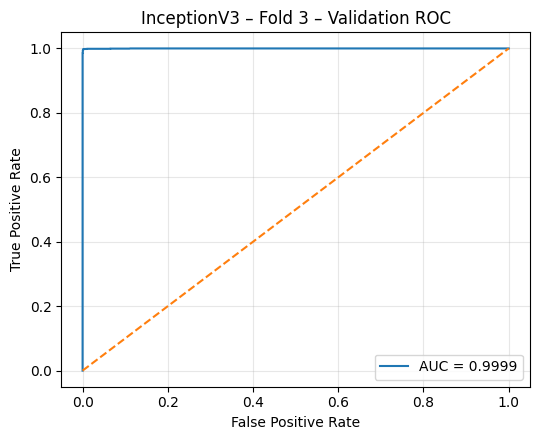

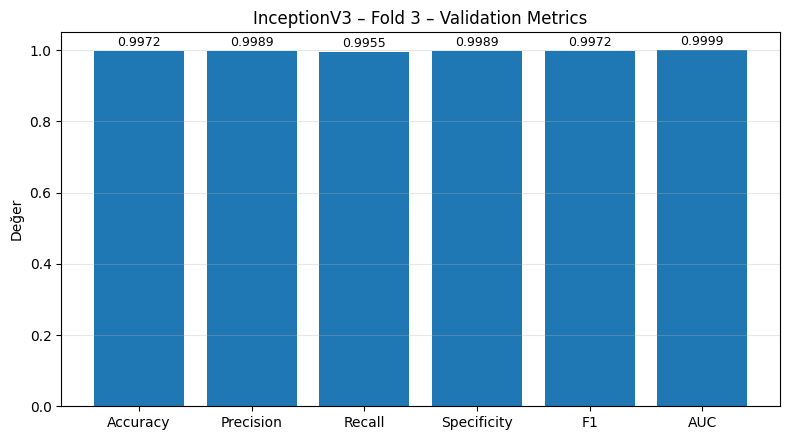

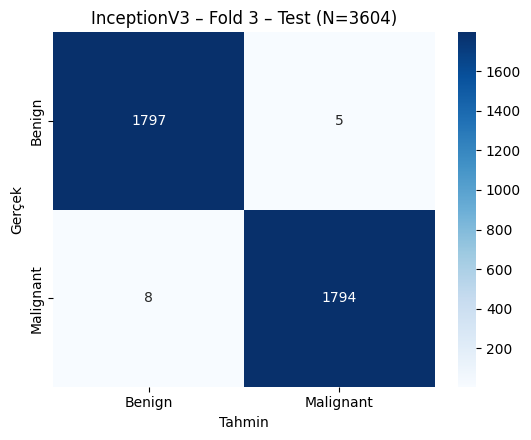

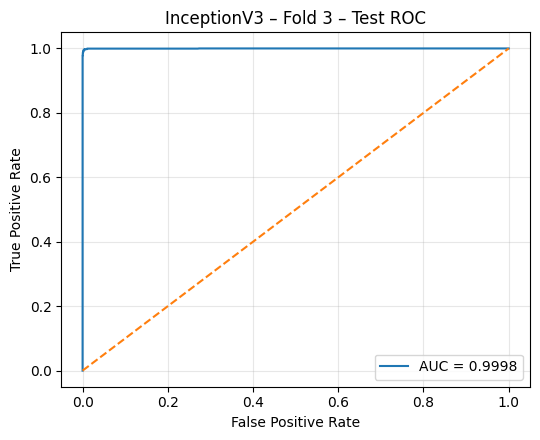

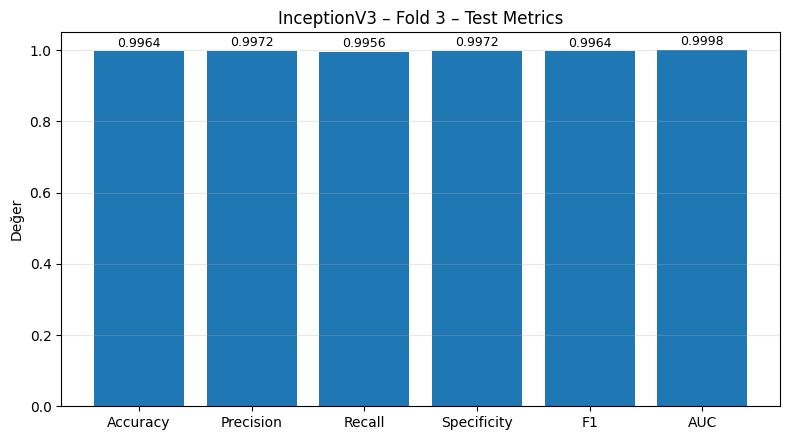

InceptionV3 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8413.0,0.0,19.0,8394.0,0.998871,1.000000,0.997742,1.000000,0.998870,0.999998,0.053746
Validation,3594.0,1795.0,2.0,8.0,1789.0,0.997218,0.998883,0.995548,0.998887,0.997213,0.999886,0.057461
Test,3604.0,1797.0,5.0,8.0,1794.0,0.996393,0.997221,0.995560,0.997225,0.996390,0.999801,0.060237


✓ InceptionV3 Fold 3: best epoch 9 | Test acc 0.9964
InceptionV3 | Fold 4 | Epoch 01/10 | Train loss 0.4142 acc 0.7931 | Val loss 0.2263 acc 0.9107
InceptionV3 | Fold 4 | Epoch 02/10 | Train loss 0.2288 acc 0.9126 | Val loss 0.1371 acc 0.9572
InceptionV3 | Fold 4 | Epoch 03/10 | Train loss 0.1662 acc 0.9433 | Val loss 0.1328 acc 0.9591
InceptionV3 | Fold 4 | Epoch 04/10 | Train loss 0.1339 acc 0.9623 | Val loss 0.0914 acc 0.9789
InceptionV3 | Fold 4 | Epoch 05/10 | Train loss 0.1103 acc 0.9736 | Val loss 0.0944 acc 0.9783
InceptionV3 | Fold 4 | Epoch 06/10 | Train loss 0.0952 acc 0.9806 | Val loss 0.0817 acc 0.9880
InceptionV3 | Fold 4 | Epoch 07/10 | Train loss 0.0800 acc 0.9876 | Val loss 0.0734 acc 0.9889
InceptionV3 | Fold 4 | Epoch 08/10 | Train loss 0.0666 acc 0.9935 | Val loss 0.0630 acc 0.9947
InceptionV3 | Fold 4 | Epoch 09/10 | Train loss 0.0655 acc 0.9941 | Val loss 0.0634 acc 0.9947
InceptionV3 | Fold 4 | Epoch 10/10 | Train loss 0.0623 acc 0.9954 | Val loss 0.0622 acc 0.99

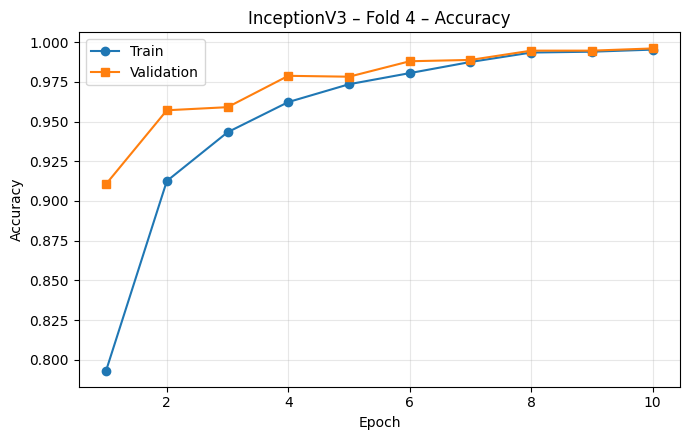

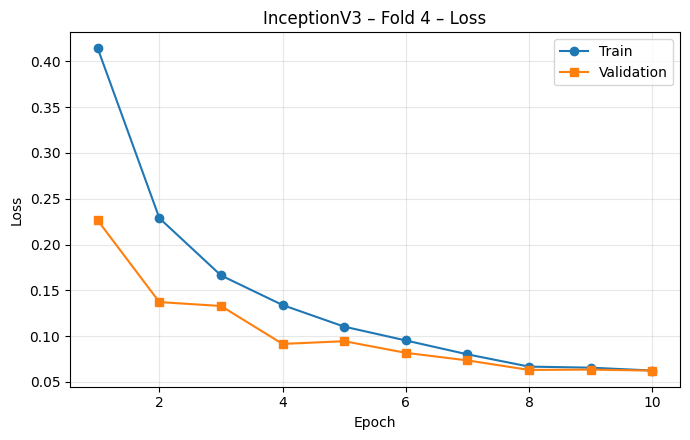

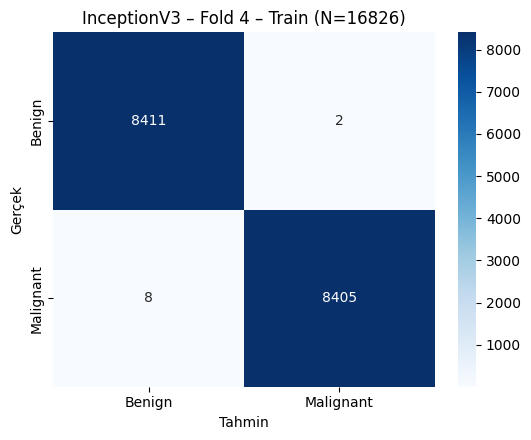

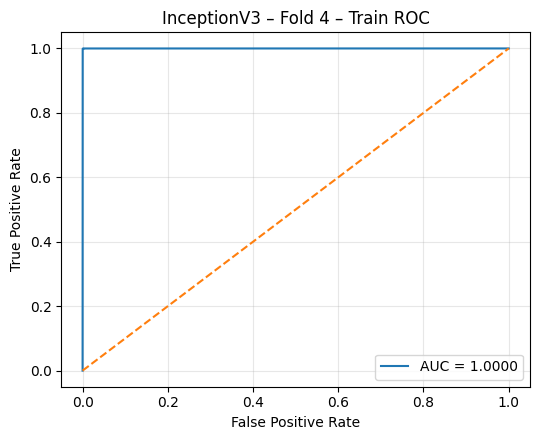

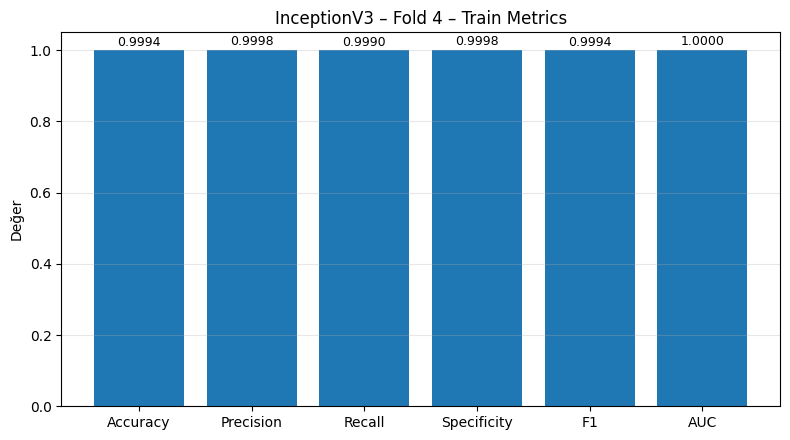

...

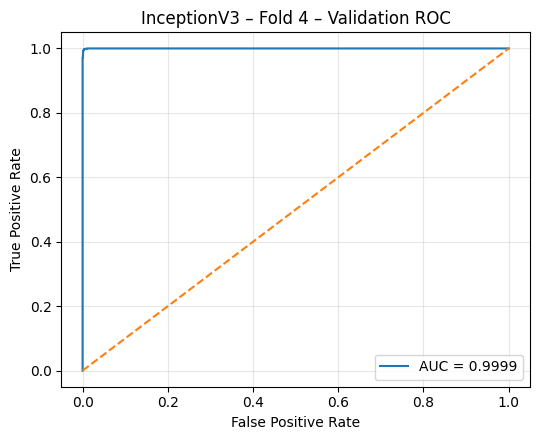

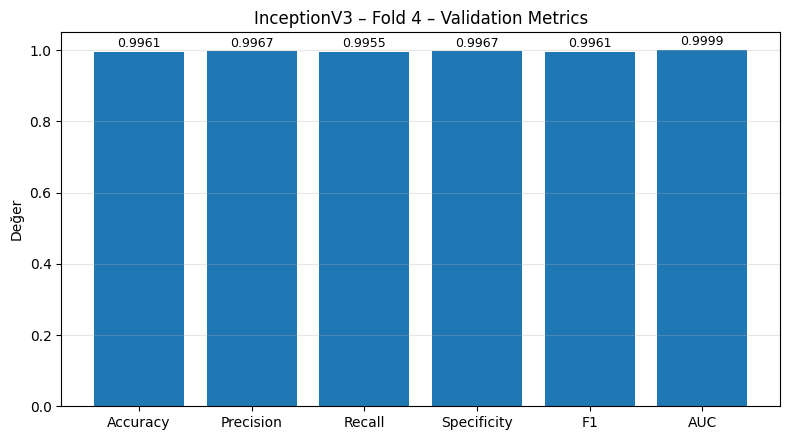

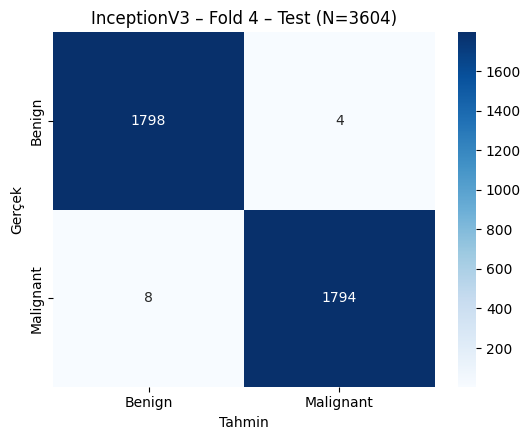

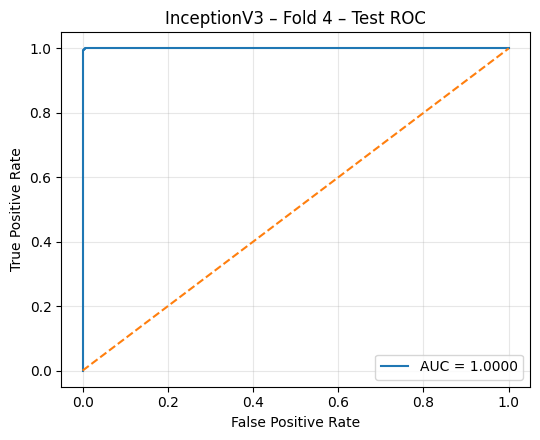

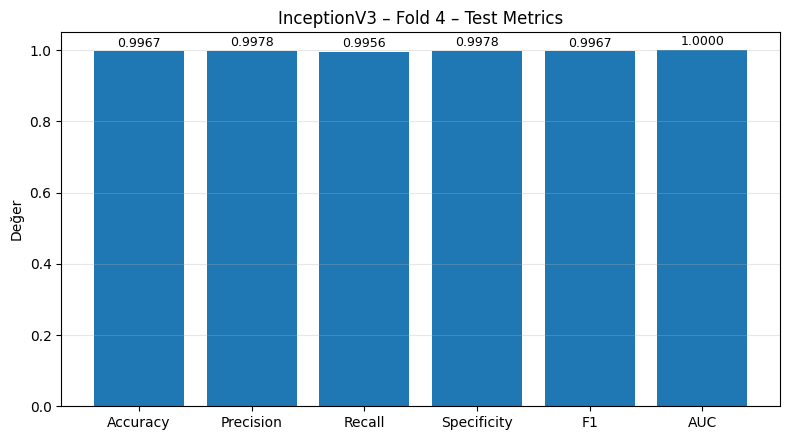

InceptionV3 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8411.0,2.0,8.0,8405.0,0.999406,0.999762,0.999049,0.999762,0.999405,0.999997,0.056311
Validation,3594.0,1791.0,6.0,8.0,1789.0,0.996105,0.996657,0.995548,0.996661,0.996102,0.999948,0.062243
Test,3604.0,1798.0,4.0,8.0,1794.0,0.996670,0.997775,0.995560,0.997780,0.996667,0.999979,0.060559


✓ InceptionV3 Fold 4: best epoch 10 | Test acc 0.9967
InceptionV3 | Fold 5 | Epoch 01/10 | Train loss 0.4161 acc 0.7916 | Val loss 0.2146 acc 0.9252
InceptionV3 | Fold 5 | Epoch 02/10 | Train loss 0.2318 acc 0.9106 | Val loss 0.1475 acc 0.9535
InceptionV3 | Fold 5 | Epoch 03/10 | Train loss 0.1610 acc 0.9485 | Val loss 0.1075 acc 0.9655
InceptionV3 | Fold 5 | Epoch 04/10 | Train loss 0.1287 acc 0.9627 | Val loss 0.0978 acc 0.9786
InceptionV3 | Fold 5 | Epoch 05/10 | Train loss 0.1033 acc 0.9768 | Val loss 0.0759 acc 0.9878
InceptionV3 | Fold 5 | Epoch 06/10 | Train loss 0.0887 acc 0.9840 | Val loss 0.0712 acc 0.9911
InceptionV3 | Fold 5 | Epoch 07/10 | Train loss 0.0761 acc 0.9893 | Val loss 0.0639 acc 0.9961
InceptionV3 | Fold 5 | Epoch 08/10 | Train loss 0.0671 acc 0.9932 | Val loss 0.0631 acc 0.9955
InceptionV3 | Fold 5 | Epoch 09/10 | Train loss 0.0654 acc 0.9941 | Val loss 0.0560 acc 0.9989
InceptionV3 | Fold 5 | Epoch 10/10 | Train loss 0.0602 acc 0.9964 | Val loss 0.0558 acc 0.9

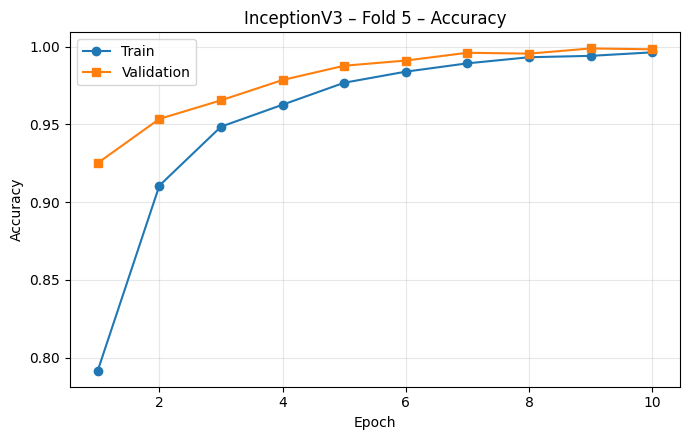

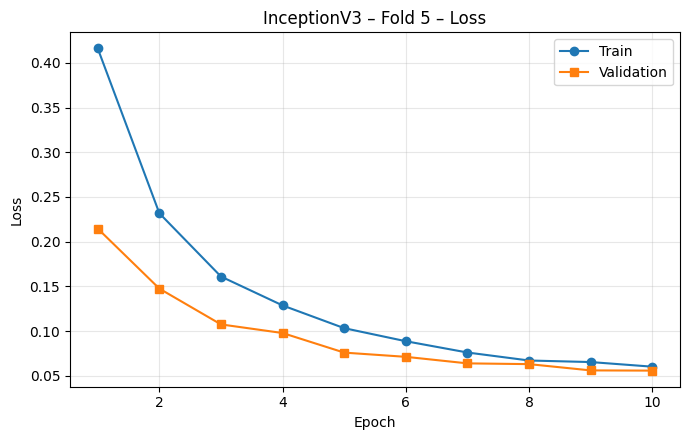

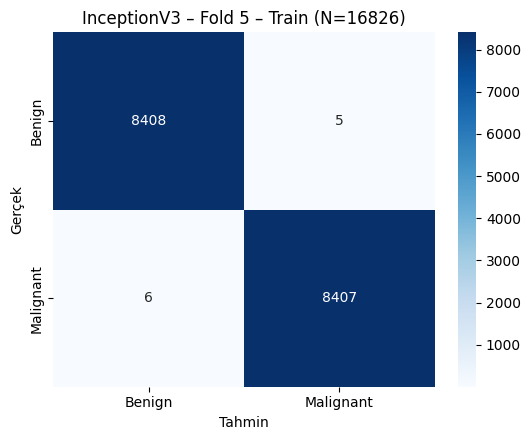

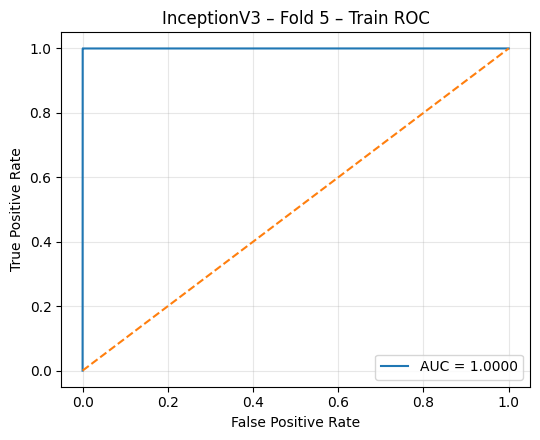

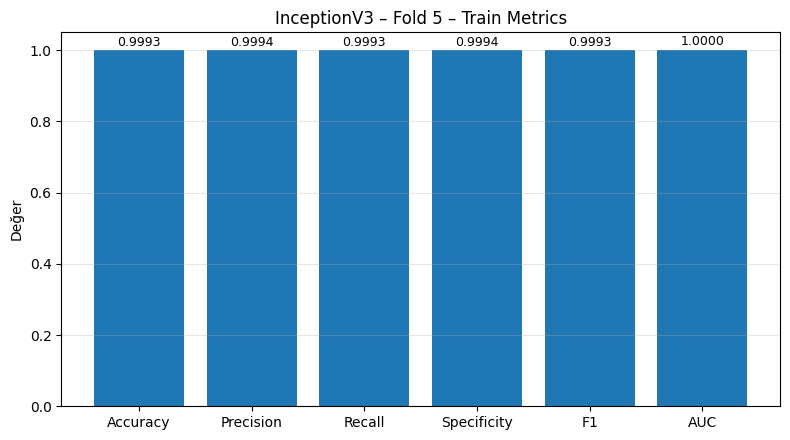

...

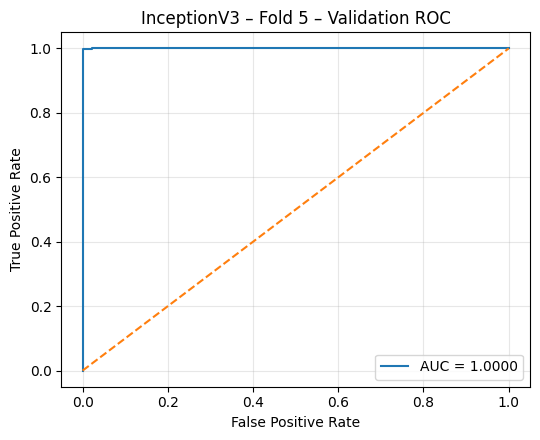

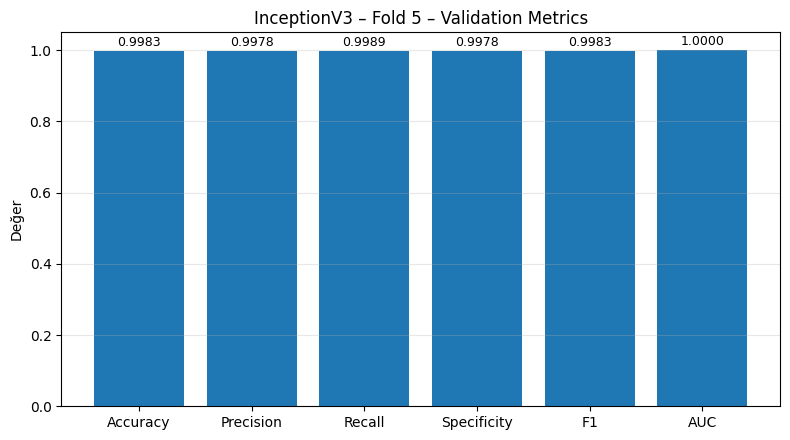

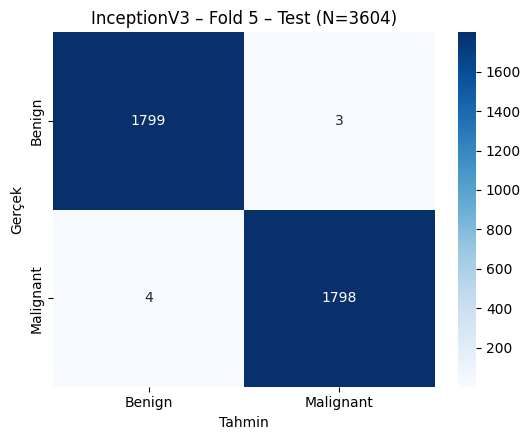

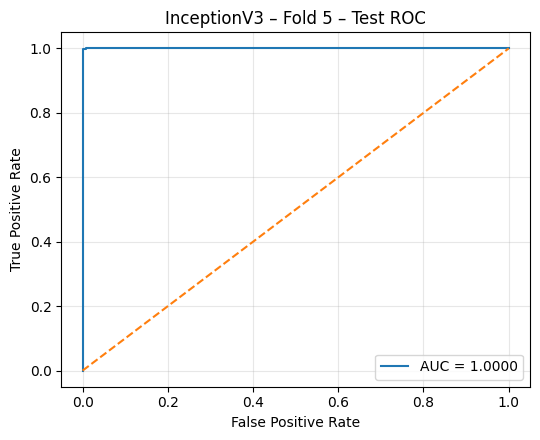

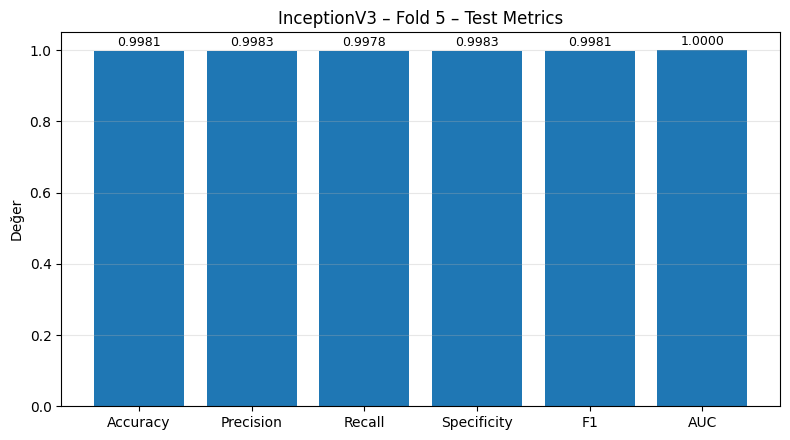

InceptionV3 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8408.0,5.0,6.0,8407.0,0.999346,0.999406,0.999287,0.999406,0.999346,0.999981,0.053029
Validation,3594.0,1793.0,4.0,2.0,1795.0,0.998331,0.997777,0.998887,0.997774,0.998331,0.999960,0.055808
Test,3604.0,1799.0,3.0,4.0,1798.0,0.998058,0.998334,0.997780,0.998335,0.998057,0.999976,0.056443


✓ InceptionV3 Fold 5: best epoch 10 | Test acc 0.9981


,Group,Model,Split,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC
2,optimized_cnn,ResNet34,Test,99.49 ± 0.13,99.69 ± 0.23,99.29 ± 0.28,99.69 ± 0.23,99.49 ± 0.13,99.98 ± 0.02
5,optimized_cnn,DenseNet121,Test,99.58 ± 0.10,99.76 ± 0.11,99.41 ± 0.12,99.76 ± 0.11,99.58 ± 0.10,99.97 ± 0.03
8,optimized_cnn,EfficientNet-B0,Test,99.22 ± 0.19,99.44 ± 0.34,98.99 ± 0.20,99.45 ± 0.34,99.22 ± 0.19,99.96 ± 0.03
11,optimized_cnn,MobileNetV2,Test,99.22 ± 0.10,99.45 ± 0.12,98.98 ± 0.22,99.46 ± 0.12,99.22 ± 0.10,99.97 ± 0.01
14,optimized_cnn,InceptionV3,Test,99.70 ± 0.07,99.74 ± 0.06,99.66 ± 0.14,99.74 ± 0.06,99.70 ± 0.07,99.99 ± 0.01


In [4]:
# ======================= 4. ÇALIŞTIR =======================
KIND, FAM = GROUP.split("_")
models_to_run = MODELS or (CNN_MODELS if FAM == "cnn" else VIT_MODELS)
assert all(FAMILY[m] == FAM for m in models_to_run), "Seçilen modeller gruba uymuyor"
if RERUN:   # etiket başına bir kez: MODELS=None ise gruptaki TÜM modeller, değilse sadece MODELS'tekiler
    marker = OUTPUT_ROOT / CV_MODE / GROUP / f"rerun_{RERUN}.done"
    if marker.exists():
        print(f"RERUN '{RERUN}' daha önce uygulanmış → silme YAPILMADI, kaldığı fold'dan devam ediliyor.")
    else:
        for m in models_to_run:
            d = OUTPUT_ROOT / CV_MODE / GROUP / m
            if d.exists():
                arc = OUTPUT_ROOT / CV_MODE / "_arsiv" / f"{GROUP}__{RERUN}" / m   # eski sonuçlar silinmez, arşive taşınır
                arc.parent.mkdir(parents=True, exist_ok=True); shutil.move(str(d), str(arc))
                print(f"Eski sonuçlar arşive taşındı ({arc}); yeniden eğitilecek: {m}")
        marker.parent.mkdir(parents=True, exist_ok=True)
        marker.write_text(f"{time.strftime('%Y-%m-%d %H:%M')} | silinen modeller: {', '.join(models_to_run)}\n")

(OUTPUT_ROOT / CV_MODE / GROUP).mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / CV_MODE / GROUP / "config.json").write_text(json.dumps({
    "GROUP": GROUP, "COMMON": COMMON, "RECIPE": RECIPES[KIND], "FT_SCOPE": FT_SCOPE[(KIND, FAM)],
    "AUGMENT": AUGMENT if RECIPES[KIND]["augment"] else None, "CV_MODE": CV_MODE, "N_FOLDS": N_FOLDS, "FOLD_SEED": FOLD_SEED, "TRAIN_SEED": TRAIN_SEED,
    "fold_counts": fold_table.to_dict("records"), "VIT_LAST_BLOCKS": VIT_LAST_BLOCKS,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "kaggle_split_counts": {s: len(d) for s, d in DS.items()}}, indent=2, default=str))

results = []
for name in models_to_run:
    for fold in range(1, N_FOLDS + 1):
        results.append(run_one(name, fold, KIND))

per_run, summary, article = results_to_frames(results)
with pd.ExcelWriter(OUTPUT_ROOT / CV_MODE / GROUP / f"{GROUP}_results.xlsx") as xw:
    per_run.to_excel(xw, sheet_name="Fold bazlı", index=False)
    summary.to_excel(xw, sheet_name="Ortalama-Std", index=False)
    article.to_excel(xw, sheet_name="Makale tablosu", index=False)
display(article[article.Split == "Test"])
